In [ ]:
import os

# Check if the current directory ends with 'data'
if os.getcwd()[-4:] != 'data':
    # Create the 'data' directory if it doesn't exist
    if not os.path.exists('data'):
        os.mkdir('data')

In [ ]:
import os
print(os.getcwd())

/content


In [ ]:
!git clone https://github.com/goldenhelper/helper_lib_repo.git

Cloning into 'helper_lib_repo'...
remote: Enumerating objects: 121, done.
remote: Counting objects: 100% (91/91), done.
remote: Compressing objects: 100% (91/91), done.
remote: Total 121 (delta 52), reused 0 (delta 0), pack-reused 30 (from 1)
Receiving objects: 100% (121/121), 25.74 MiB | 9.82 MiB/s, done.
Resolving deltas: 100% (55/55), done.


In [ ]:
!ls

data  helper_lib_repo  sample_data


In [ ]:
import sys
sys.path.append('/content/helper_lib_repo/')

In [ ]:
from helper_lib import *

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import numpy as np
# Load and preprocess MNIST data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

mnist_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_test = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)
test_loader = DataLoader(mnist_test, batch_size=64, shuffle=False)

class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3)
        self.conv2 = nn.Conv2d(32, 64, 3)
        self.conv3 = nn.Conv2d(64, 64, 3)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(576, 64)
        self.fc2 = nn.Linear(64, 10)

        # is needed for other functions
        self.input_shape = (1, 1, 28, 28)


    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = torch.relu(self.conv3(x))
        x = torch.flatten(x, 1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 9912422/9912422 [00:10<00:00, 904412.87it/s] 


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 28881/28881 [00:00<00:00, 56377.64it/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 1648877/1648877 [00:01<00:00, 1065129.54it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 403: Forbidden



100%|██████████| 4542/4542 [00:00<00:00, 9189835.39it/s]

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

mnist_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_test = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(mnist_train, batch_size=128, shuffle=True)
test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

file_path_cnn = 'data/cnn_model.pth'
helper_lib_cnn_path = "helper_lib_repo/data/cnn_model.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cnn_model = CNNModel().to(DEVICE)
train_new_cnn = False

if os.path.exists(file_path_cnn):
    print(DEVICE)
    cnn_model.load_state_dict(torch.load(file_path_cnn, map_location=DEVICE))
elif not train_new_cnn:
    cnn_model.load_state_dict(torch.load(helper_lib_cnn_path, map_location=DEVICE))
else:
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(cnn_model.parameters())

    num_epochs = 20
    cnn_model.to(DEVICE)

    for epoch in range(num_epochs):
        cnn_model.train()
        running_loss = 0.0
        for batch_idx, (data, target) in enumerate(train_loader):
            data, target = data.to(DEVICE), target.to(DEVICE)

            # Forward pass
            outputs = cnn_model(data)
            loss = criterion(outputs, target)

            # Backward pass and optimize
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            if (batch_idx + 1) % 100 == 0:
                print(f'Epoch [{epoch+1}/{num_epochs}], Step [{batch_idx+1}/{len(train_loader)}], '
                    f'Loss: {running_loss/100:.4f}')
                running_loss = 0.0

        # Validation
        cnn_model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for data, target in test_loader:
                data, target = data.to(DEVICE), target.to(DEVICE)
                outputs = cnn_model(data)
                _, predicted = torch.max(outputs.data, 1)
                total += target.size(0)
                correct += (predicted == target).sum().item()

        print(f'Epoch [{epoch+1}/{num_epochs}], '
            f'Validation Accuracy: {100 * correct / total:.2f}%')

    torch.save(cnn_model.state_dict(), file_path_cnn)


layer_shapes = save_layer_shapes(cnn_model) # note that the shapes are being stored as attributes of the layers


<ipython-input-8-4fd48c29de1a>:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  cnn_model.load_state_dict(torch.load(helper_lib_cnn_path, map_location=DEVICE))


In [ ]:
# Function to get activations of the last layer
def activations_from_whole_dataset(model, loader, output_device, compute_labels=False):
    model.eval()
    activations = []
    labels = []
    with torch.no_grad():
        for data, targets in loader:
            output = model(data.to(DEVICE))
            activations.append(output.to(output_device))
            if compute_labels:
                labels.append(targets)
    if compute_labels:
        return torch.cat(activations), torch.cat(labels)
    else:
        return torch.cat(activations)

In [ ]:
reference_train_loader = DataLoader(mnist_train, batch_size=128, shuffle=False)
reference_test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)


In [ ]:
# import os
# ref_activations_labels_path = "data/ref_activations_labels.pth"

# if os.path.exists(ref_activations_labels_path):
#     loaded_tensors = torch.load(f=ref_activations_labels_path, map_location=DEVICE)
#     reference_train_activations = loaded_tensors['ref_tr_activations']
#     reference_train_labels = loaded_tensors['ref_tr_labels']

#     reference_test_activations = loaded_tensors['ref_te_activations']
#     reference_test_labels = loaded_tensors['ref_te_labels']

# else:
#     store_activations(cnn_model.fc2, 'activations')
#     reference_train_activations = get_layer_activations_from_dataset(cnn_model,
#                                                                     layers={'fc2': cnn_model.fc2},
#                                                                     loader=reference_train_loader,
#                                                                     output_device=DEVICE,
#                                                                     mode='activations')

#     with torch.no_grad():
#         reference_train_labels = []
#         for _, labels in reference_train_loader:
#             reference_train_labels.append(labels)

#         reference_train_labels = torch.cat(reference_train_labels)

#     reference_test_activations = get_layer_activations_from_dataset(cnn_model,
#                                                                     layers={'fc2': cnn_model.fc2},
#                                                                     loader=reference_test_loader,
#                                                                     output_device=DEVICE,
#                                                                     mode='activations')

#     with torch.no_grad():
#         reference_test_labels = []
#         for _, labels in reference_test_loader:
#             reference_test_labels.append(labels)

#         reference_test_labels = torch.cat(reference_test_labels)

#     torch.save({'ref_tr_activations': reference_train_activations,
#                 'ref_tr_labels': reference_train_labels,
#                 'ref_te_activations': reference_test_activations,
#                 'ref_te_labels': reference_test_labels},
#                 f=ref_activations_labels_path)

In [ ]:
# mnist_by_digit_lists = [[] for _ in range(10)]

# # Iterate over the dataset and append images to the corresponding list
# for image, label in mnist_train:
#     mnist_by_digit_lists[label].append(image)

In [ ]:
# # Get activations from the CNN model
# train_activations = activations_from_whole_dataset(cnn_model, train_loader, output_device='cpu')
# test_activations = activations_from_whole_dataset(cnn_model, test_loader, output_device='cpu')

# # Create datasets and dataloaders for the activations
# train_dataset_SAE = TensorDataset(torch.FloatTensor(train_activations))
# test_dataset_SAE = TensorDataset(torch.FloatTensor(test_activations))
# train_loader_SAE = DataLoader(train_dataset_SAE, batch_size=128, shuffle=True)
# test_loader_SAE = DataLoader(test_dataset_SAE, batch_size=128, shuffle=False)

In [ ]:
# Hyperparameters
input_size = 10  # Size of the last layer of CNN (10 for MNIST)
hidden_size = 20
learning_rate_sae = 1e-3
num_epochs_sae = 50
sparsity_weight_sae = 1e-5

file_path_sae = 'data/sparse_autoencoder_mnist.pth'
helper_lib_sae_path = 'helper_lib_repo/data/sparse_autoencoder_mnist.pth'
train_new_sae = False

sae = SparseAutoencoder(input_size, hidden_size).to(DEVICE)

if os.path.exists(file_path_sae):
    sae.load_state_dict(torch.load(file_path_sae, map_location=DEVICE))
elif not train_new_sae:
    sae.load_state_dict(torch.load(helper_lib_sae_path, map_location=DEVICE))
else:
    sae = SparseAutoencoder(input_size, hidden_size).to(DEVICE)
    train_sae(sae, activations_to_train_on=reference_train_activations)

    # Save the model
    torch.save(sae.state_dict(), file_path_sae)

sae.eval()

save_layer_shapes(sae, get_output_shape=lambda x: x[-1])

<ipython-input-11-f7e44f5c9575>:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sae.load_state_dict(torch.load(helper_lib_sae_path, map_location=DEVICE))


{'encoder': (torch.Size([1, 10]), torch.Size([1, 20])),
 'decoder': (torch.Size([1, 20]), torch.Size([1, 10]))}

In [ ]:
# both, only_cnn, only_rec, neither = ([] for i in range(4))

# with torch.no_grad():
#   for i in range(len(reference_train_activations)):
#     cnn_activations, y = reference_train_activations[i], reference_train_labels[i]

#     reconstructed_cnn_activations = sae(cnn_activations)[-1].detach().cpu()

#     prediction = torch.argmax(cnn_activations).item()
#     rec_prediction = torch.argmax(reconstructed_cnn_activations).item()

#     # print(f"activations = {cnn_activations}")
#     # print(f"y = {y}")
#     # print(f"prediction = {prediction}")

#     if prediction == y:
#       if rec_prediction == y:
#         both.append(i)
#       else:
#         only_cnn.append(i)
#     else:
#       if rec_prediction == y:
#         only_rec.append(i)
#       else:
#         neither.append(i)

In [ ]:
# # cases where both the prediction from cnn and the reconstruction are correct
# print(len(both))

In [ ]:
# # cases where only the prediction is correct
# print(len(only_cnn))

In [ ]:
# # cases where the prediction from cnn is incorrect but the reconstruction correctly classifies the digit
# print(len(only_rec))

In [ ]:
# # cases where both are wrong
# print(len(neither))

In [ ]:
# max_activations_list = [[] for i in range(hidden_size)]

In [ ]:
# with torch.no_grad():
#   for i in range(len(reference_train_activations)):
#     sparse_representation = sae(reference_train_activations[i].to(DEVICE))[0] # activations of the middle layer of the SAE
#     max_activations_list[torch.argmax(sparse_representation)].append(i)

In [ ]:
# for l in max_activations_list:
#   print(f"Was the neuron with max activation for {len(l)} examples.")

In [ ]:
# visualize(max_activations_list[0][:225], dataset=mnist_train)

In [ ]:
# combo_model = nn.Sequential(cnn_model, sae)
# combo_model.input_shape = (1, 1, 28, 28)

In [ ]:
import torch.nn.functional as F

def test(model, epsilon, loader, device=DEVICE, *, to_store_init_data=False, include_unsuccessful_adversarial=False):

    # Accuracy counter

    correct = 0
    adv_examples = []

    # Loop over all examples in test set
    for data, targets in loader:

        # Set requires_grad attribute of tensor. Important for Attack
        data = data.to(device)
        targets = targets.to(device)
        data.requires_grad = True
        # Forward pass the data through the model
        output = model(data)

        init_preds = output.max(1)[1] # get the index of the max

        num_to_store = 60_000

        if epsilon != 0:
        # Calculate the loss
            vectorized_targets = torch.eye(10).to(device)[targets]
            loss = F.mse_loss(output, vectorized_targets)

            # Zero all existing gradients
            model.zero_grad()

            # Calculate gradients of model in backward pass
            loss.backward()

            # Collect ``datagrad``
            data_grad = data.grad.data

            # Call FGSM Attack
            perturbed_data = fgsm_attack(data, epsilon, data_grad).to(device)

            # Re-classify the perturbed image
            output = model(perturbed_data)

            # Check for success
            final_preds = output.max(1)[1] # get the index of the max log-probability
            # shape: (B,)

            with torch.no_grad():
                correct += torch.sum(final_preds == targets)

                if len(adv_examples) < num_to_store:
                    adv_ex_batch = perturbed_data.squeeze(0).cpu()    # shape: data.shape

                    mask = ((init_preds == targets) & (final_preds != targets)).cpu()

                    examples_to_add = num_to_store

                    # Common elements to include in both cases
                    tuple_to_zip = [
                        init_preds[mask][:examples_to_add//2],
                        final_preds[mask][:examples_to_add//2],
                        adv_ex_batch[mask][:examples_to_add//2],
                    ]

                    # Add data only if `to_store_init_data` is False
                    if to_store_init_data:
                        tuple_to_zip.append(data[mask][:examples_to_add//2])

                    # Extend `adv_examples` with the appropriate elements
                    adv_examples.extend(zip(*tuple_to_zip))

                    if include_unsuccessful_adversarial:
                        unsuccessful_adv_mask = ((init_preds == targets) & (final_preds == targets)).cpu()
                        tuple_to_zip_2 = [
                            init_preds[unsuccessful_adv_mask][:examples_to_add//2],
                            final_preds[unsuccessful_adv_mask][:examples_to_add//2],
                            adv_ex_batch[unsuccessful_adv_mask][:examples_to_add//2],
                        ]
                        if to_store_init_data:
                            tuple_to_zip_2.append(data[unsuccessful_adv_mask][:examples_to_add//2])

                        # adv_examples.extend(zip(*tuple_to_zip_2))
                        adv_examples += [*zip(*tuple_to_zip_2)]


        else: # epsilon == 0
            with torch.no_grad():
                mask = (init_preds == targets).cpu()
                correct += torch.sum(mask)
                # Special case for saving 0 epsilon examples

                if len(adv_examples) < num_to_store:
                    data = data.squeeze(0).cpu().numpy()
                    examples_to_add = num_to_store

                    # Common elements to include in both cases
                    tuple_to_zip = [
                        init_preds[mask][:examples_to_add],
                        init_preds[mask][:examples_to_add], # == 'final_preds'
                        data[mask][:examples_to_add]
                    ]

                    if to_store_init_data:
                        tuple_to_zip.append(init_preds[mask][:examples_to_add]) # note: inefficient, done to have the same structure as in the eps != 0 case.


                    # Extend `adv_examples` with the appropriate elements
                    adv_examples.extend(zip(*tuple_to_zip))

                    if include_unsuccessful_adversarial:
                        unsuccessful_adv_mask = (init_preds == targets).cpu()
                        tuple_to_zip_2 = [
                            init_preds[unsuccessful_adv_mask][:examples_to_add],
                            init_preds[unsuccessful_adv_mask][:examples_to_add],
                            data[unsuccessful_adv_mask][:examples_to_add],
                        ]
                        if to_store_init_data:
                            tuple_to_zip_2.append(init_preds[unsuccessful_adv_mask][:examples_to_add])

                        adv_examples.extend(zip(*tuple_to_zip_2))


    # Calculate final accuracy for this epsilon
    final_acc = correct/float(len(loader) * loader.batch_size)
    print(f"Epsilon: {epsilon}\tTest Accuracy = {correct} / {len(loader) * loader.batch_size} = {final_acc}")

    # Return the accuracy and an adversarial example
    return final_acc.item(), adv_examples

In [ ]:
accuracies = []
examples = []
epsilons = np.arange(10) / 10.0

torch.manual_seed(42)
# Run test for each epsilon
for eps in epsilons:
    acc, ex = fgsm_test(cnn_model, epsilon=eps, loader=reference_test_loader, device=DEVICE, num_to_store=1000**2, to_store_init_data=True)
    accuracies.append(acc)
    examples.append(ex)

Epsilon: 0.0	Test Accuracy = 9913 / 10112 = 0.980320394039154
Epsilon: 0.1	Test Accuracy = 9889 / 10112 = 0.9779469966888428
Epsilon: 0.2	Test Accuracy = 9885 / 10112 = 0.9775514602661133
Epsilon: 0.3	Test Accuracy = 9886 / 10112 = 0.9776503443717957
Epsilon: 0.4	Test Accuracy = 9886 / 10112 = 0.9776503443717957
Epsilon: 0.5	Test Accuracy = 9872 / 10112 = 0.9762658476829529
Epsilon: 0.6	Test Accuracy = 9850 / 10112 = 0.9740902185440063
Epsilon: 0.7	Test Accuracy = 9799 / 10112 = 0.9690467119216919
Epsilon: 0.8	Test Accuracy = 9587 / 10112 = 0.9480814933776855
Epsilon: 0.9	Test Accuracy = 9160 / 10112 = 0.9058544635772705


In [ ]:
import copy
from itertools import groupby

# Copying the examples list
sorted_examples = copy.copy(examples)
# tuples_list == ex
key = lambda tupl: tupl[:2]
sorted_examples = [sorted(tuples_list, key=key) for tuples_list in examples]

grouped = [
    {(k[0].item(), k[1].item()): [(tup[3], tup[2]) for tup in g] for k, g in groupby(tuples_list, key=key)}
    for tuples_list in sorted_examples
]

(0, 3):


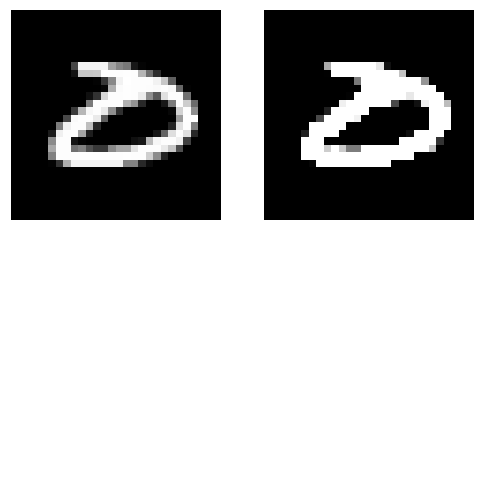

(0, 4):


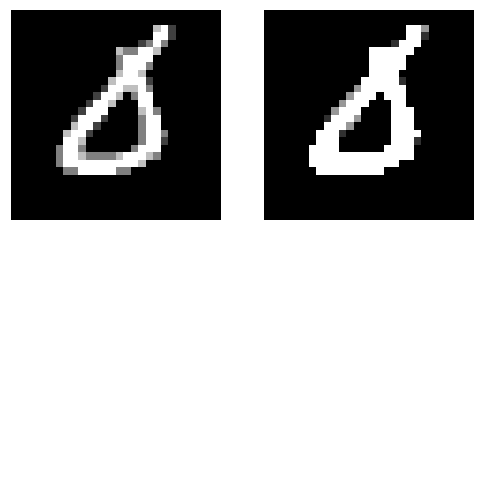

(0, 6):


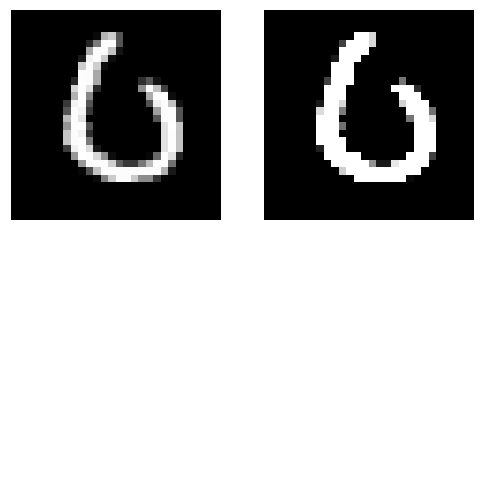

(1, 3):


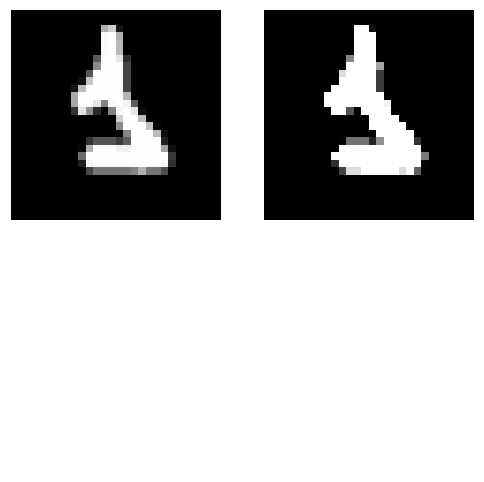

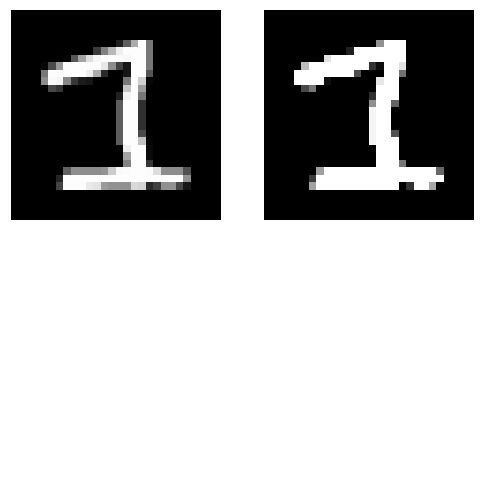

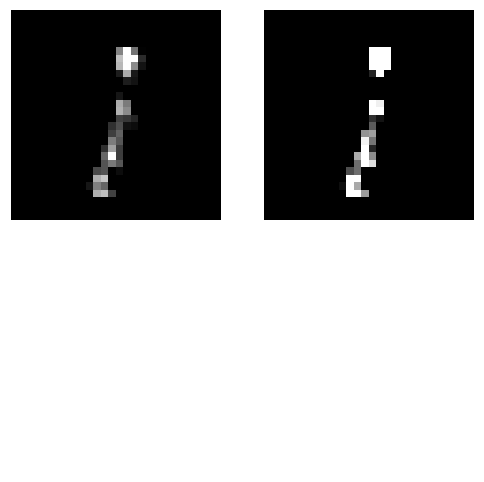

(1, 4):


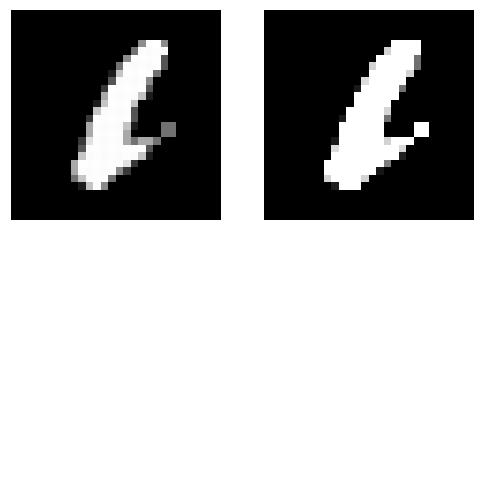

(1, 7):


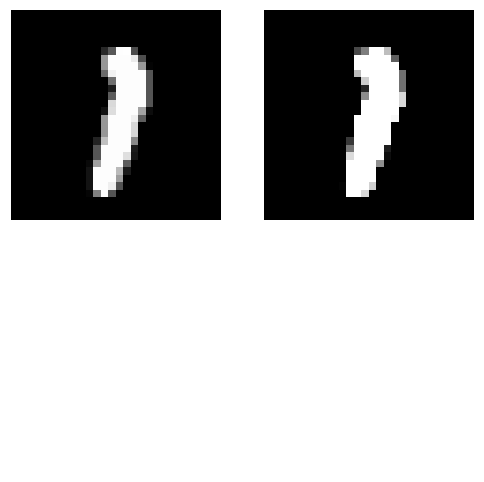

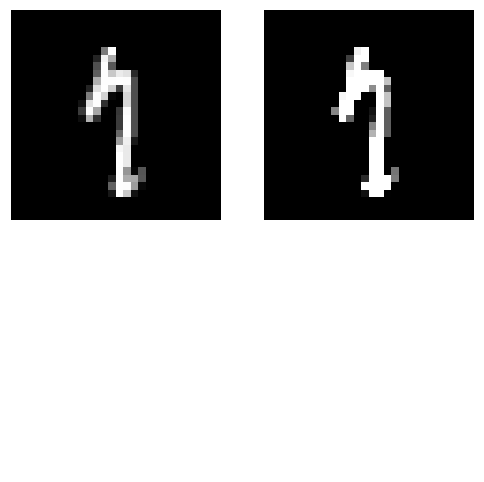

(1, 9):


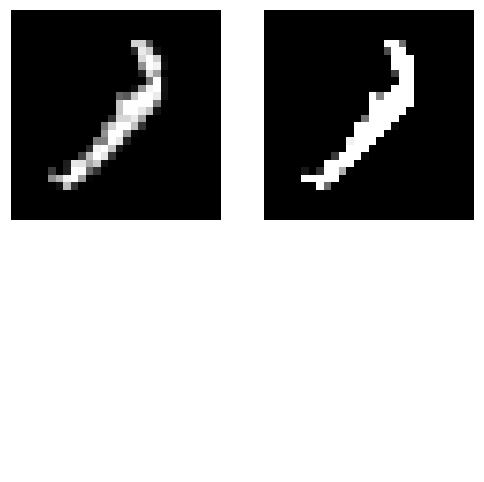

(2, 3):


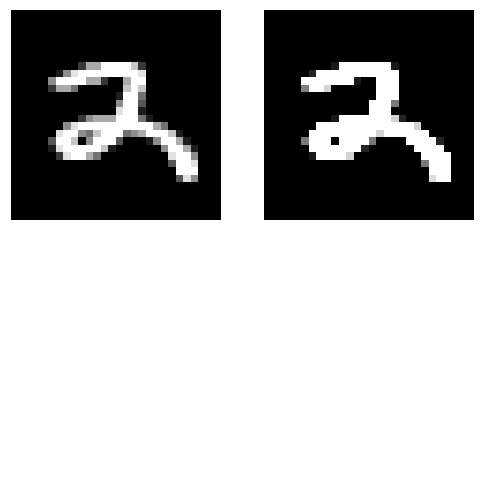

(2, 4):


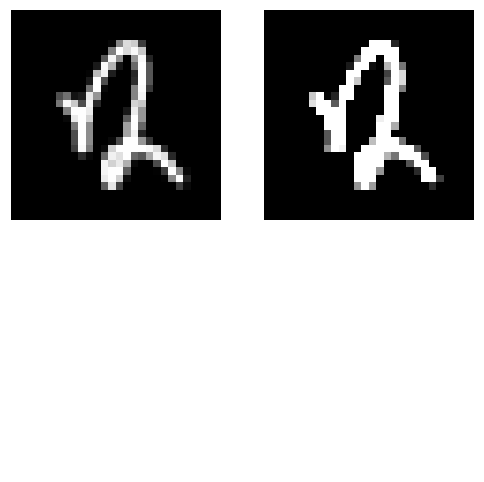

(2, 7):


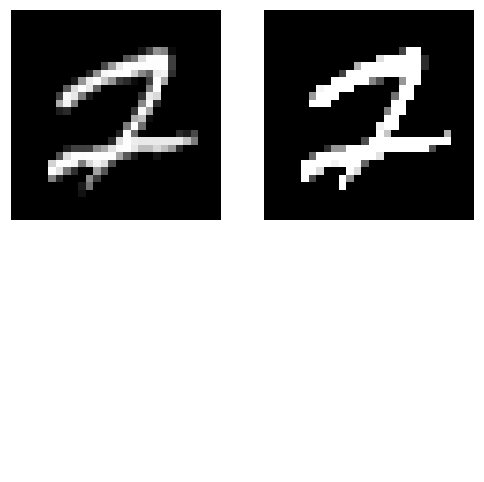

(4, 6):


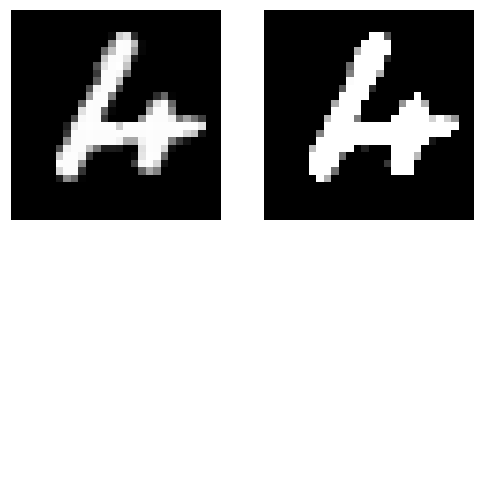

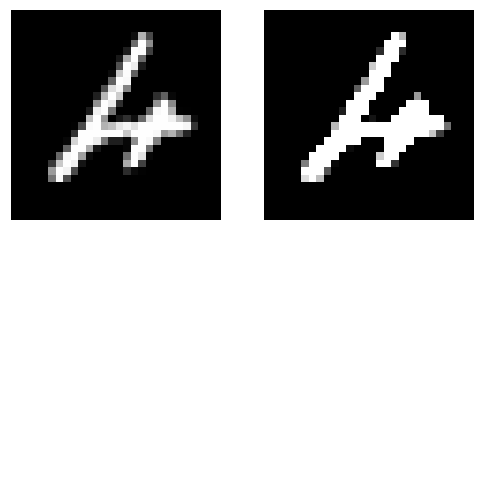

(4, 9):


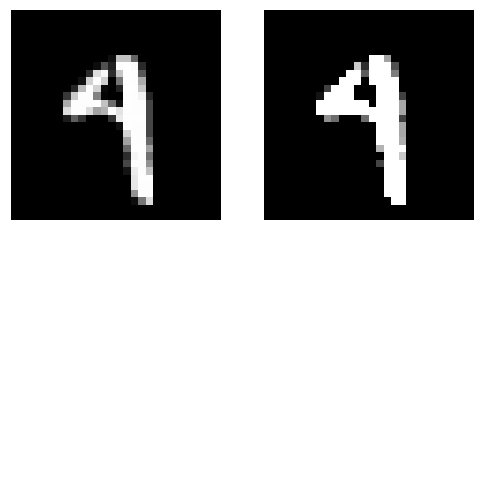

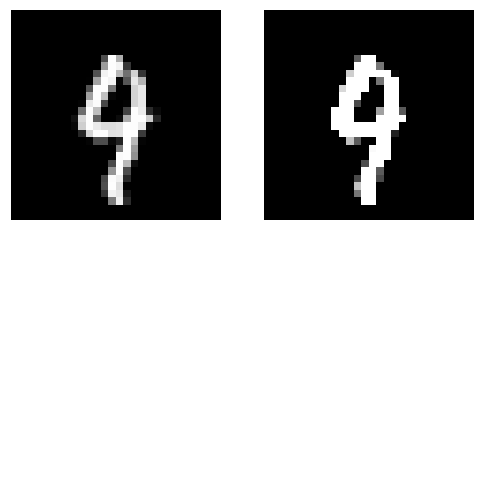

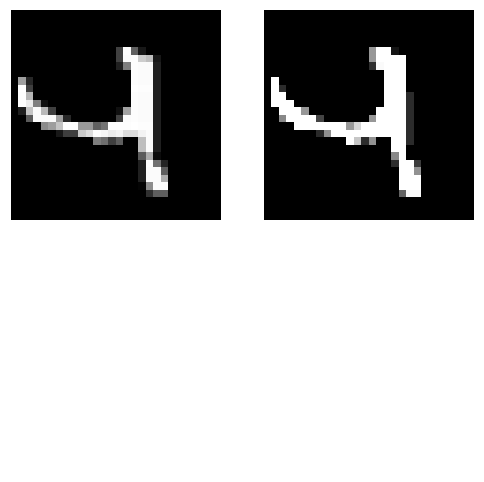

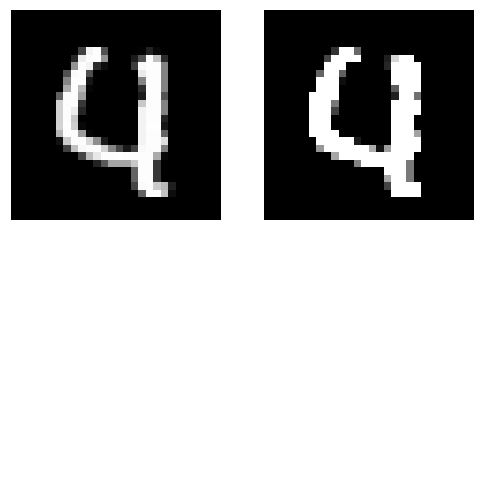

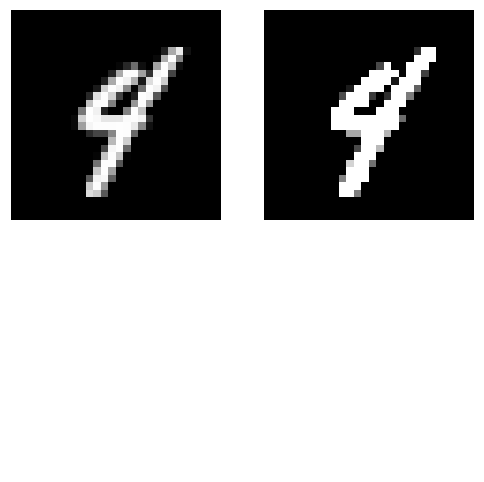

(5, 3):


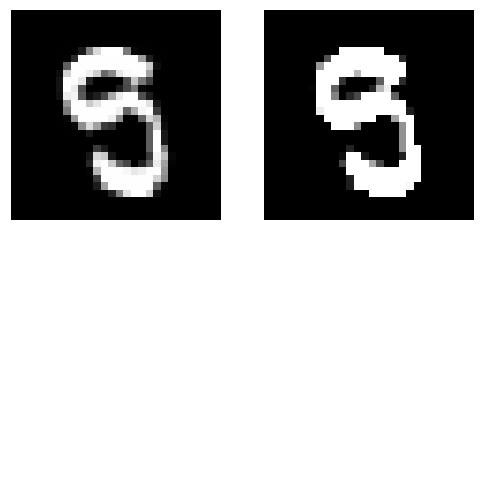

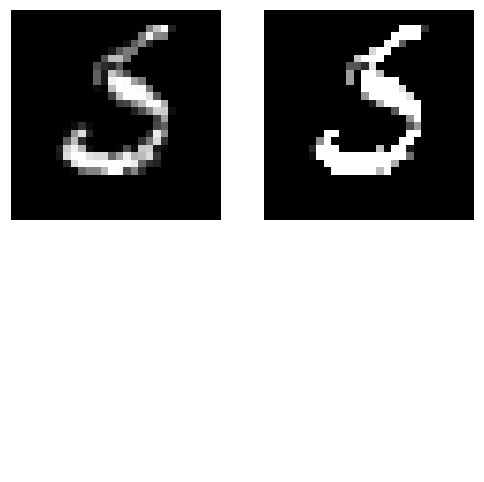

(6, 0):


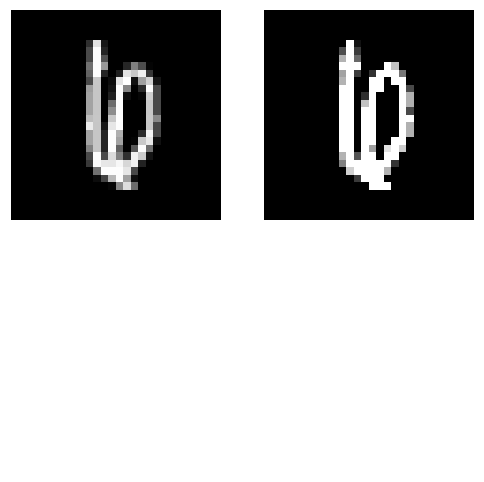

(6, 4):


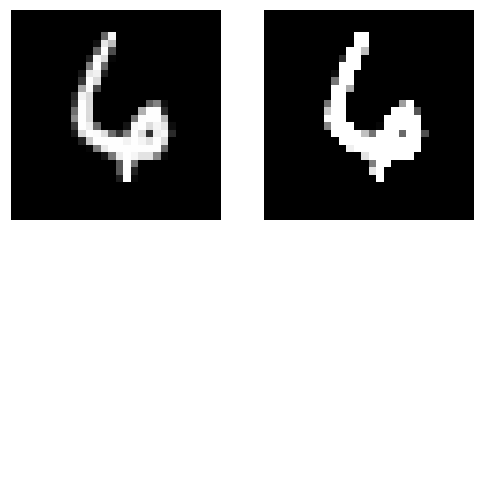

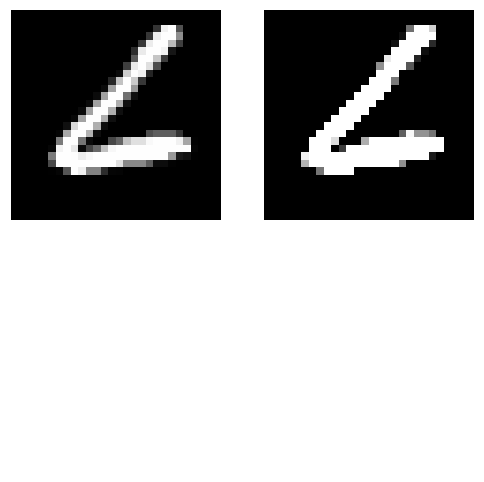

(6, 5):


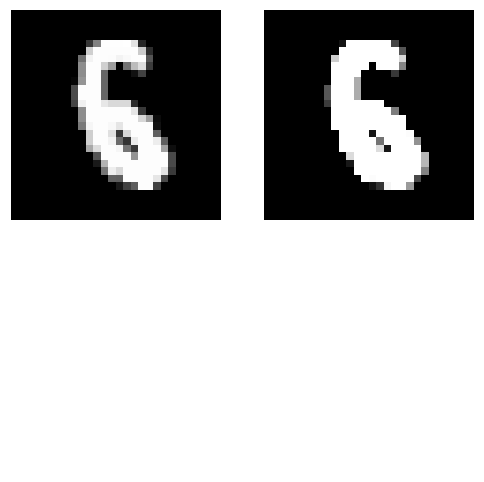

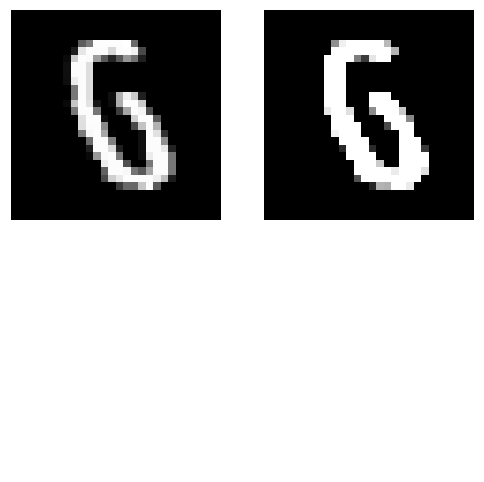

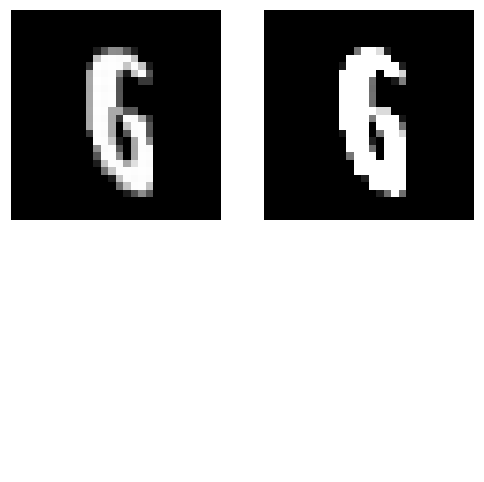

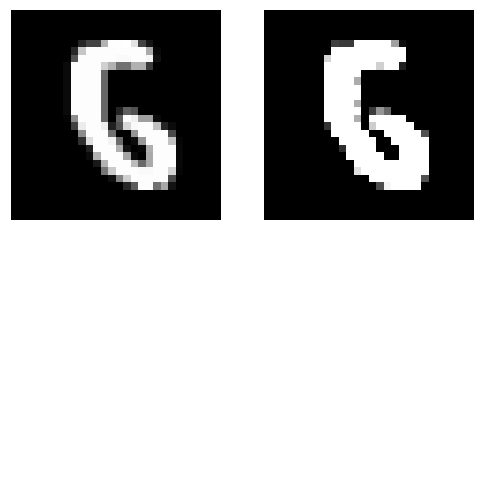

(7, 2):


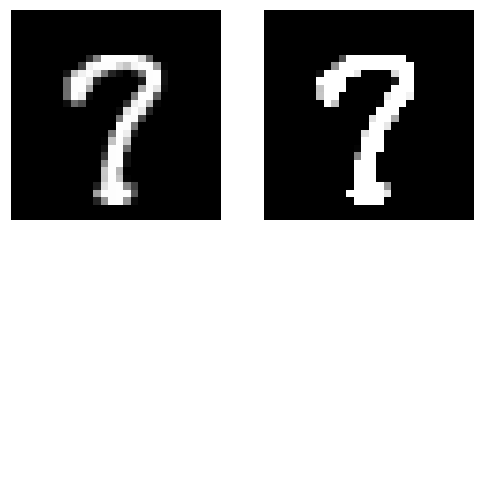

(7, 9):


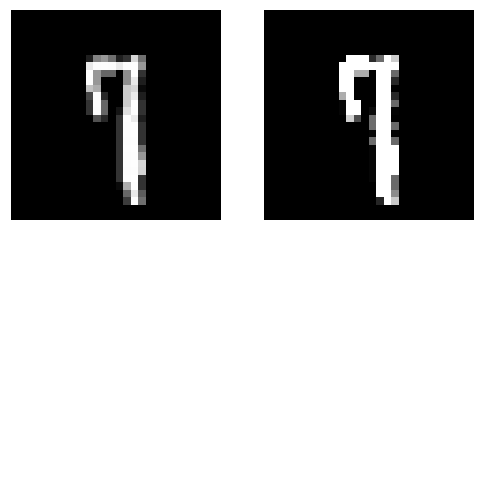

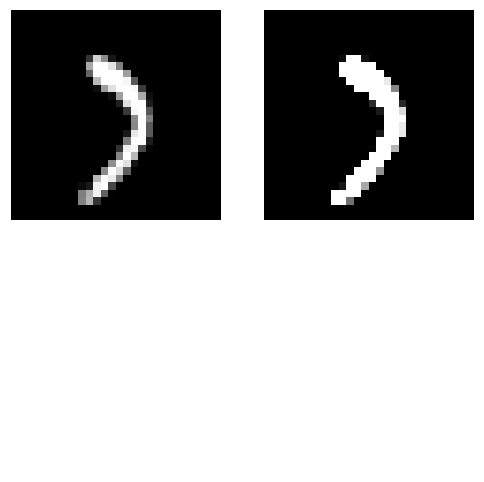

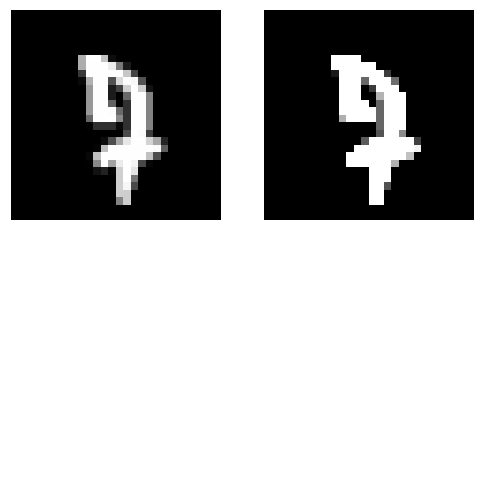

(8, 3):


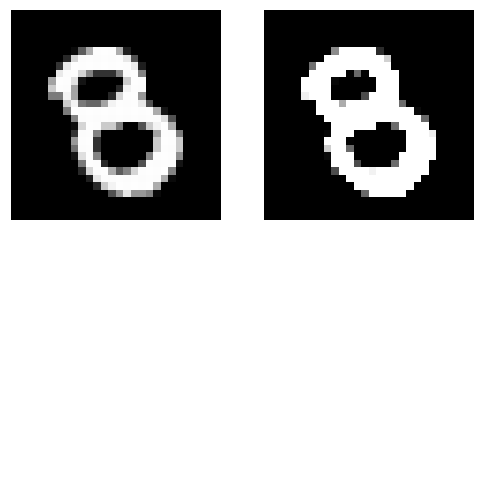

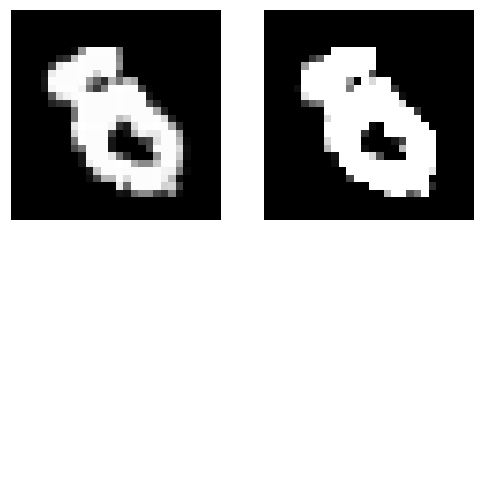

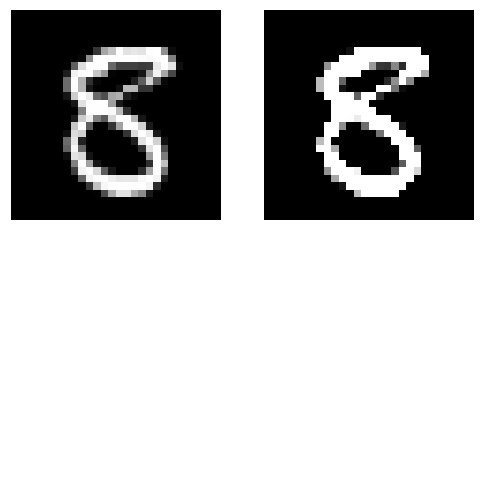

(8, 5):


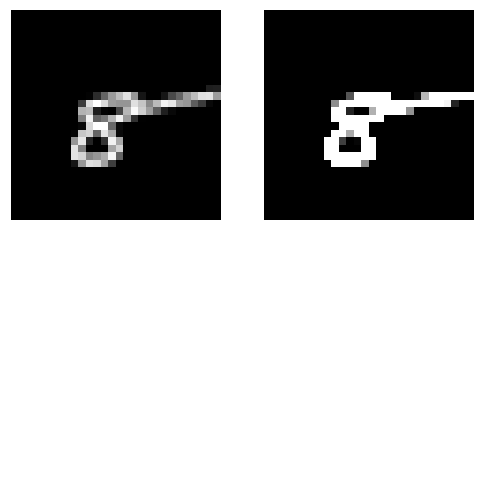

(8, 7):


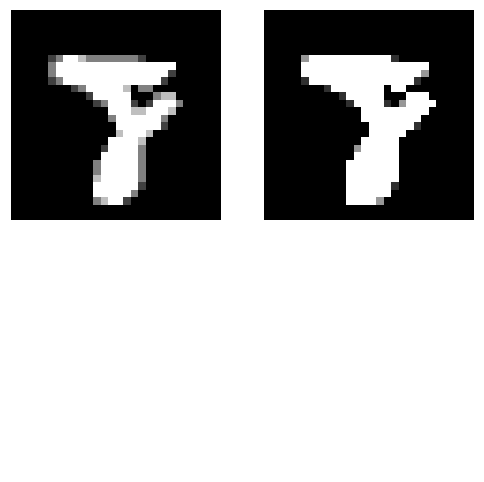

(8, 9):


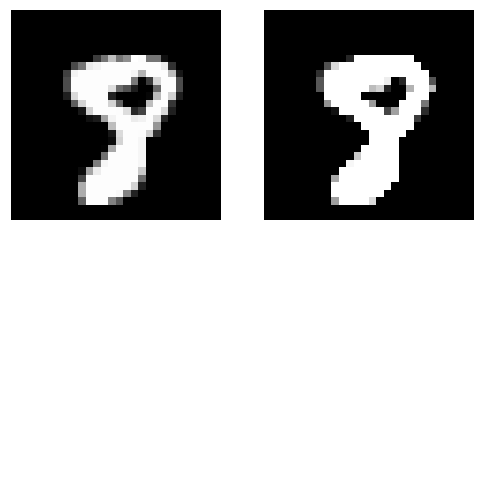

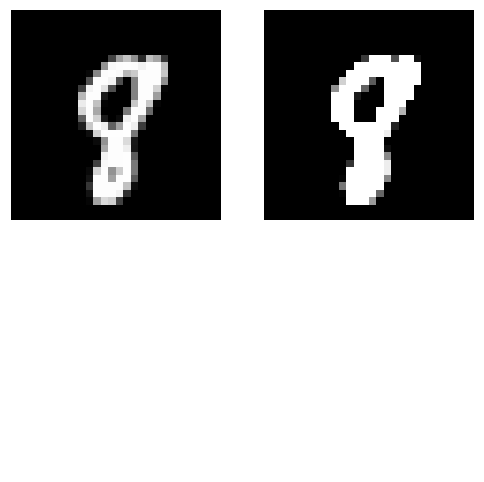

(9, 3):


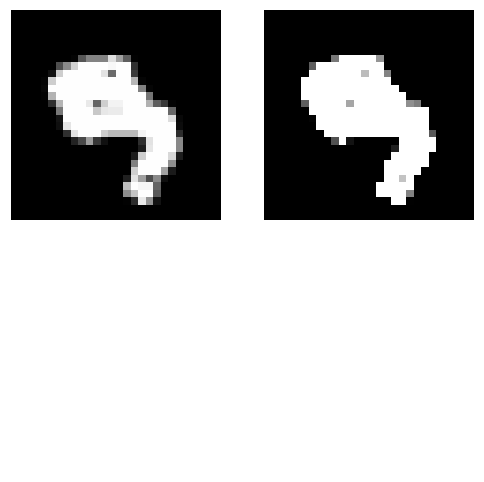

(9, 4):


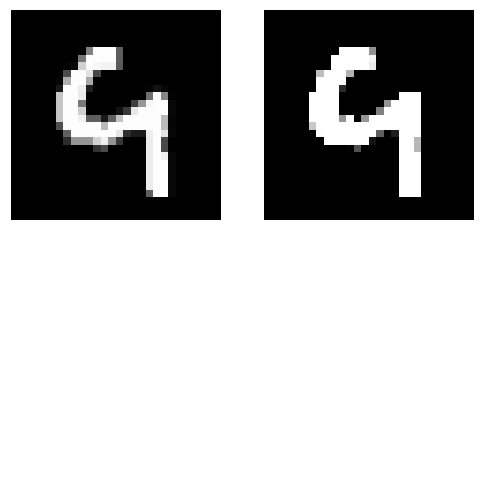

(9, 5):


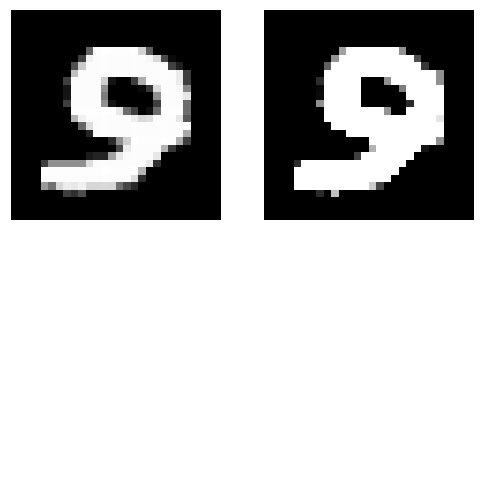

(9, 8):


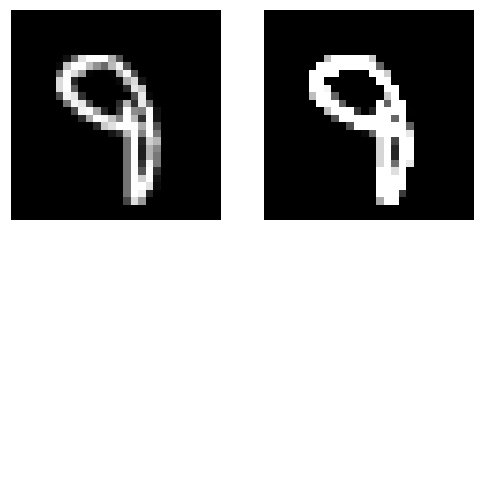

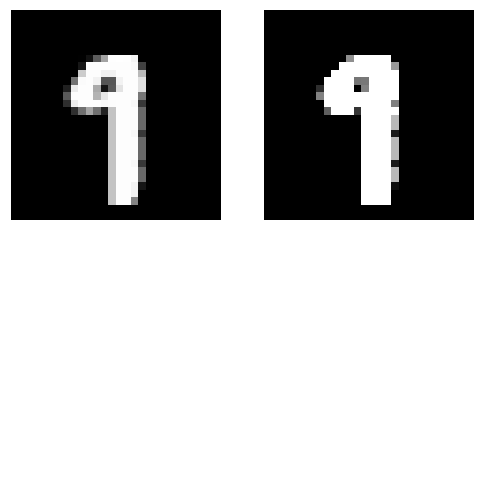

In [ ]:
for key, values in grouped[2].items():
   print(f"{key}:")
   for ex in values:
      visualize_ims(ex, channel=0, cmap='gray', norm=None)

In [ ]:
for key, values in grouped[2].items():
   print(f"{key} was seen {len(values)} times")

(0, 3) was seen 1 times
(0, 4) was seen 1 times
(0, 6) was seen 1 times
(1, 3) was seen 3 times
(1, 4) was seen 1 times
(1, 7) was seen 2 times
(1, 9) was seen 1 times
(2, 3) was seen 1 times
(2, 4) was seen 1 times
(2, 7) was seen 1 times
(4, 6) was seen 2 times
(4, 9) was seen 5 times
(5, 3) was seen 2 times
(6, 0) was seen 1 times
(6, 4) was seen 2 times
(6, 5) was seen 4 times
(7, 2) was seen 1 times
(7, 9) was seen 3 times
(8, 3) was seen 3 times
(8, 5) was seen 1 times
(8, 7) was seen 1 times
(8, 9) was seen 2 times
(9, 3) was seen 1 times
(9, 4) was seen 1 times
(9, 5) was seen 1 times
(9, 8) was seen 2 times


In [ ]:
eps_idx = 7

In [ ]:
# data is a list of tensors for each epsilon, where tensor is sorted and has shape (num_to_store, 2). At dim=-1, you can find torch.tensor([init_pred, final_pred])
data = [torch.stack([torch.tensor(tup[:2]) for tup in tuples_list]) for tuples_list in sorted_examples]

for pair in data[eps_idx]:
  init_pred, final_pred = pair[0], pair[1]
  print(f"{init_pred} -> {final_pred}")


0 -> 2
0 -> 4
0 -> 4
0 -> 5
0 -> 5
0 -> 5
0 -> 5
0 -> 5
0 -> 6
0 -> 6
0 -> 8
0 -> 8
0 -> 9
0 -> 9
0 -> 9
1 -> 2
1 -> 3
1 -> 3
1 -> 3
1 -> 3
1 -> 3
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 4
1 -> 5
1 -> 5
1 -> 6
1 -> 7
1 -> 7
1 -> 7
1 -> 7
1 -> 7
1 -> 7
1 -> 8
1 -> 8
1 -> 8
1 -> 8
1 -> 8
1 -> 8
1 -> 8
1 -> 8
1 -> 9
1 -> 9
1 -> 9
2 -> 3
2 -> 4
2 -> 7
2 -> 7
3 -> 5
3 -> 5
3 -> 5
3 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
4 -> 9
5 -> 3
5 -> 3
6 -> 0
6 -> 4
6 -> 5
6 -> 5
6 -> 5
6 -> 5
6 -> 5
6 -> 5
6 -> 5
6 -> 5
6 -> 8
7 -> 2
7 -> 2
7 -> 2
7 -> 2
7 -> 3
7 -> 3
7 -> 4
7 -> 4
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
7 -> 9
8 -> 3
8 -> 3
8 -> 3
8 -> 9
8 -> 9
9 -> 3
9 -> 4
9 -> 5
9 -> 5
9 -> 8


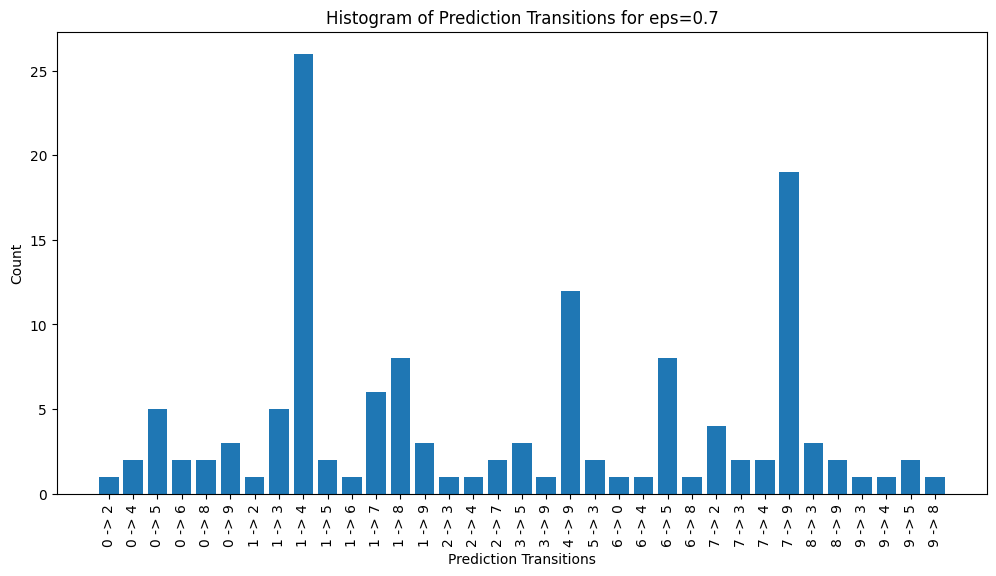

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter

# Convert tensors to tuples of integers for counting
pairs = [(int(pair[0].item()), int(pair[1].item())) for pair in data[eps_idx]]

# Count the occurrences of each (init_pred, final_pred) pair
pair_counts = Counter(pairs)

# Unzip the dictionary into two lists
pairs, counts = zip(*pair_counts.items())

# Prepare the data for plotting
x_labels = [f"{init} -> {final}" for init, final in pairs]

# Plot the histogram
plt.figure(figsize=(12, 6))
plt.bar(x_labels, counts)
plt.xticks(rotation=90)
plt.xlabel("Prediction Transitions")
plt.ylabel("Count")
plt.title(f"Histogram of Prediction Transitions for eps={epsilons[eps_idx]}")
plt.show()


In [ ]:
# plt.figure(figsize=(5,5))
# plt.plot(epsilons, accuracies, "*-")
# plt.yticks(np.arange(0, 1.1, step=0.1))
# plt.xticks(epsilons)
# plt.title("Accuracy vs Epsilon")
# plt.xlabel("Epsilon")
# plt.ylabel("Accuracy")
# plt.show()

In [ ]:
# # Plot several examples of adversarial samples at each epsilon
# cnt = 0
# plt.figure(figsize=(8,10))
# for i in range(len(epsilons)):
#     for j in range(len(examples[i])):
#         cnt += 1
#         plt.subplot(len(epsilons),len(examples[0]),cnt)
#         plt.xticks([], [])
#         plt.yticks([], [])
#         if j == 0:
#             plt.ylabel(f"Eps: {epsilons[i]}", fontsize=14)
#         orig, adv, ex, _ = examples[i][j]
#         plt.title(f"{orig} -> {adv}")
#         plt.imshow(ex.squeeze(), cmap="gray")
# plt.tight_layout()
# plt.show()

In [ ]:
# combo_model = nn.Sequential(cnn_model, sae)

In [ ]:
# sry, i erased some parts of code for easier scrolling, if you need them you can copy and paste them from version history

In [ ]:
import gdown

file_id = '1inTL36URuodiItvXmmhxAptAe41ATAcd'
if not os.path.exists('saes_dict.pth'):
  gdown.download(f'https://drive.google.com/uc?export=download&id={file_id}', 'saes_dict.pth', quiet=False)

Downloading...
From (original): https://drive.google.com/uc?export=download&id=1inTL36URuodiItvXmmhxAptAe41ATAcd
From (redirected): https://drive.google.com/uc?export=download&id=1inTL36URuodiItvXmmhxAptAe41ATAcd&confirm=t&uuid=6da4b6cb-9864-4b3d-ab4b-105686ebddad
To: /content/saes_dict.pth
100%|██████████| 2.21G/2.21G [01:06<00:00, 33.1MB/s]


In [ ]:
saes_dict = torch.load(f='saes_dict.pth', map_location=DEVICE)

<ipython-input-16-638d5536d98d>:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  saes_dict = torch.load(f='saes_dict.pth', map_location=DEVICE)


In [ ]:
for name, sae in saes_dict.items():
  print_registered_forward_hooks(sae, model_name=f"saes_dict['{name}']")

print("")
print_registered_forward_hooks(cnn_model, model_name='cnn_model')

NameError: name 'print_registered_forward_hooks' is not defined

In [ ]:
# remove_all_forward_hooks_old(cnn_model)

In [ ]:
named_children_dict = dict(cnn_model.named_children())
# deleting first and last layers
del named_children_dict['conv1']
del named_children_dict['fc2']

In [ ]:
named_children_dict

{'conv2': Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1)),
 'conv3': Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1)),
 'pool': MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False),
 'fc1': Linear(in_features=576, out_features=64, bias=True)}

In [ ]:
for name, child in named_children_dict.items():
    store_activations(child, hook_name='inputs', mode='inputs')

In [ ]:
reference_train_loader = DataLoader(mnist_train, batch_size=128, shuffle=False)
reference_test_loader = DataLoader(mnist_test, batch_size=128, shuffle=False)

In [ ]:
# saes_dict = {}

# for name, layer in named_children_dict.items(): # not including the first and the last layers
#     sae = create_sae(layer, device=DEVICE, mode='inputs')
#     saes_dict[name] = sae


# train_saes_in_batches(cnn_model,
#                     layers= named_children_dict,
#                     saes=saes_dict,
#                     loader_model=reference_train_loader,
#                     sparsity_weight=sparsity_weight_sae,
#                     learning_rate=learning_rate_sae,
#                     num_epochs=num_epochs_sae,
#                     device=DEVICE,
#                     mode='inputs')


In [ ]:
cnn_model(mnist_train[0][0].unsqueeze(0).to(DEVICE))

tensor([[-18.0225,  -9.8141, -34.3493,  10.0203, -28.7933,  24.0919, -14.4446,
         -23.1498, -10.0285,  -1.8420]], device='cuda:0',
       grad_fn=<AddmmBackward0>)

In [ ]:
torch.sum(torch.abs(cnn_model.fc1.stored_inputs.flatten()-saes_dict['fc1'](cnn_model.fc1.stored_inputs.flatten())[-1]))

tensor(560.4477, device='cuda:0', grad_fn=<SumBackward0>)

In [ ]:
torch.sum(cnn_model.fc1.stored_inputs)

tensor(622.6552, device='cuda:0', grad_fn=<SumBackward0>)

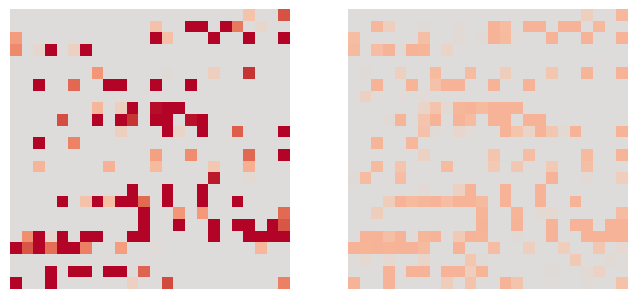

In [ ]:
cnn_model(mnist_train[np.random.randint(100)][0].unsqueeze(0).to(DEVICE))
fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
sae_rec = saes_dict['fc1'](fc1_stored_inps)[-1].detach()
imgs = torch.stack([fc1_stored_inps.reshape(1, 24, 24).cpu(), sae_rec.reshape(1, 24, 24).cpu()])
visualize_ims(imgs, channel=0, cmap='coolwarm')

In [ ]:
stored_difs=[]

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


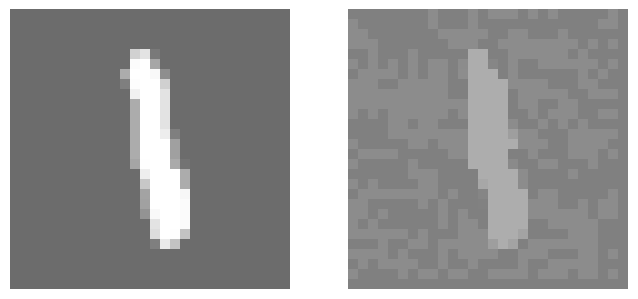


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


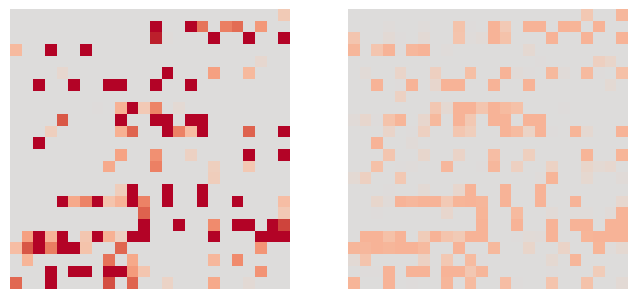

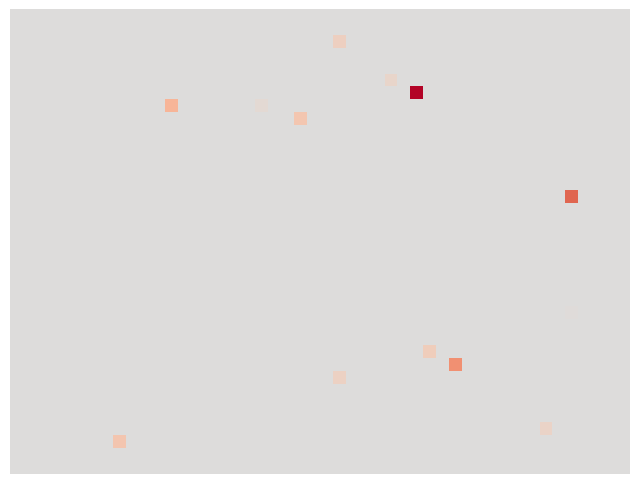


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


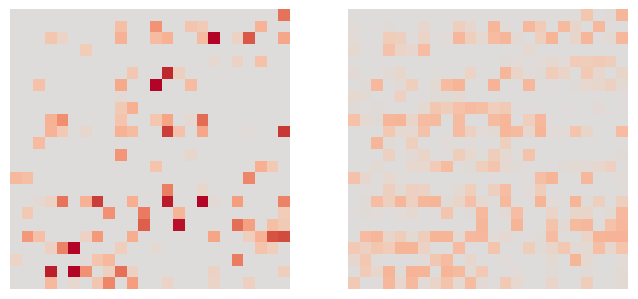

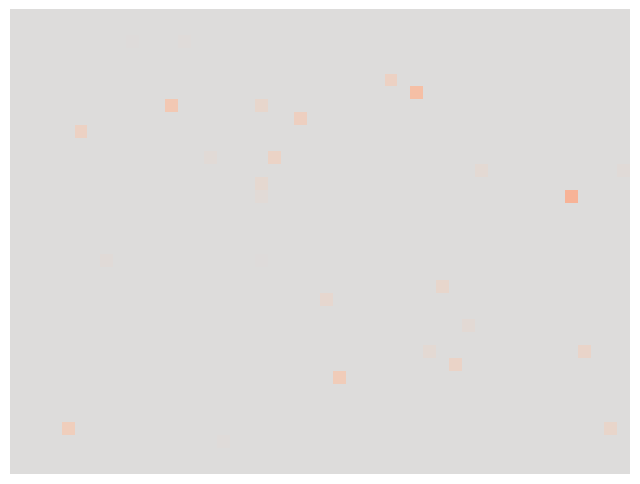

sae_encoding_adv - sae_encoding_init:


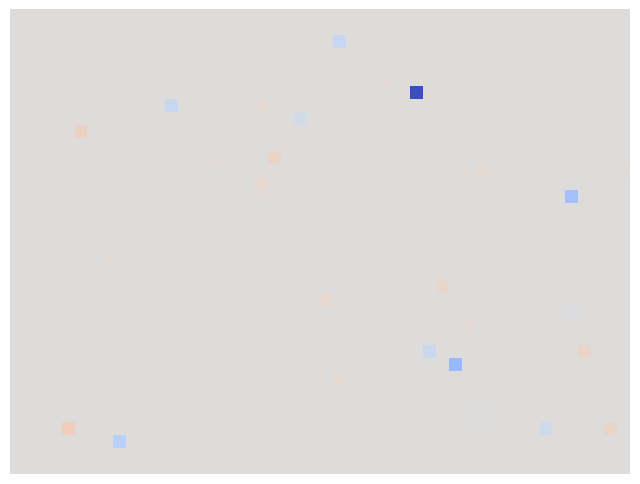

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


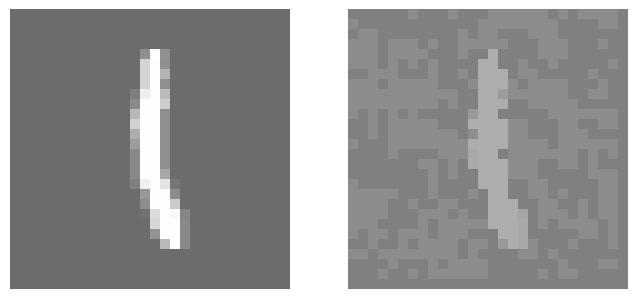


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


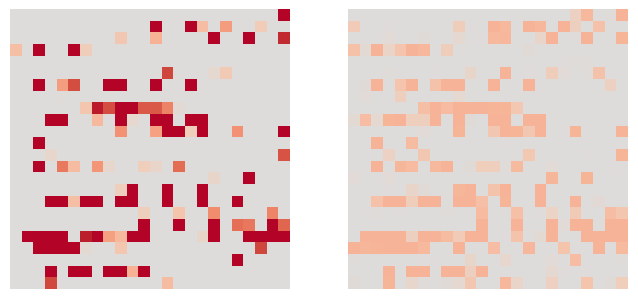

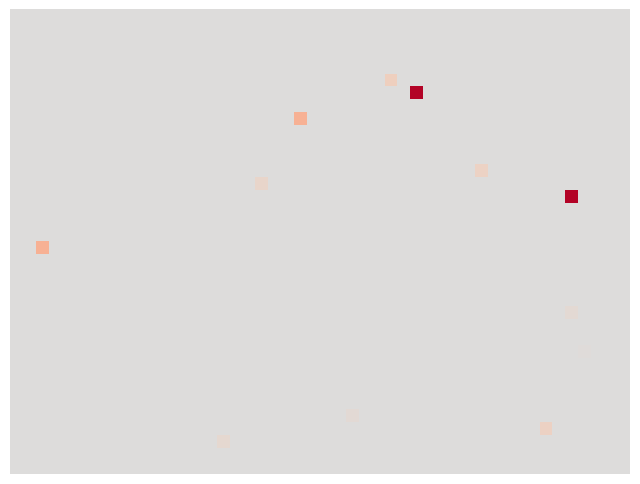


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


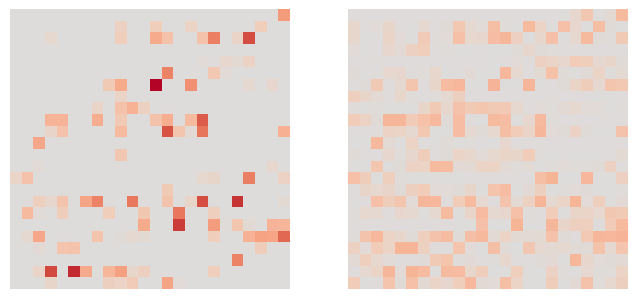

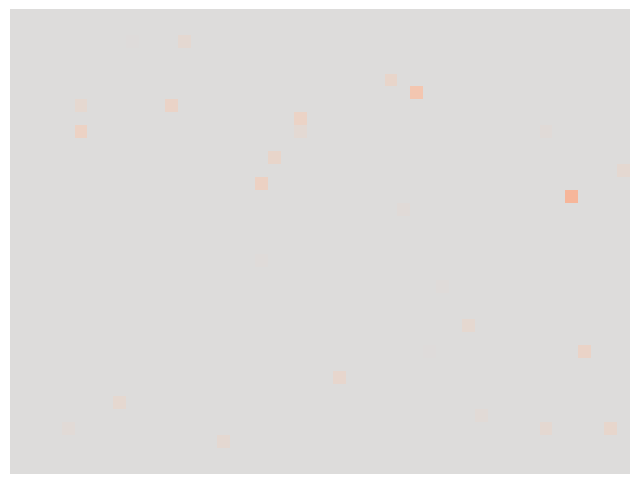

sae_encoding_adv - sae_encoding_init:


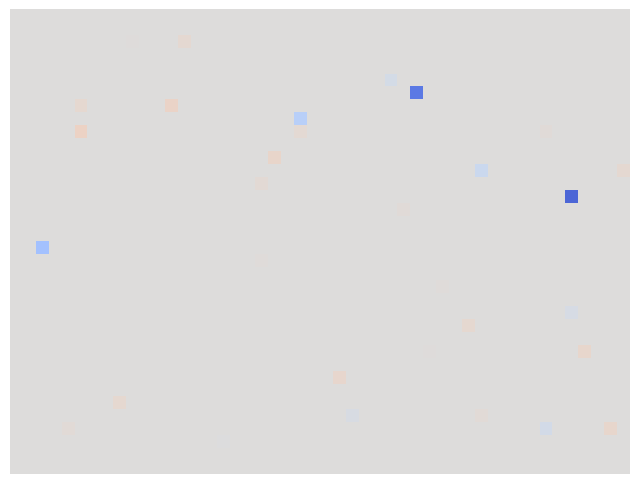

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


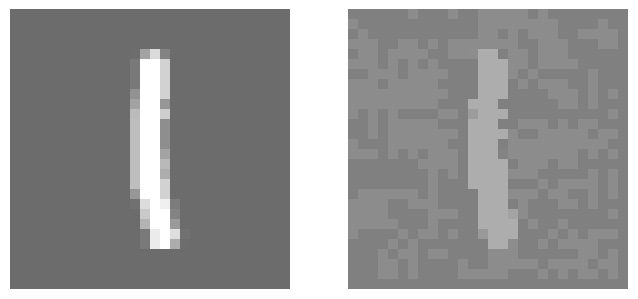


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


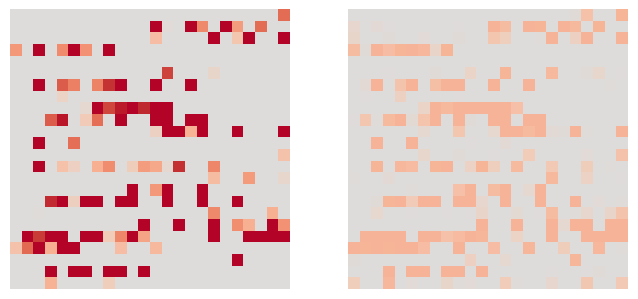

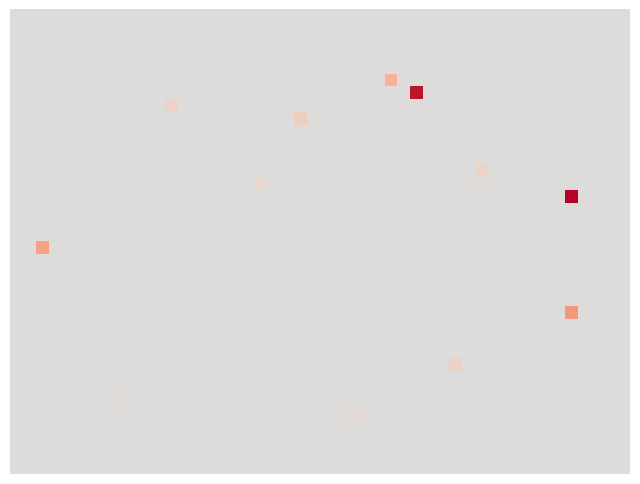


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


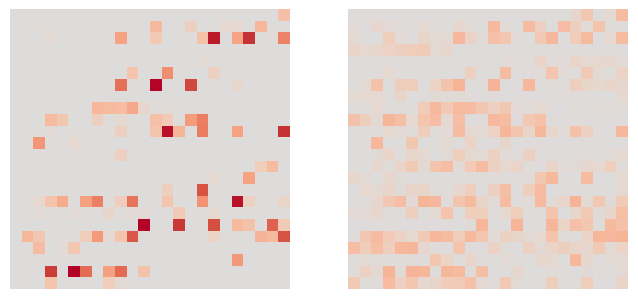

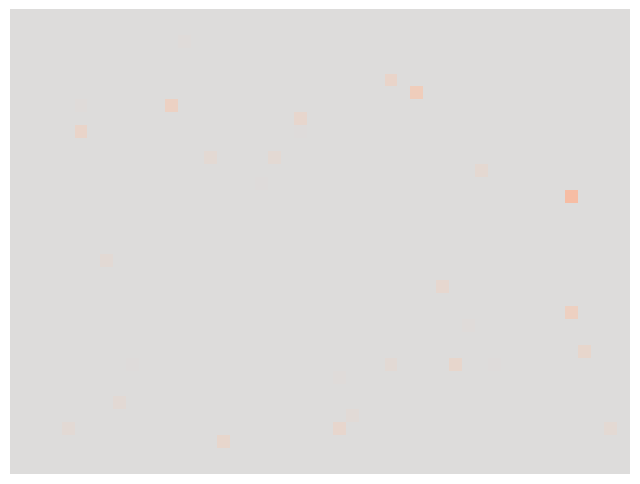

sae_encoding_adv - sae_encoding_init:


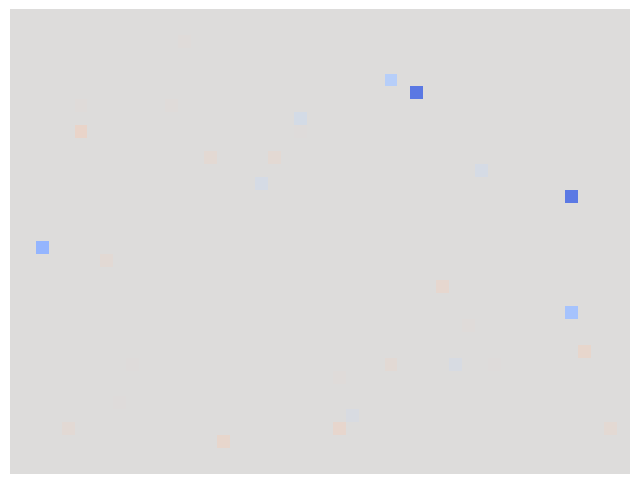

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


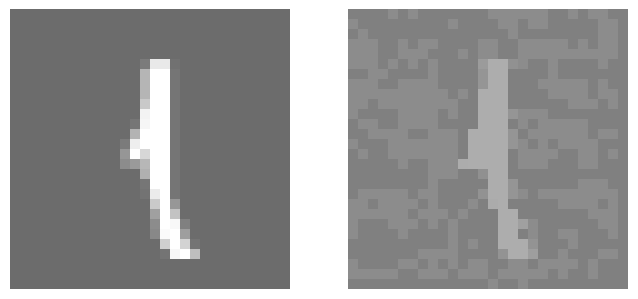


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


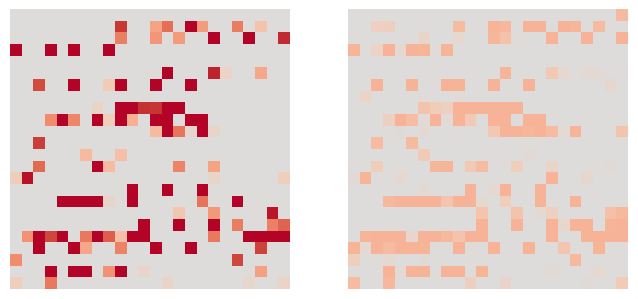

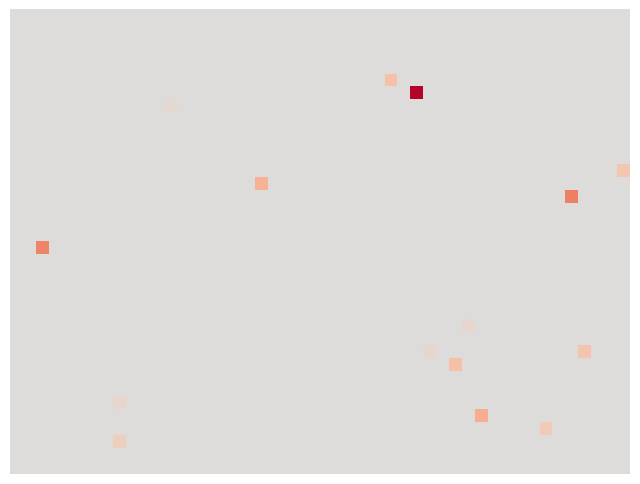


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


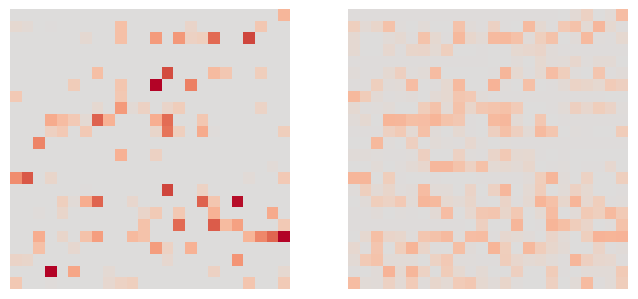

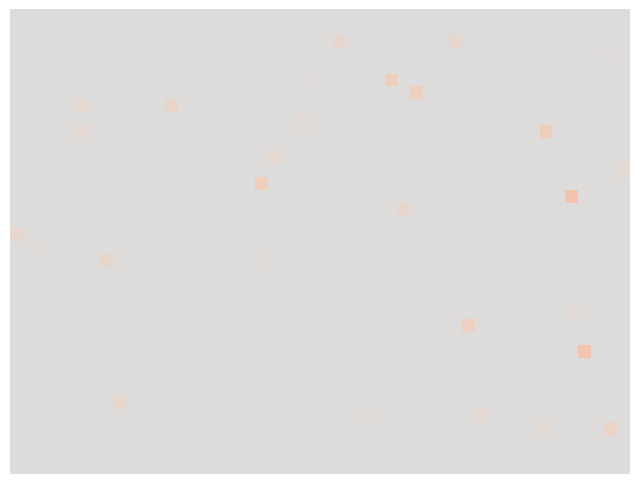

sae_encoding_adv - sae_encoding_init:


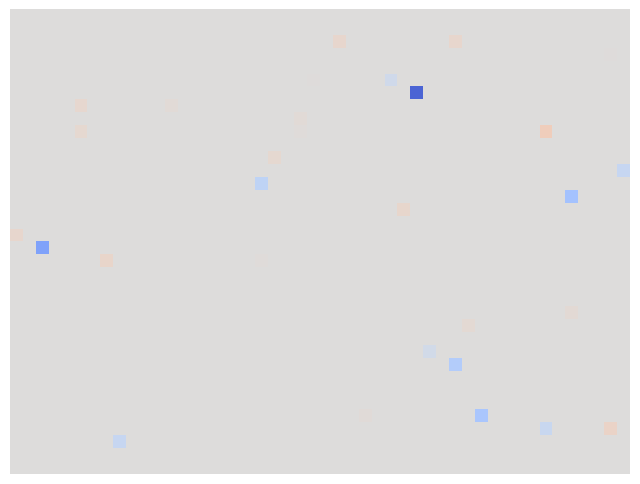

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


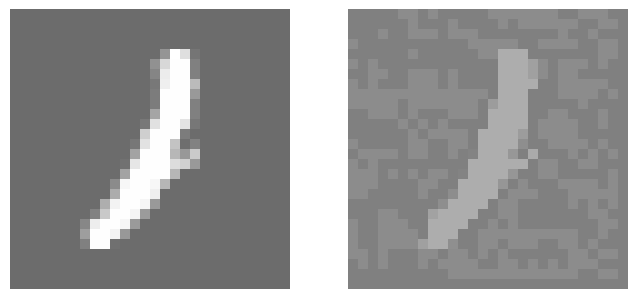


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


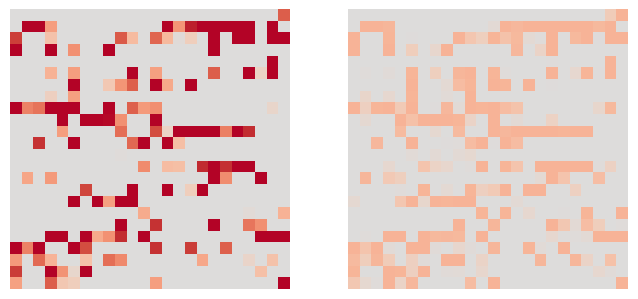

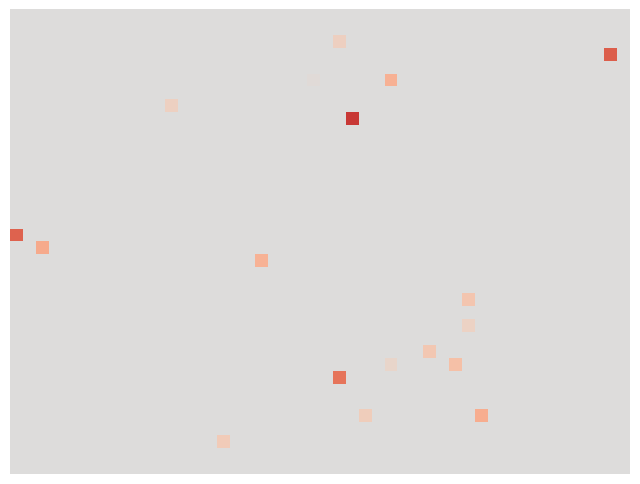


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


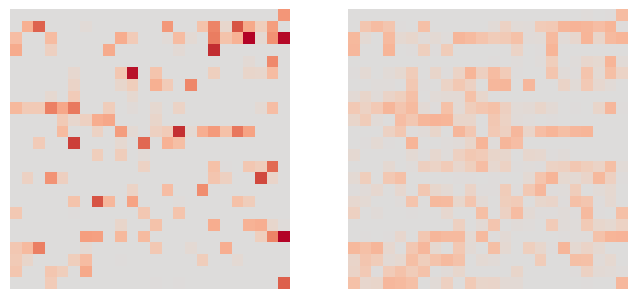

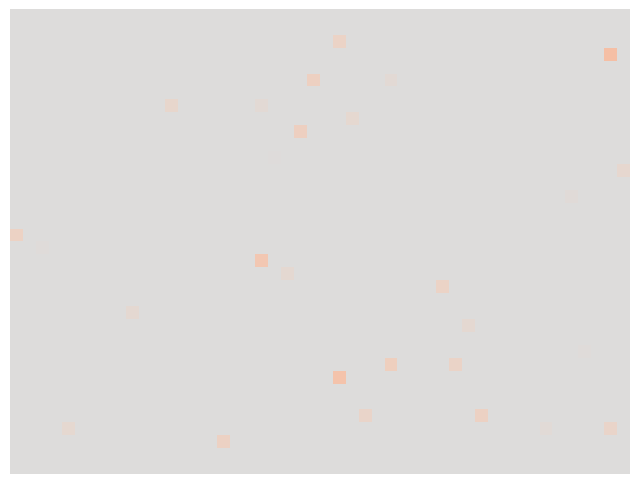

sae_encoding_adv - sae_encoding_init:


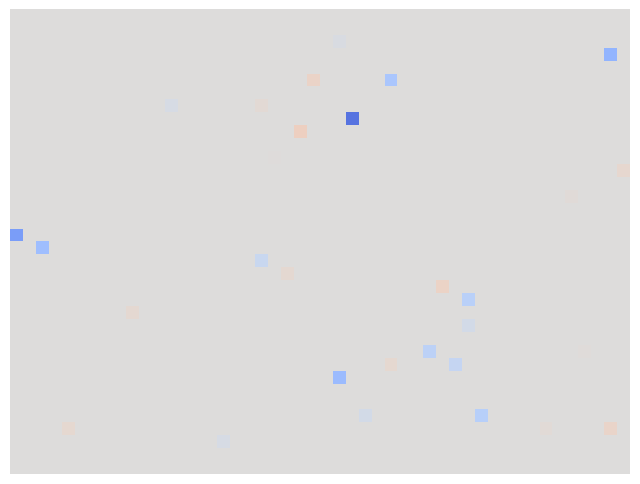

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


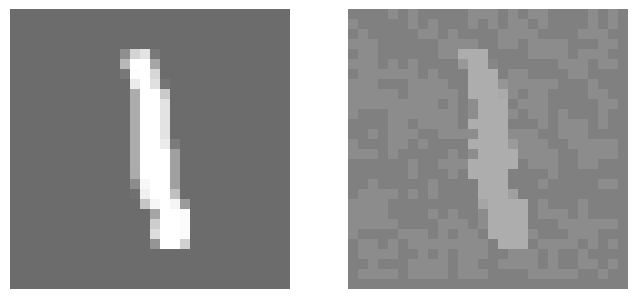


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


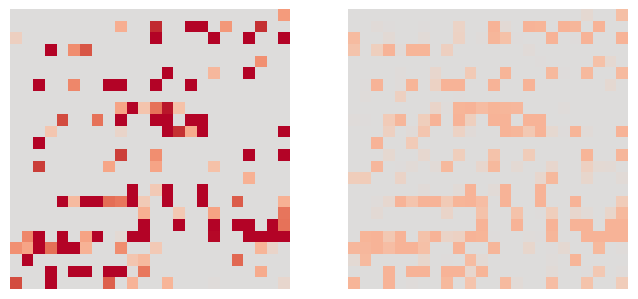

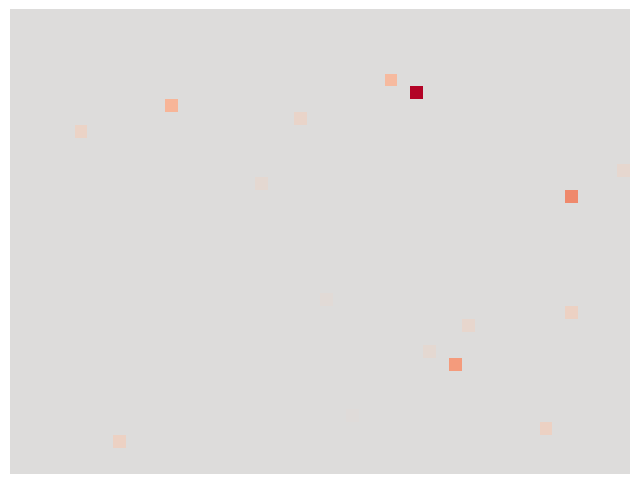


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


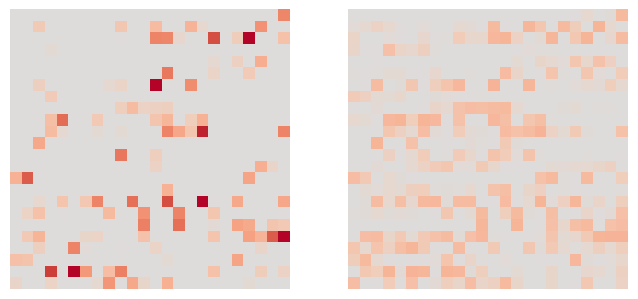

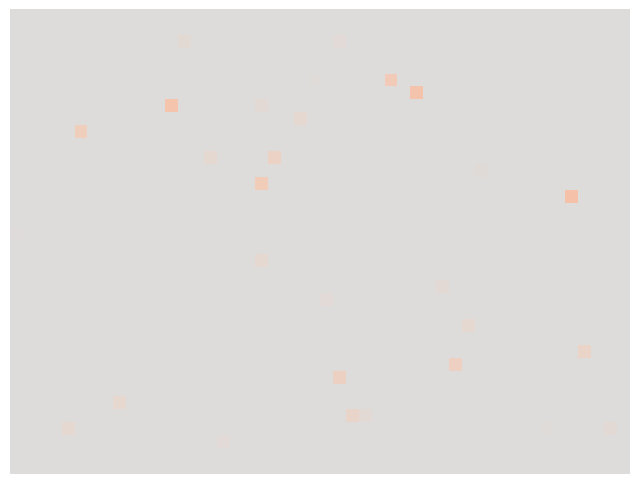

sae_encoding_adv - sae_encoding_init:


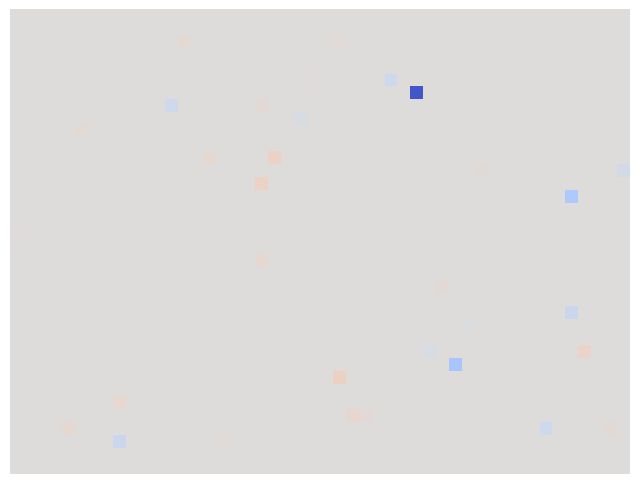

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


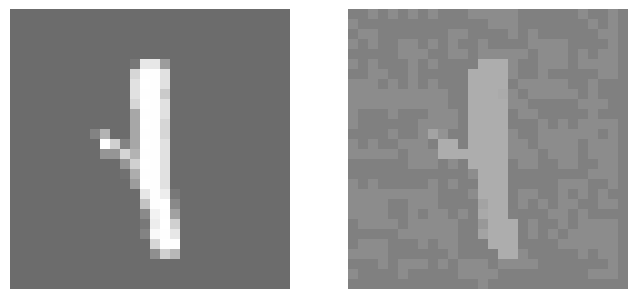


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


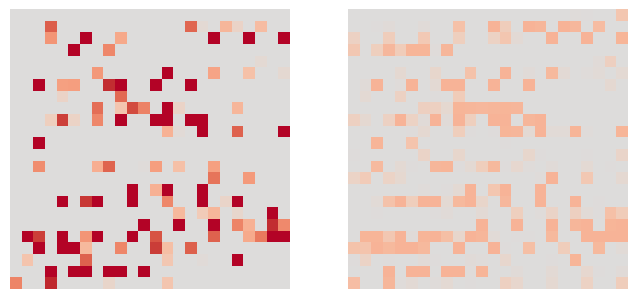

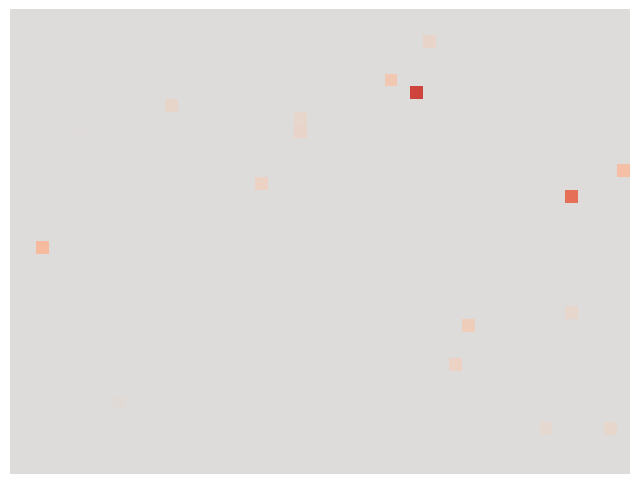


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


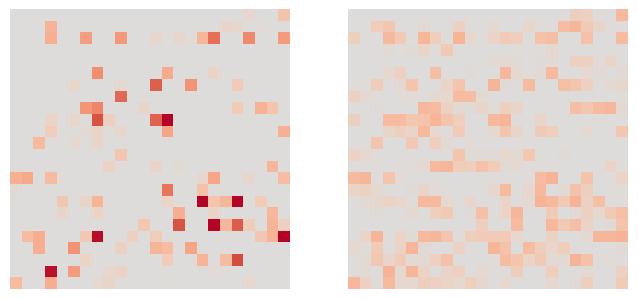

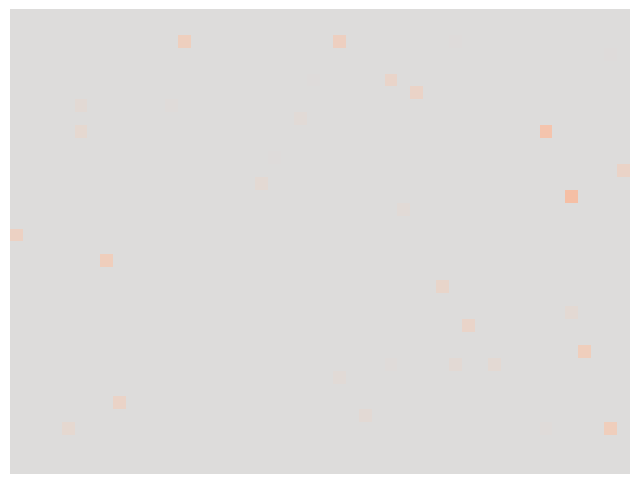

sae_encoding_adv - sae_encoding_init:


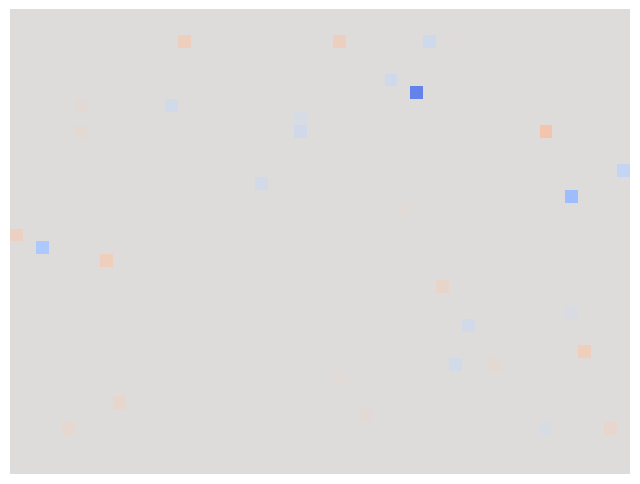

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


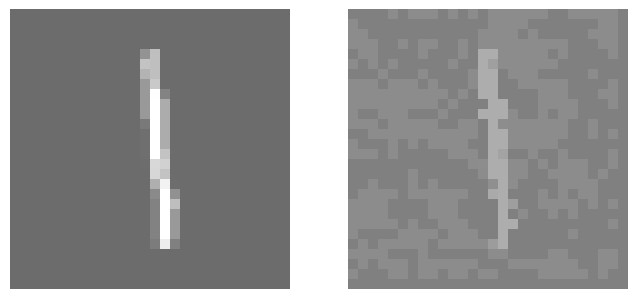


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


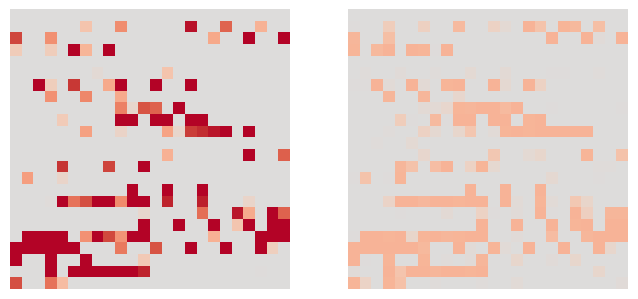

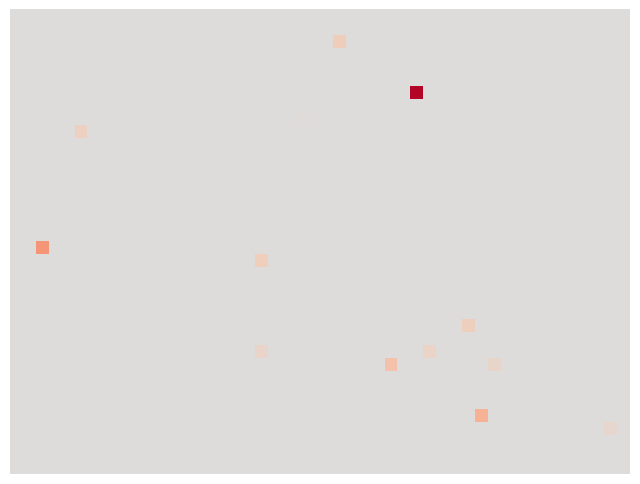


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


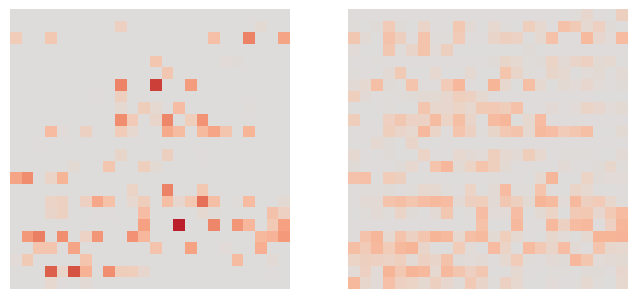

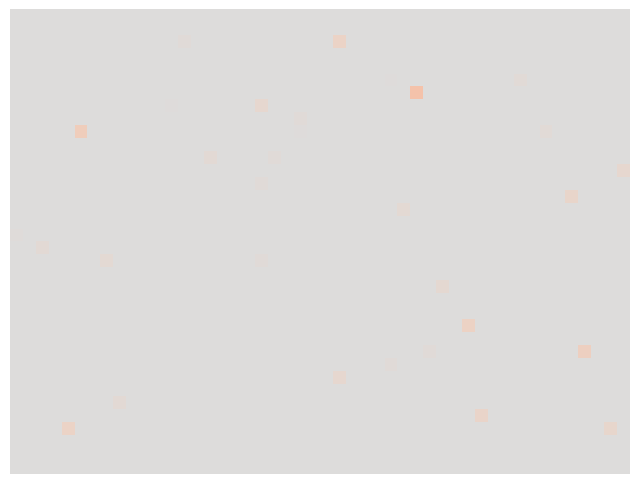

sae_encoding_adv - sae_encoding_init:


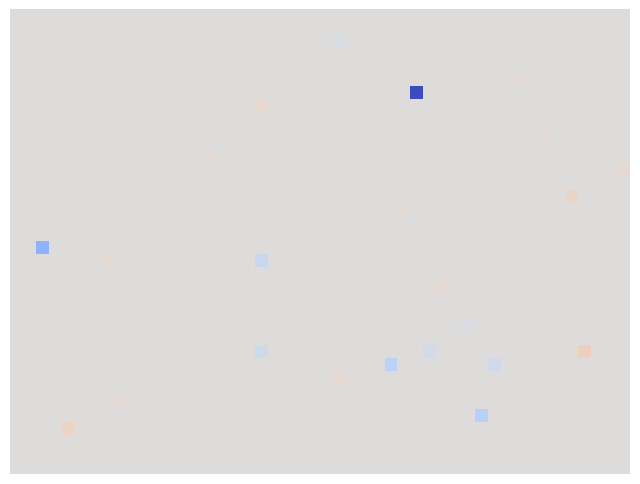

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


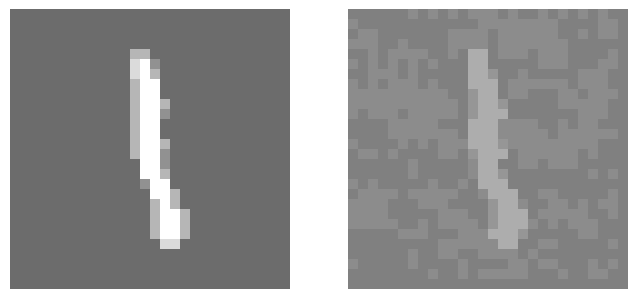


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


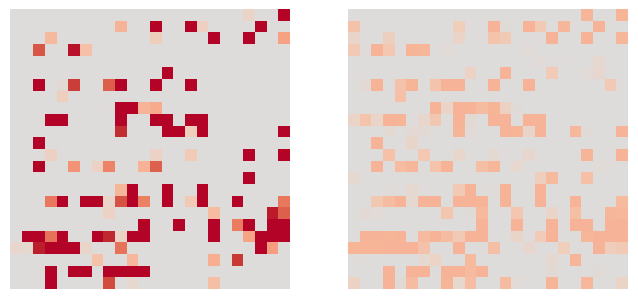

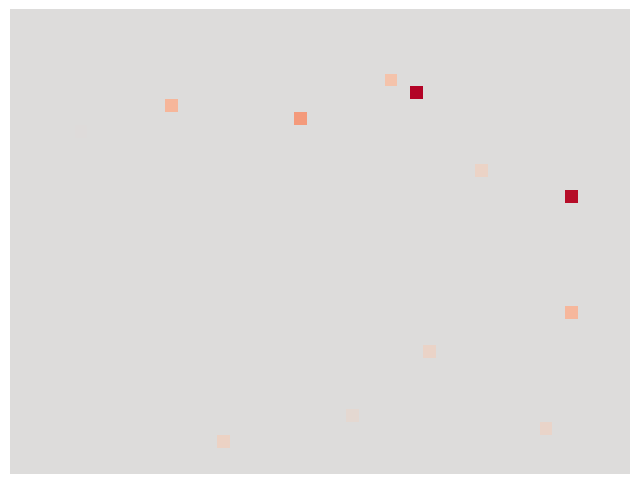


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


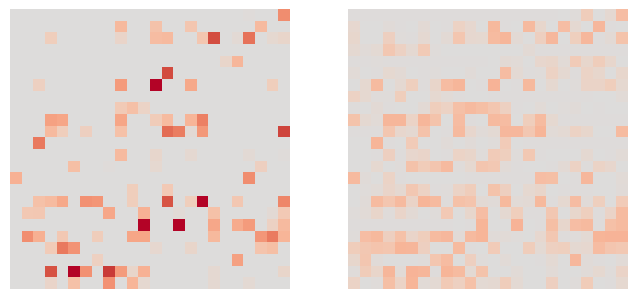

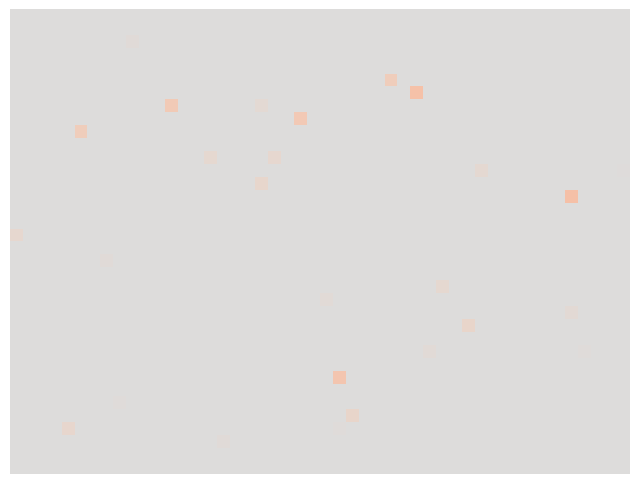

sae_encoding_adv - sae_encoding_init:


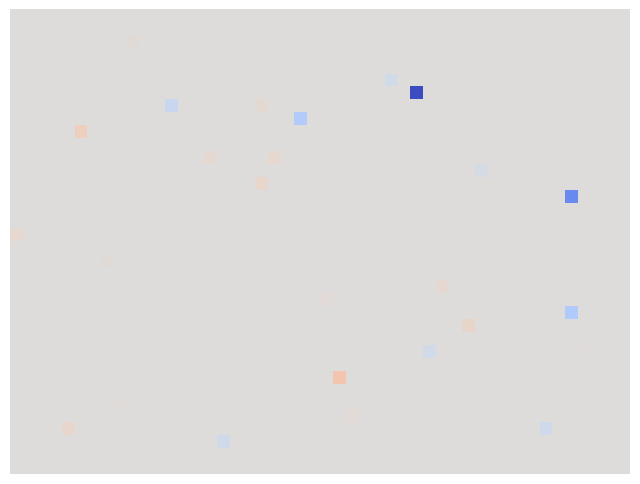

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


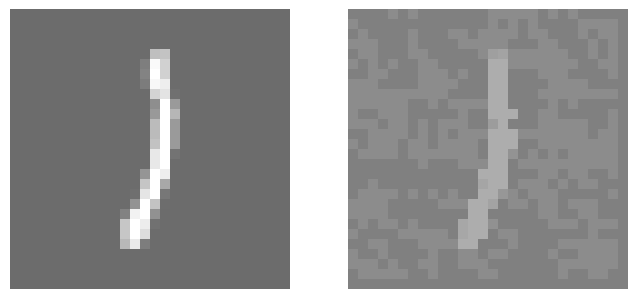


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


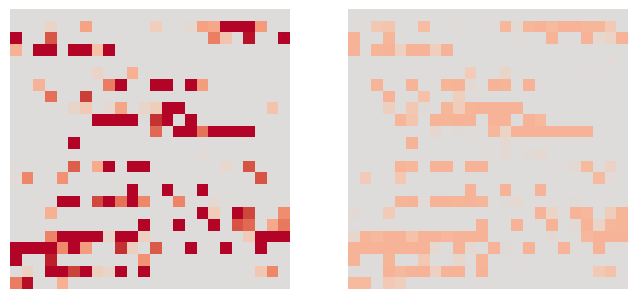

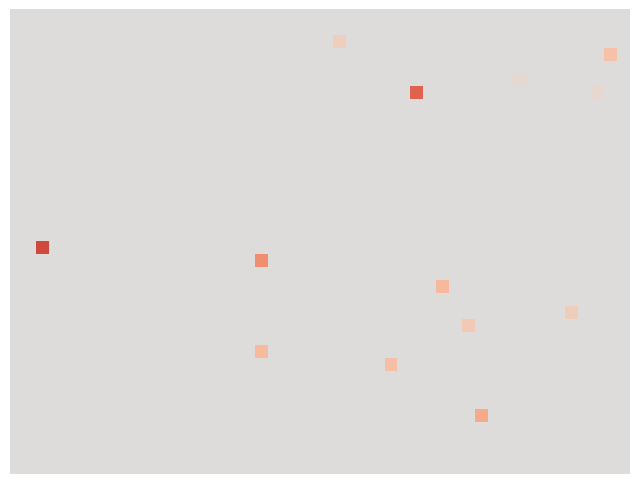


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


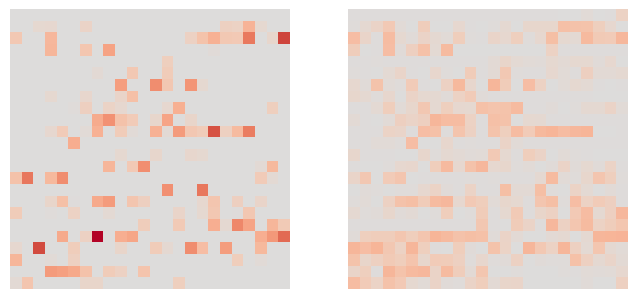

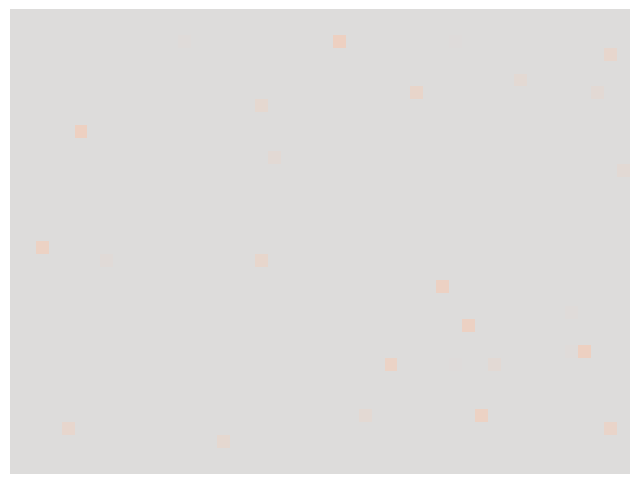

sae_encoding_adv - sae_encoding_init:


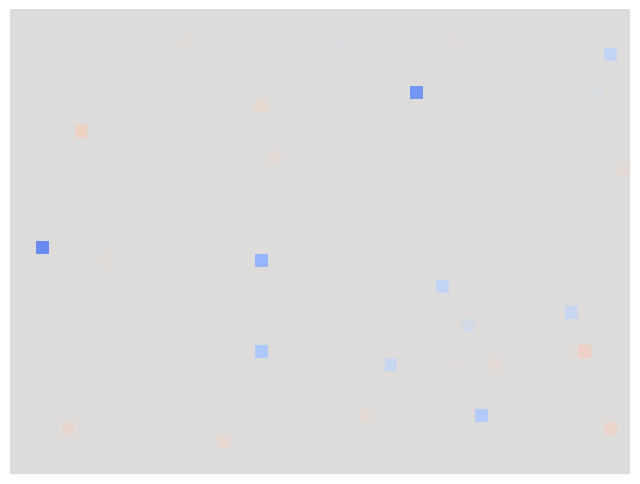

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


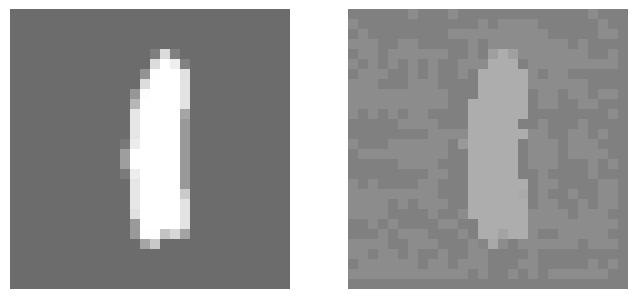


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


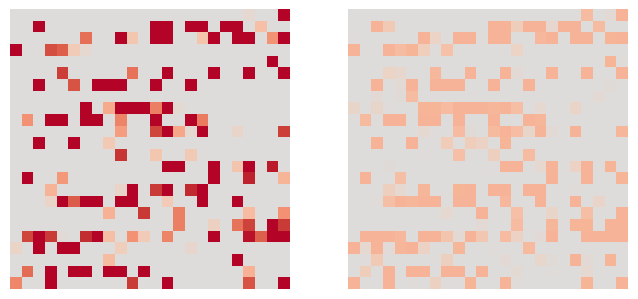

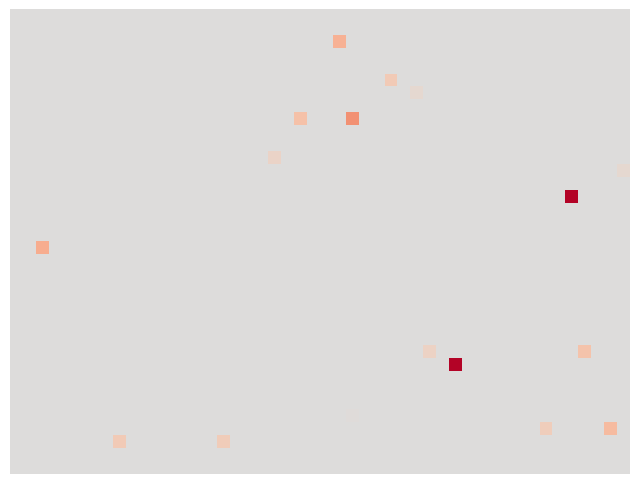


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


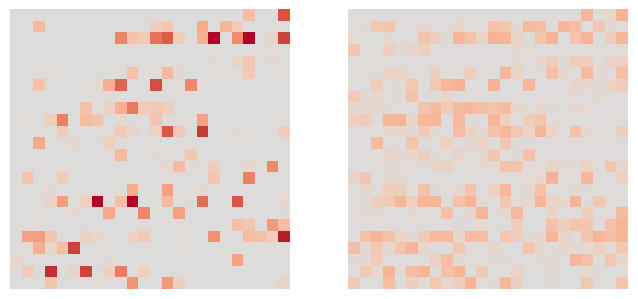

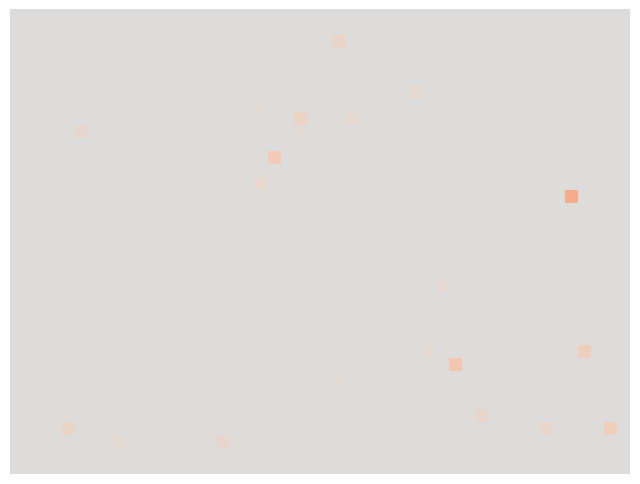

sae_encoding_adv - sae_encoding_init:


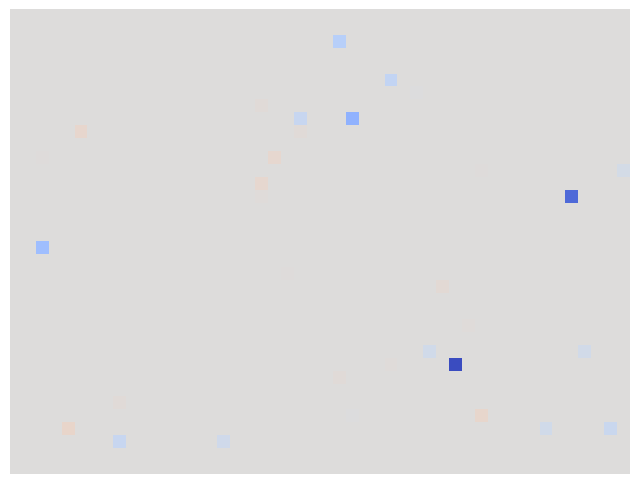

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


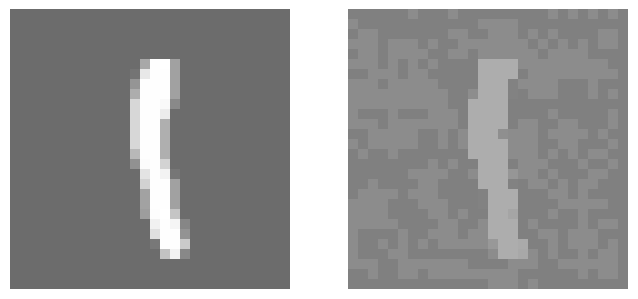


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


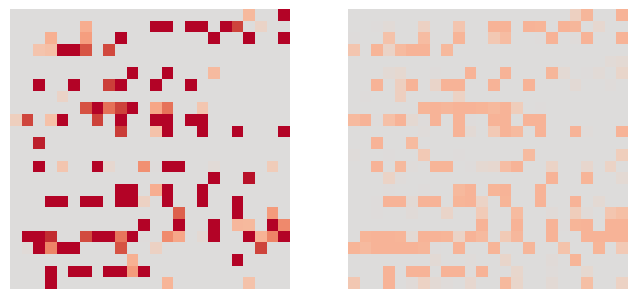

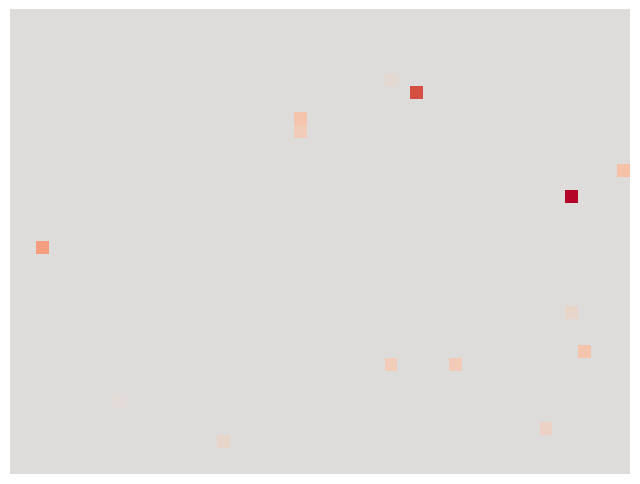


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


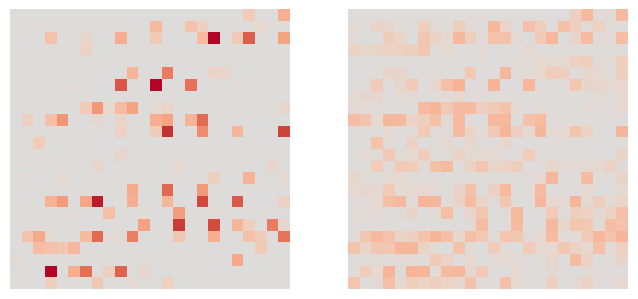

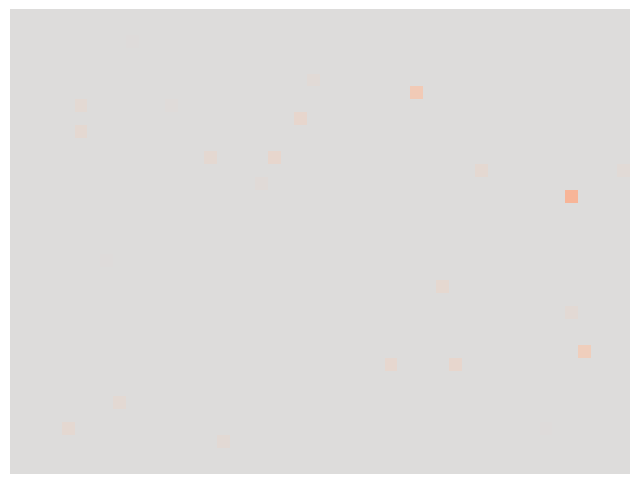

sae_encoding_adv - sae_encoding_init:


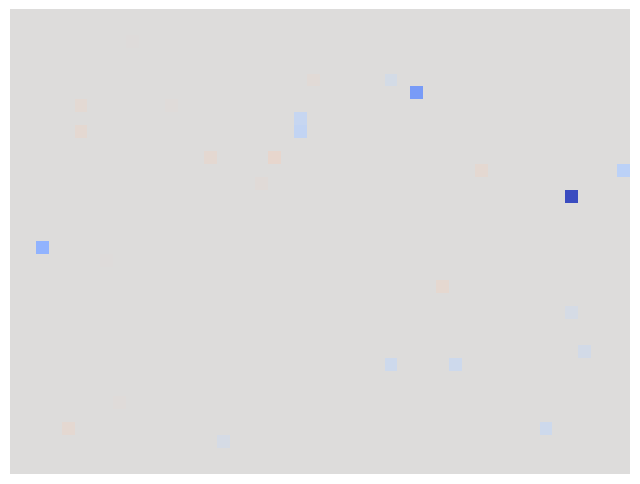

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


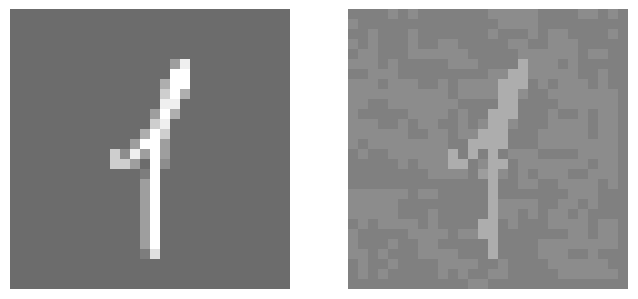


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


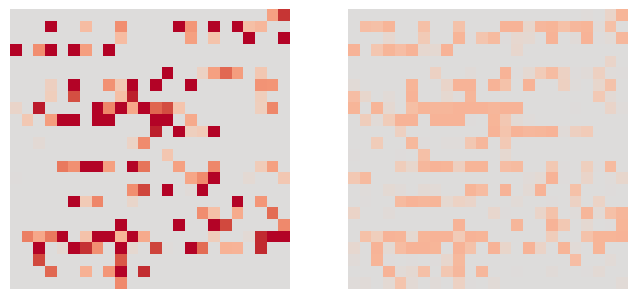

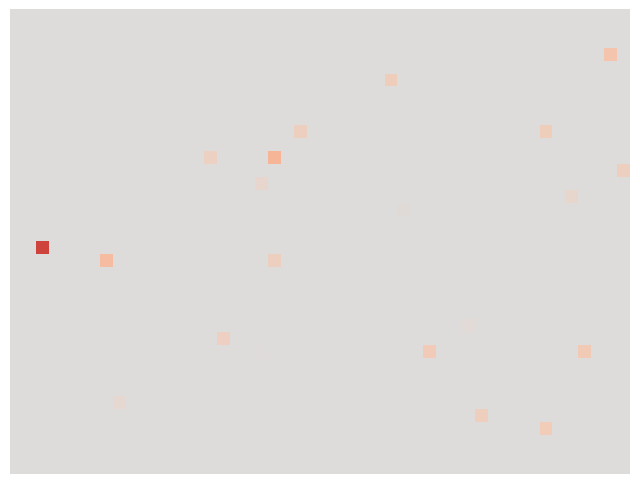


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


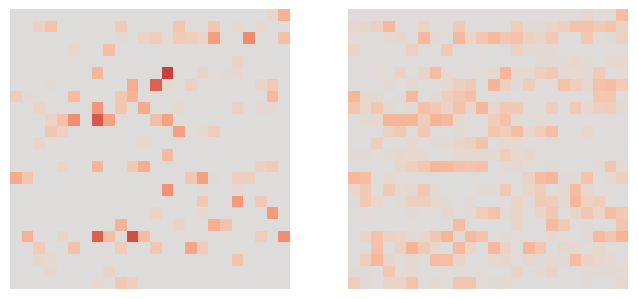

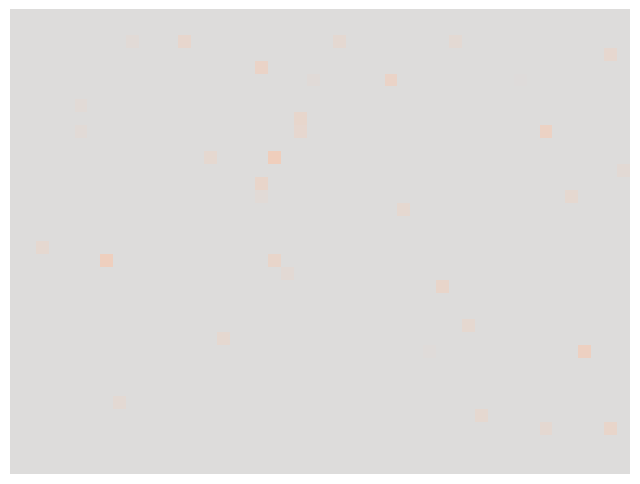

sae_encoding_adv - sae_encoding_init:


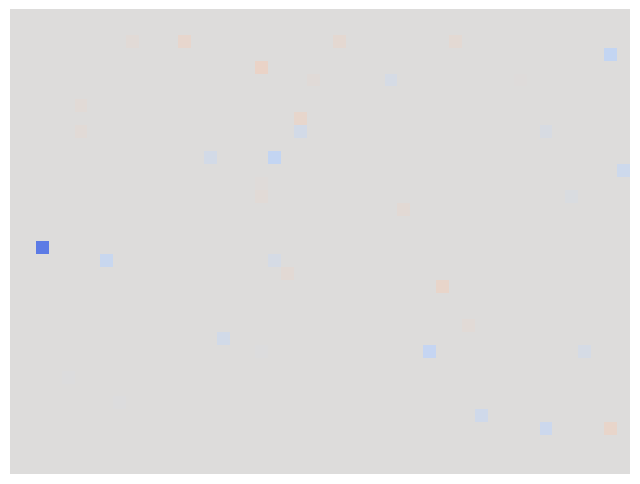

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


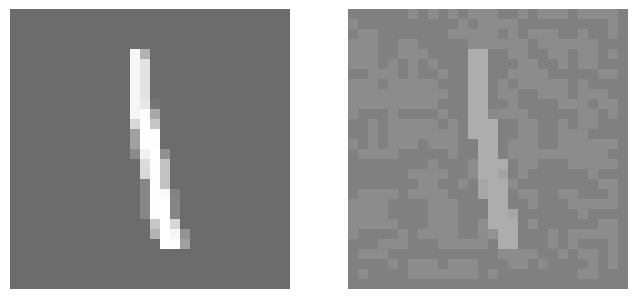


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


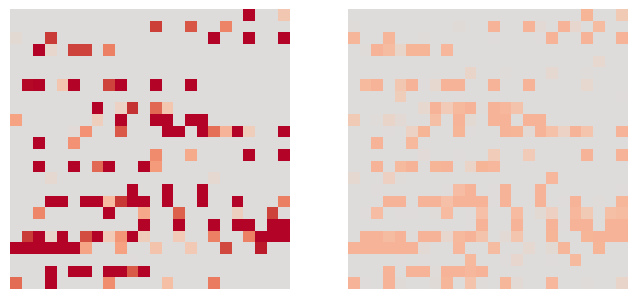

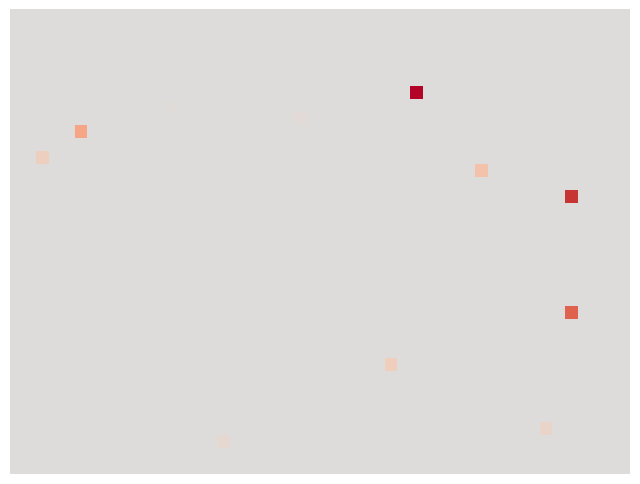


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


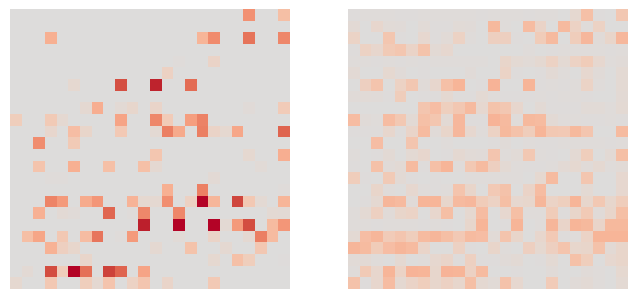

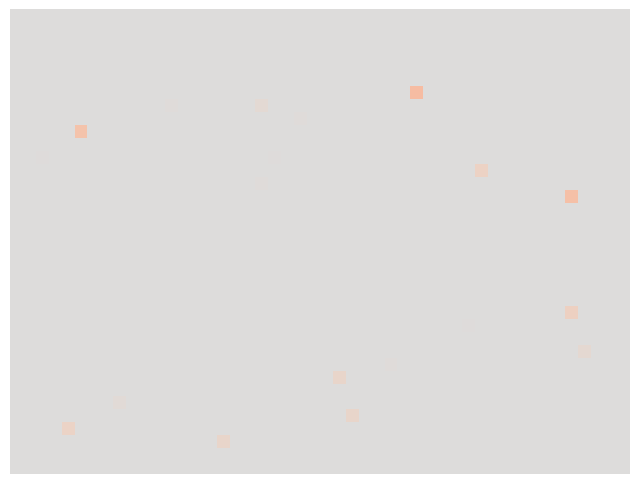

sae_encoding_adv - sae_encoding_init:


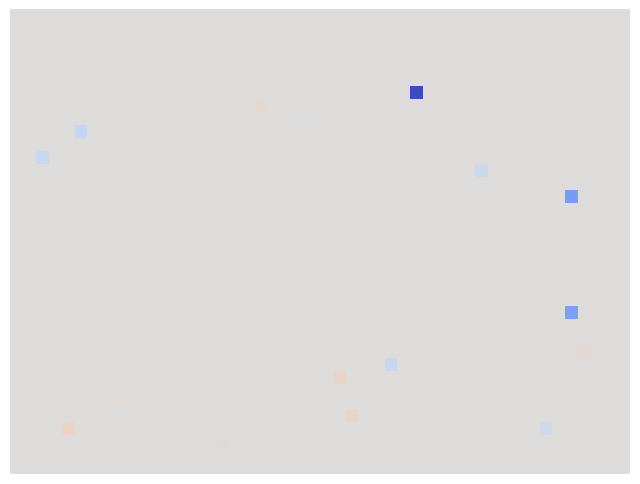

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


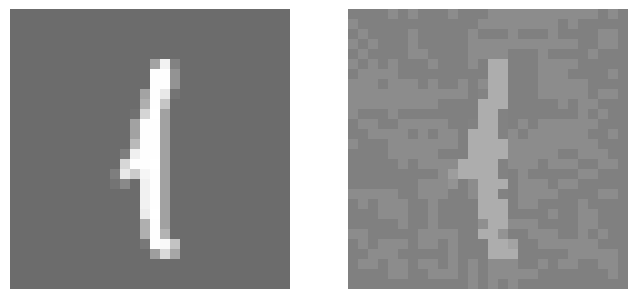


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


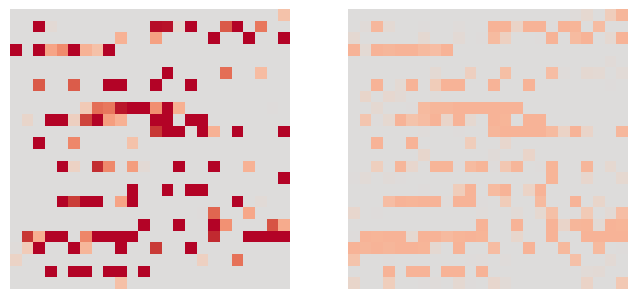

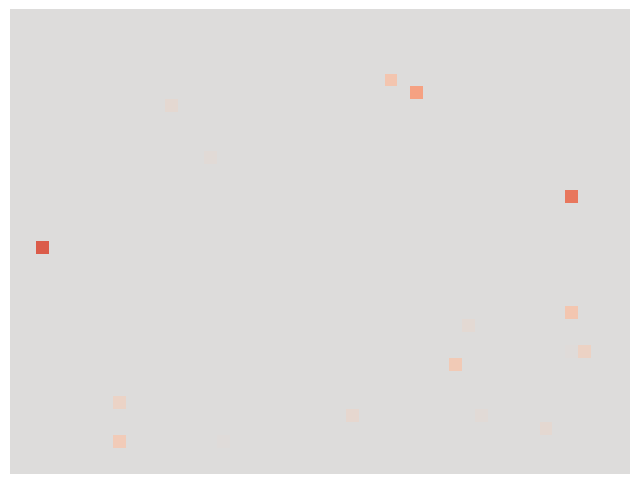


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


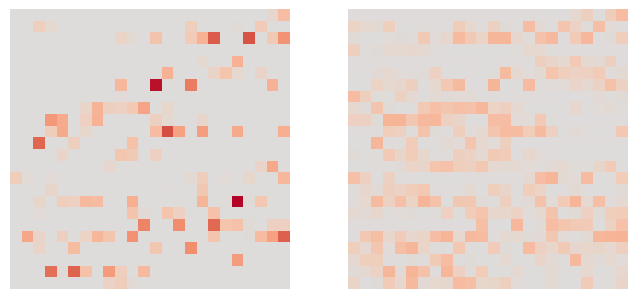

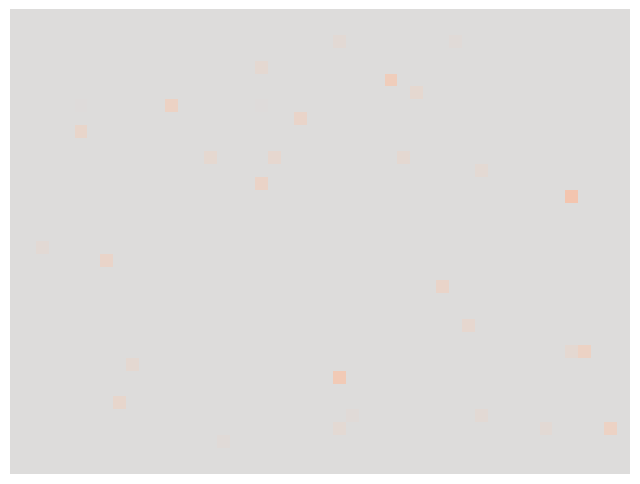

sae_encoding_adv - sae_encoding_init:


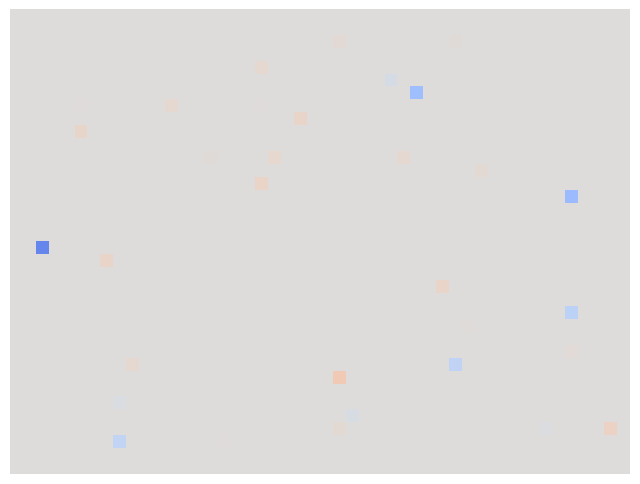

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


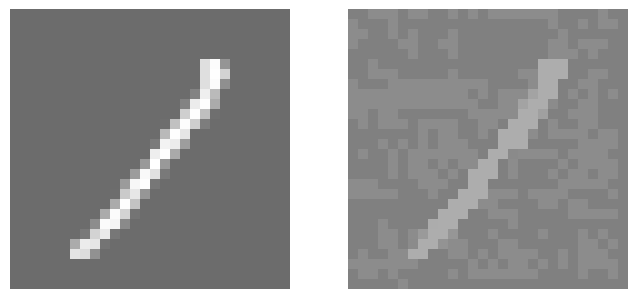


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


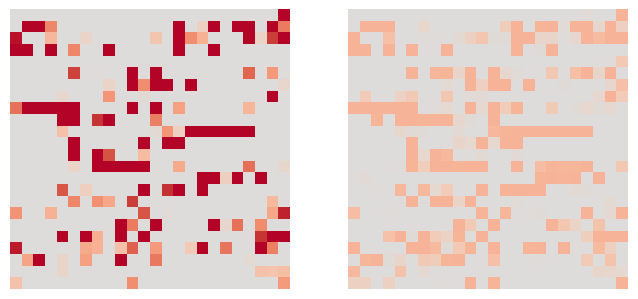

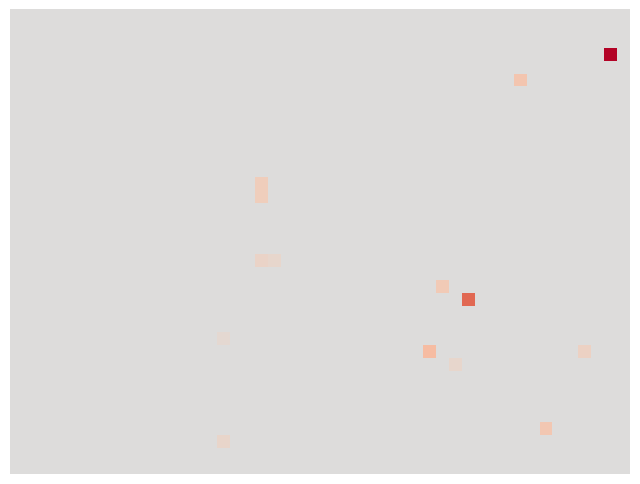


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


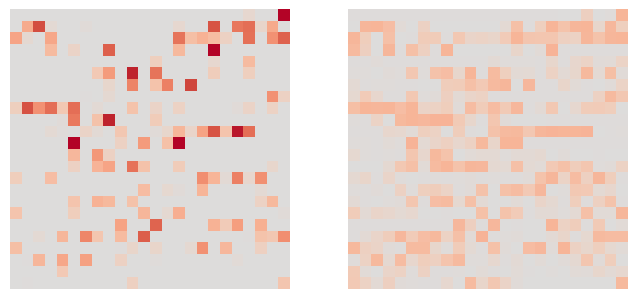

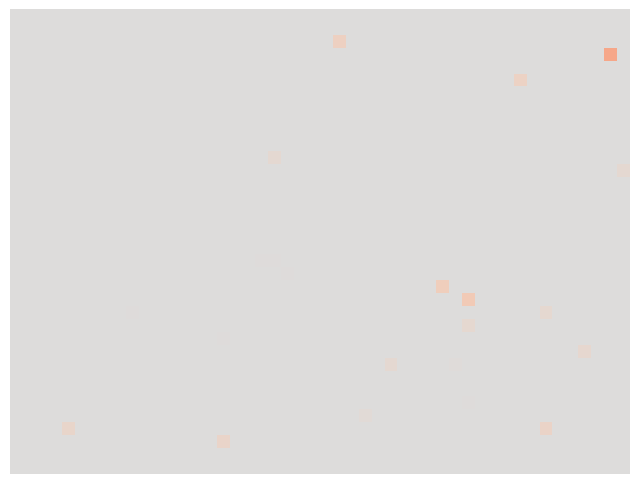

sae_encoding_adv - sae_encoding_init:


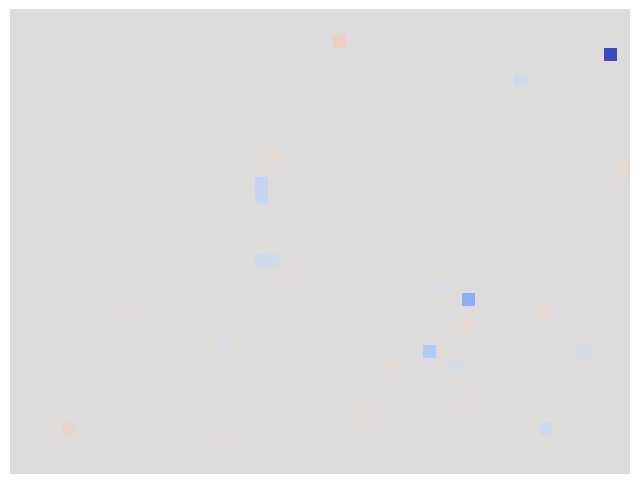

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


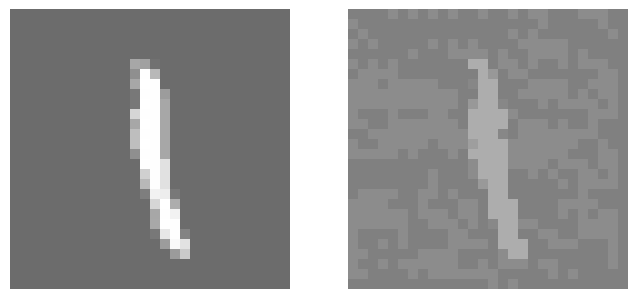


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


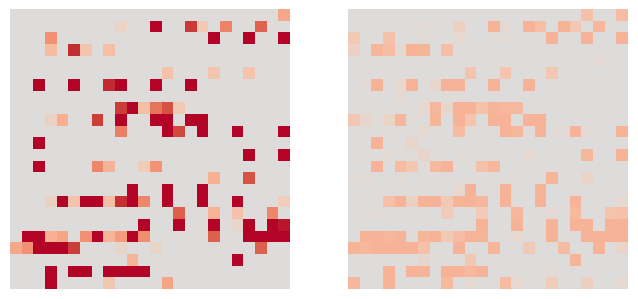

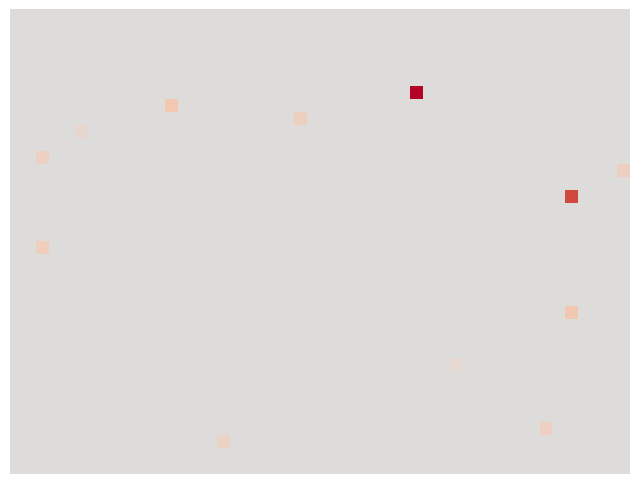


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


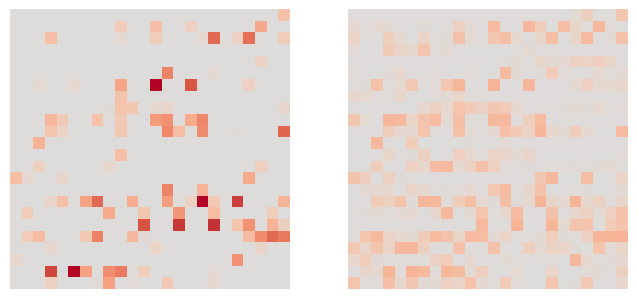

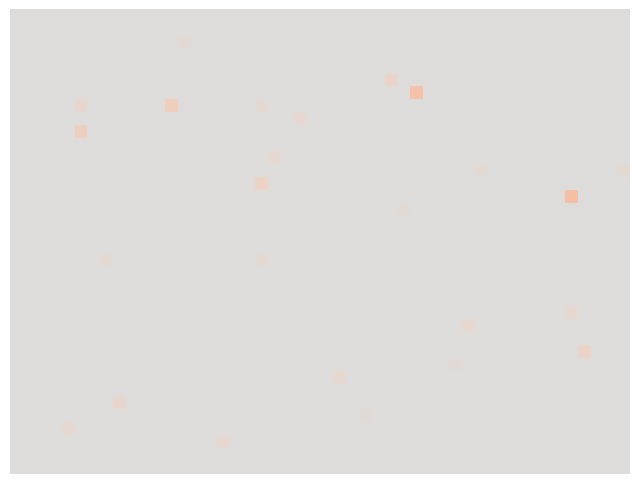

sae_encoding_adv - sae_encoding_init:


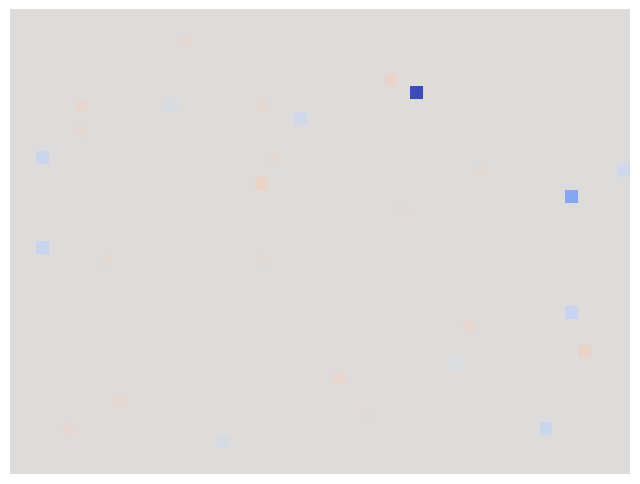

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


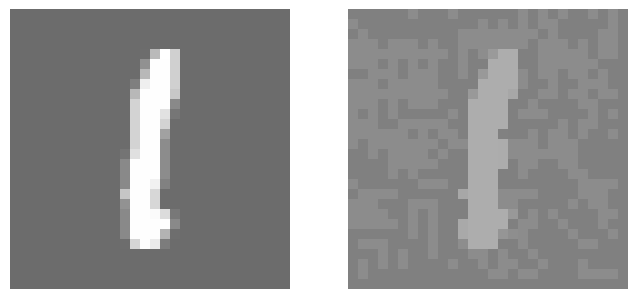


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


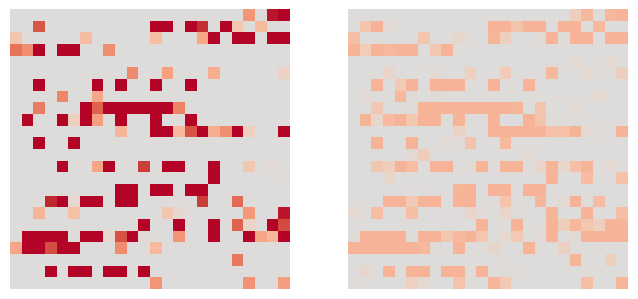

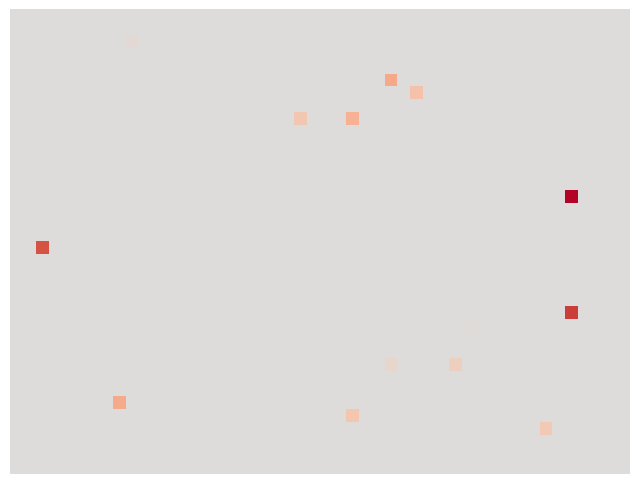


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


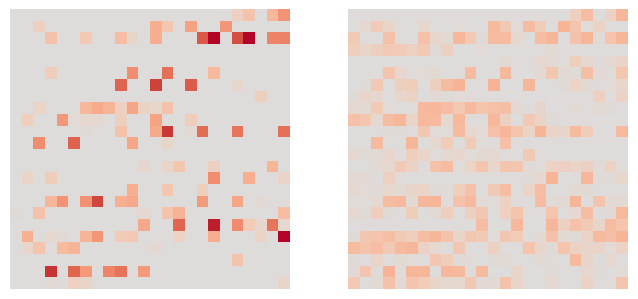

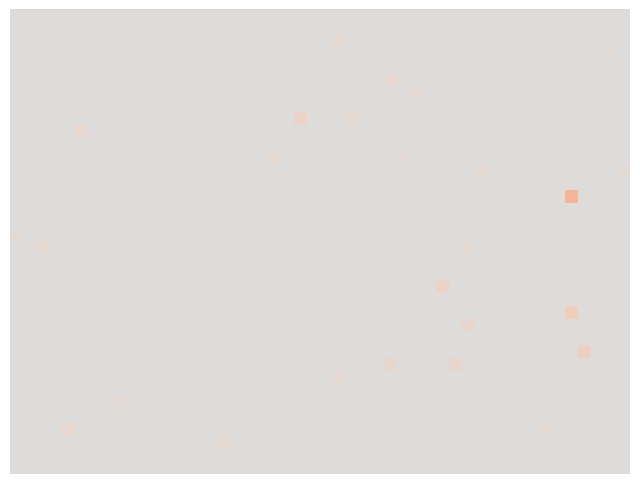

sae_encoding_adv - sae_encoding_init:


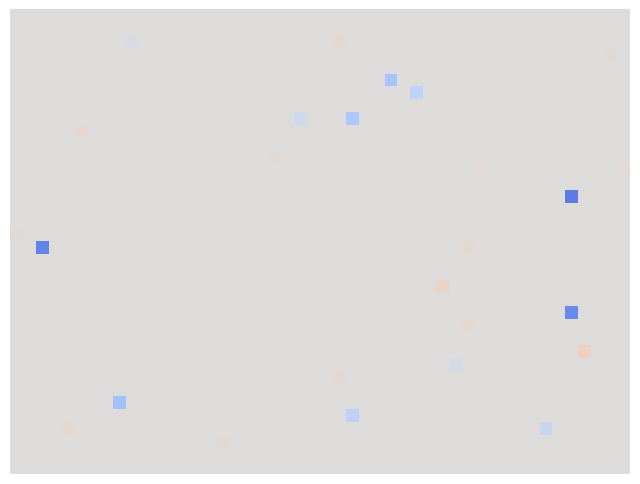

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


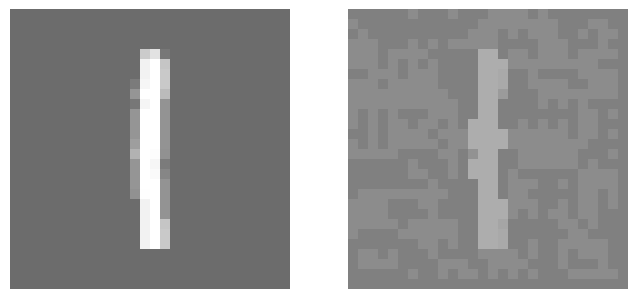


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


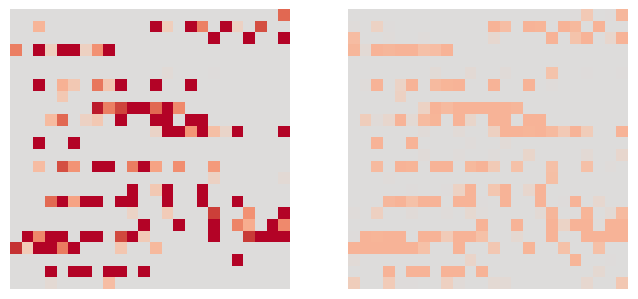

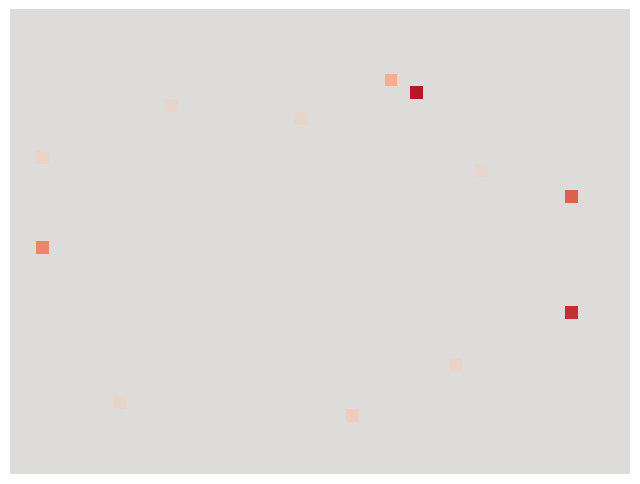


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


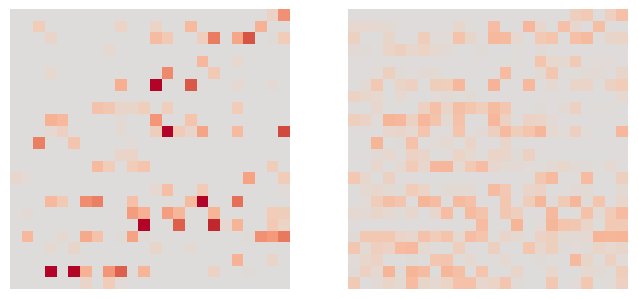

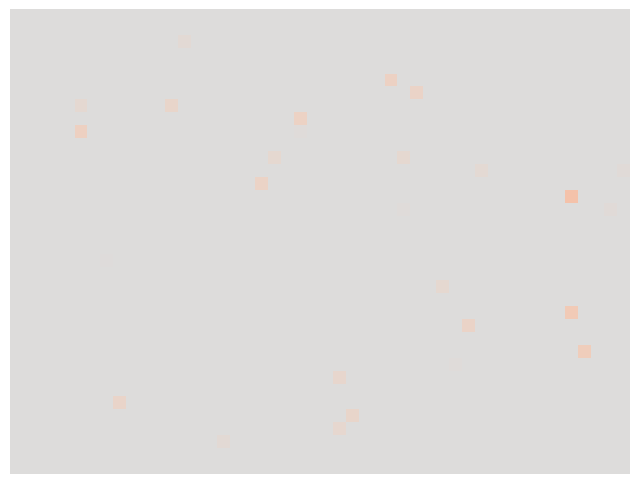

sae_encoding_adv - sae_encoding_init:


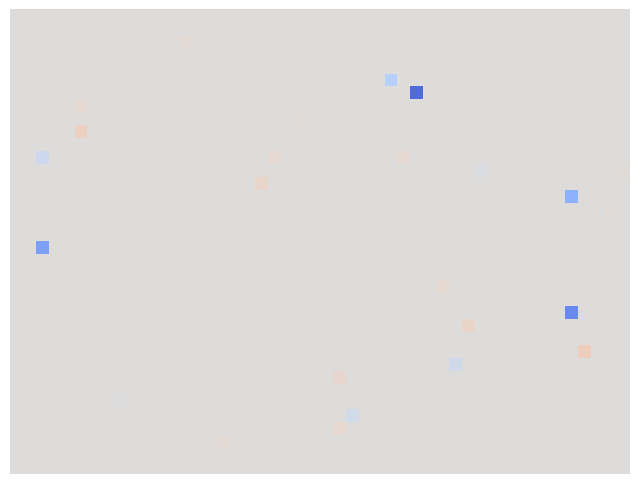

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


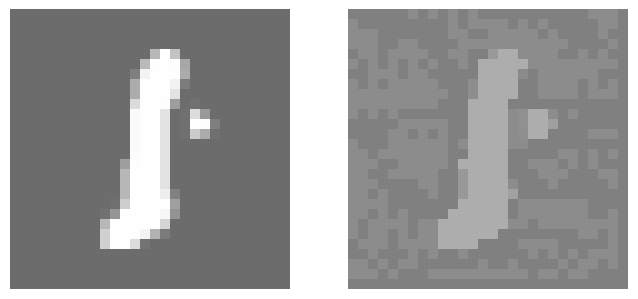


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


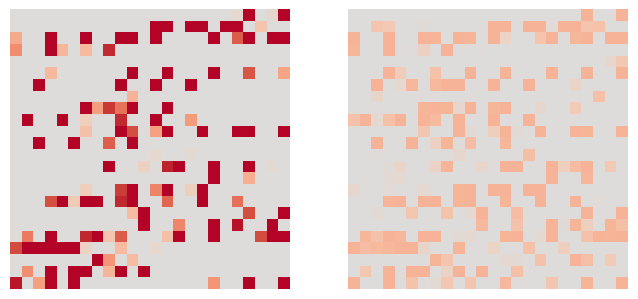

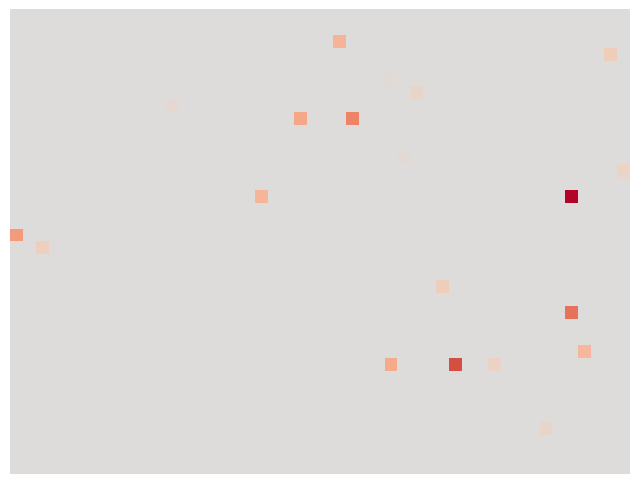


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


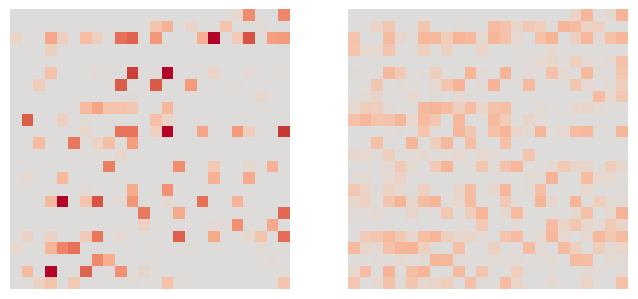

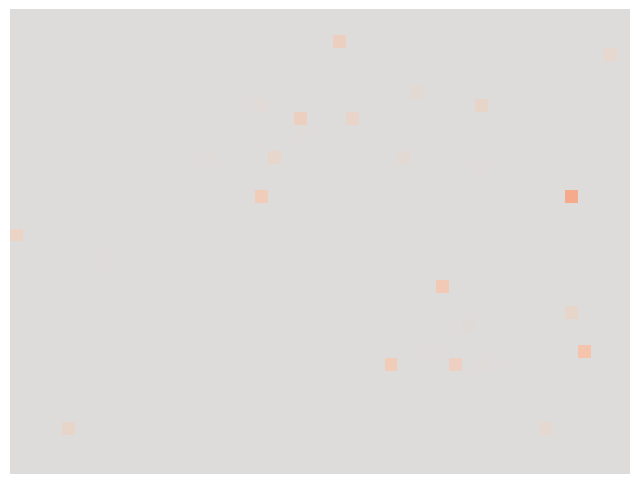

sae_encoding_adv - sae_encoding_init:


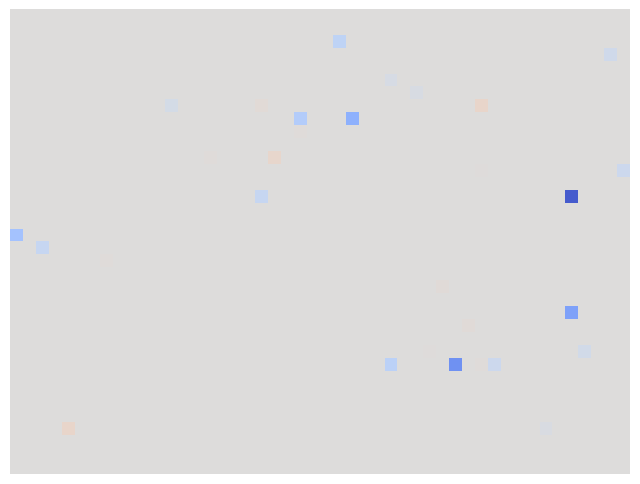

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


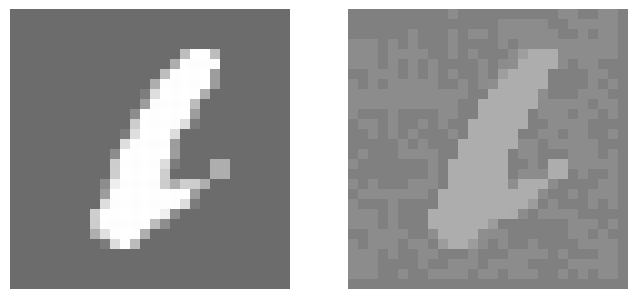


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


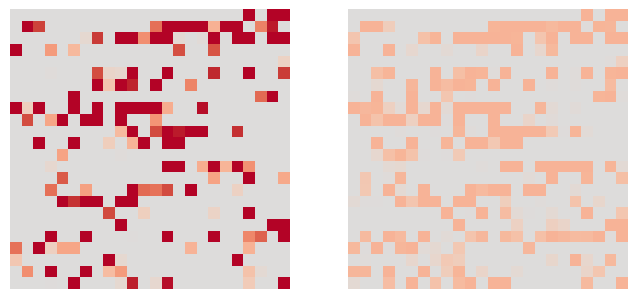

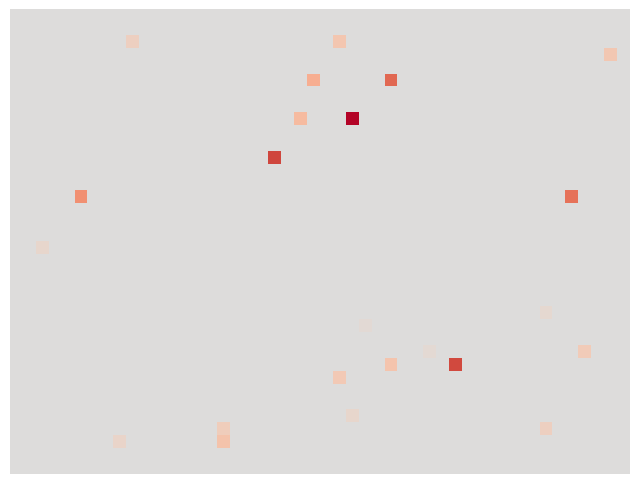


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


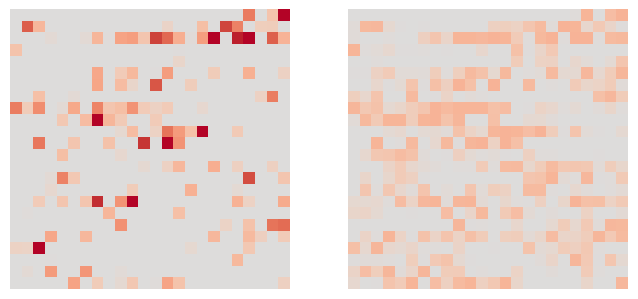

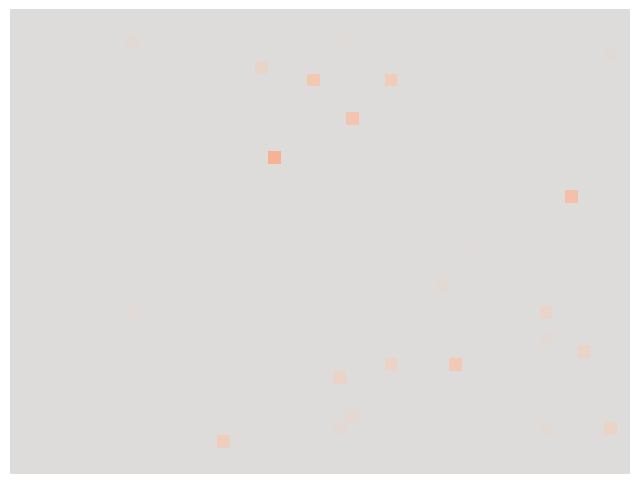

sae_encoding_adv - sae_encoding_init:


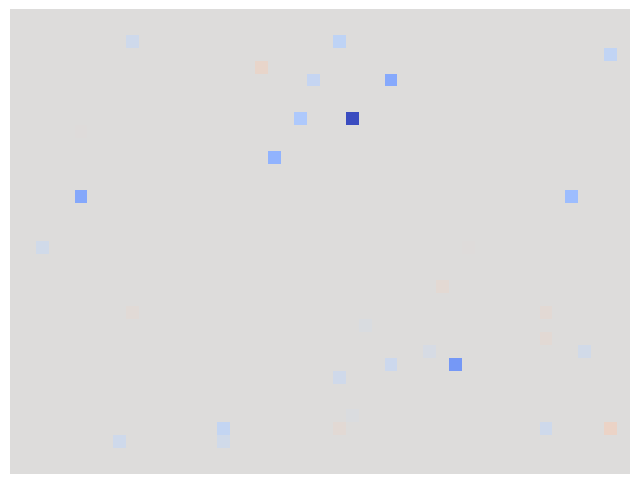

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


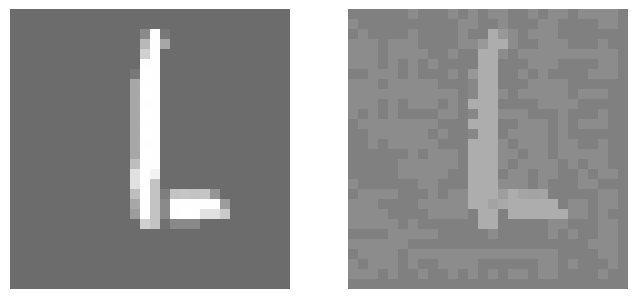


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


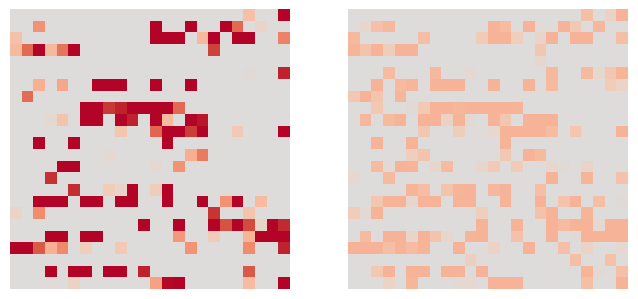

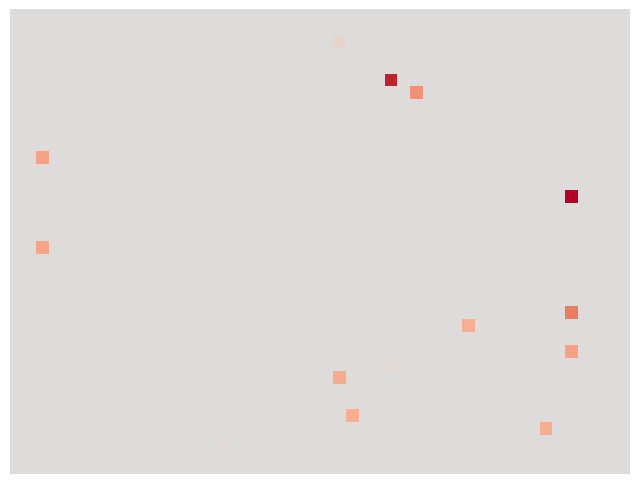


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


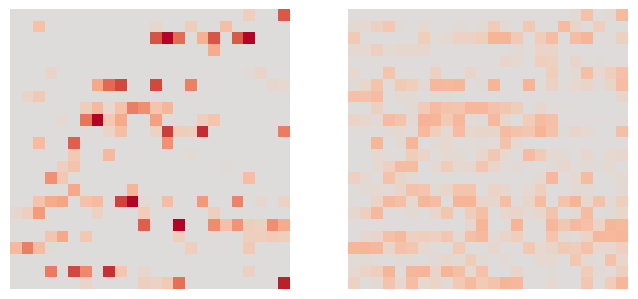

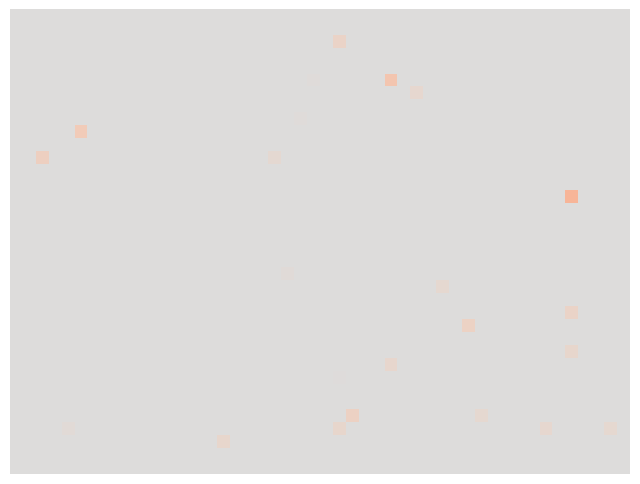

sae_encoding_adv - sae_encoding_init:


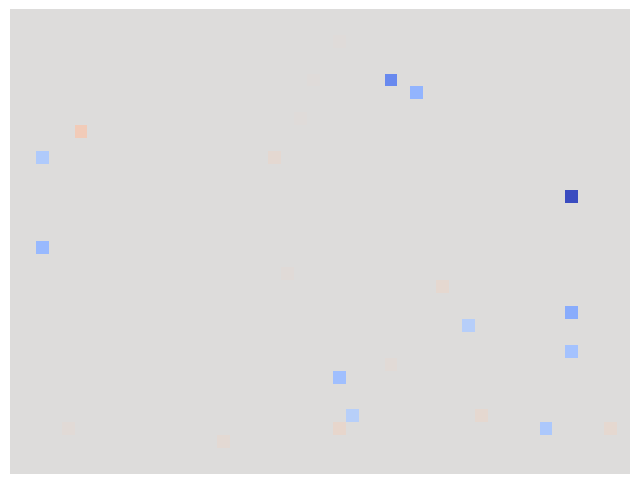

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


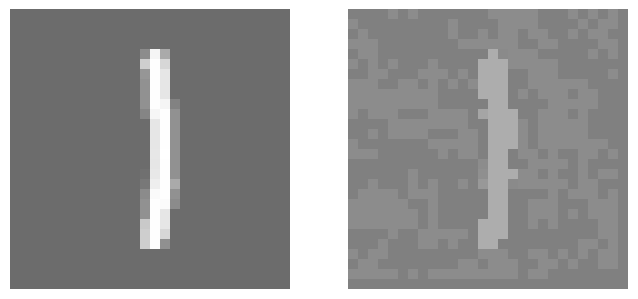


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


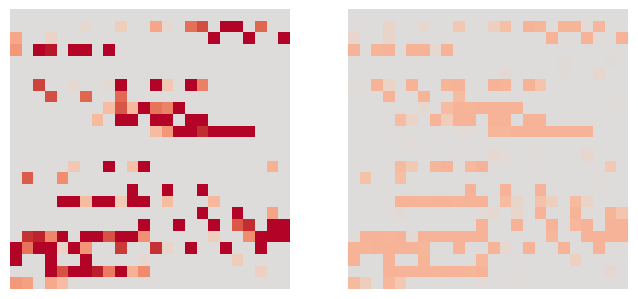

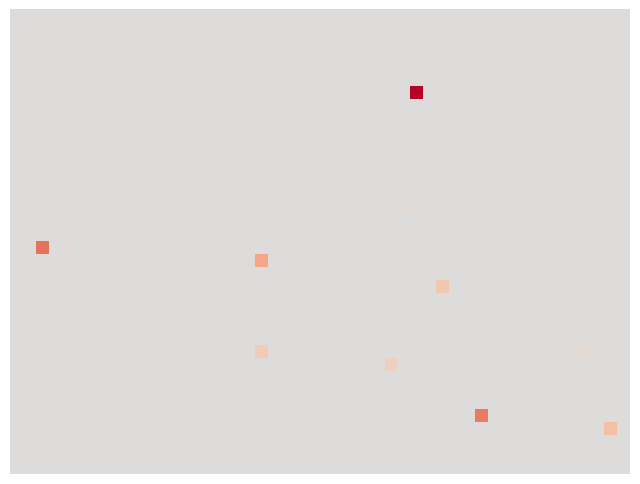


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


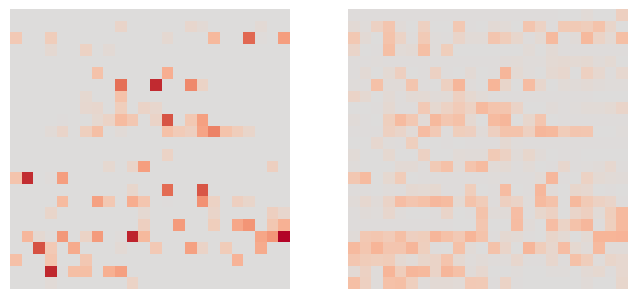

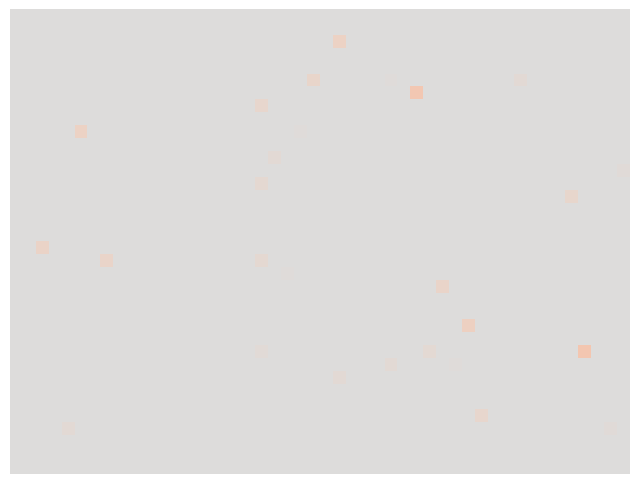

sae_encoding_adv - sae_encoding_init:


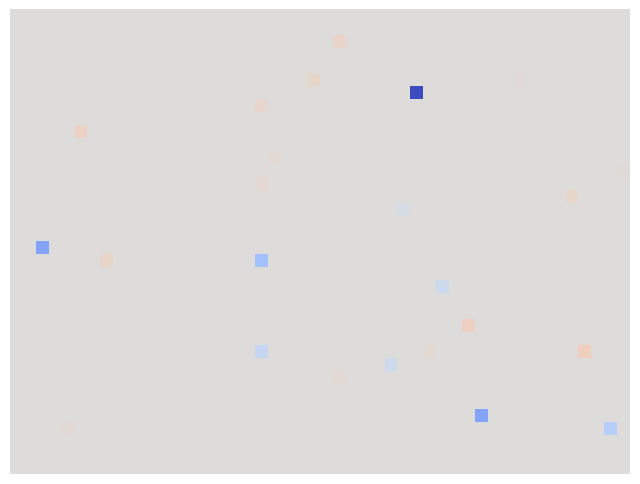

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


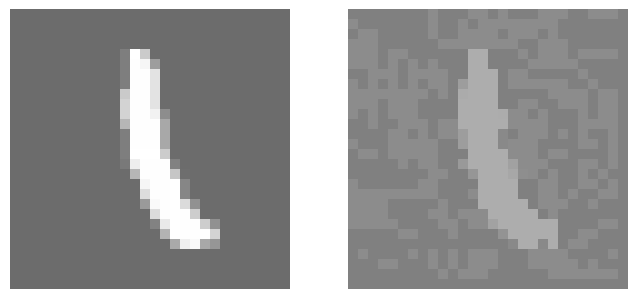


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


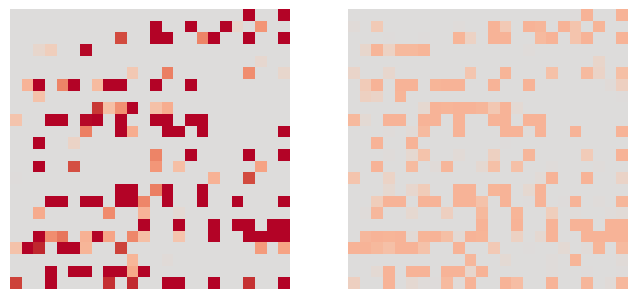

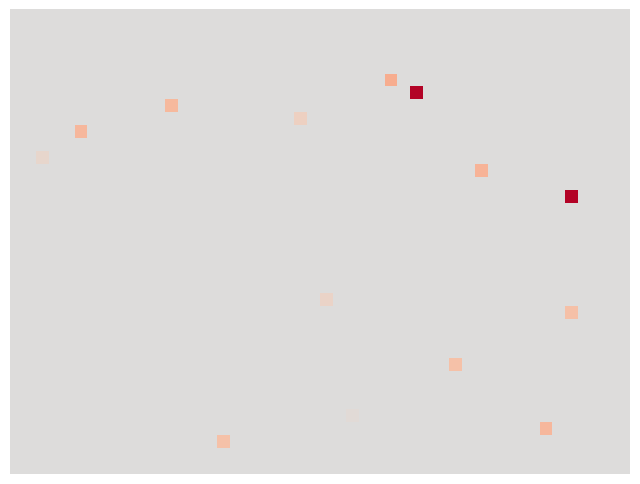


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


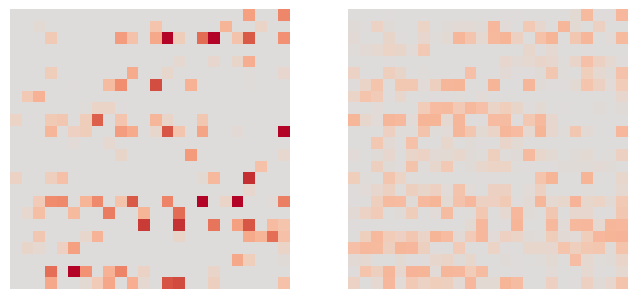

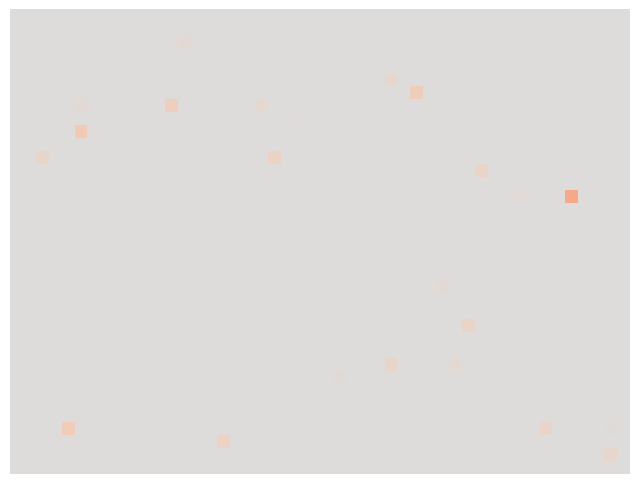

sae_encoding_adv - sae_encoding_init:


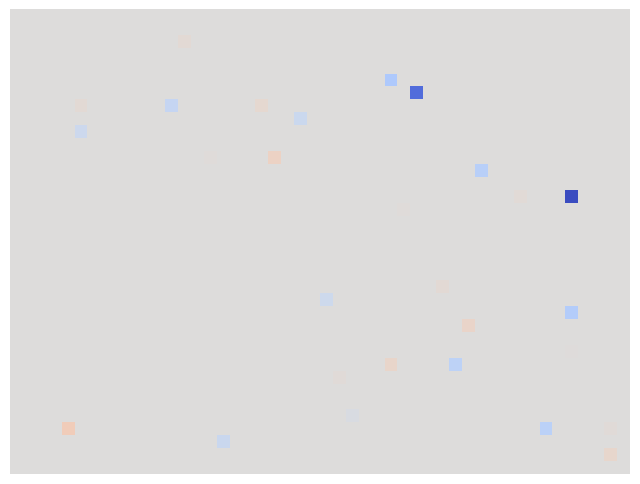

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


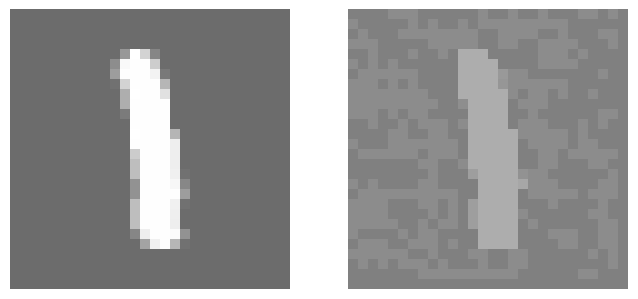


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


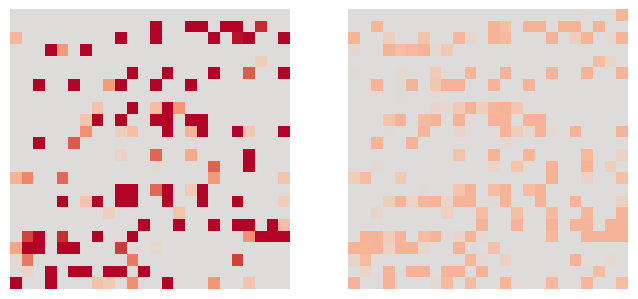

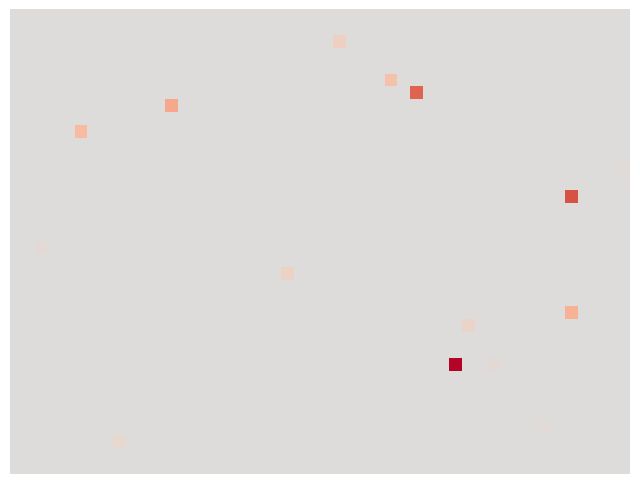


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


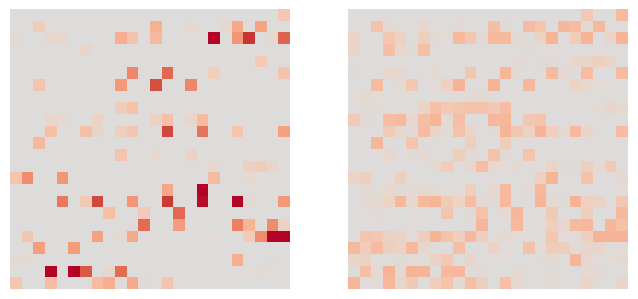

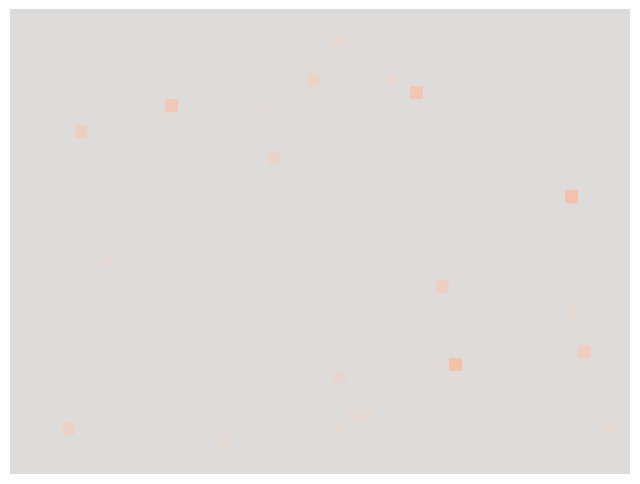

sae_encoding_adv - sae_encoding_init:


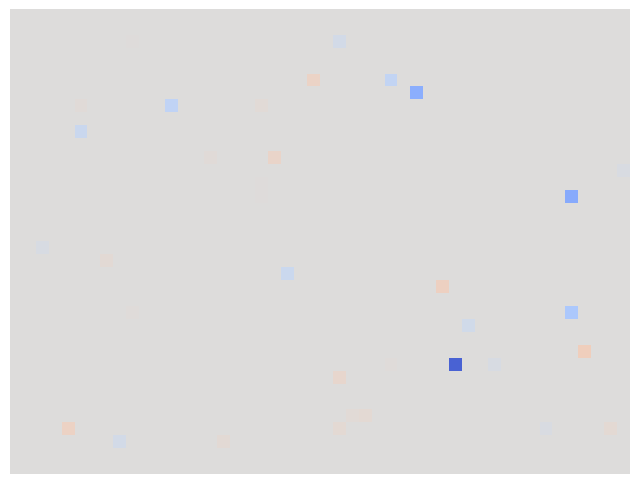

epsilon: 0.7
prediction changed from 1 to 4.
initial image, adv_image:


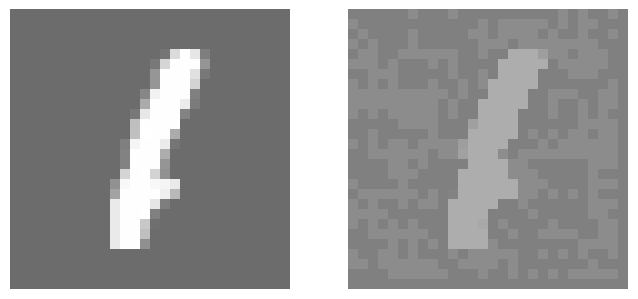


  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


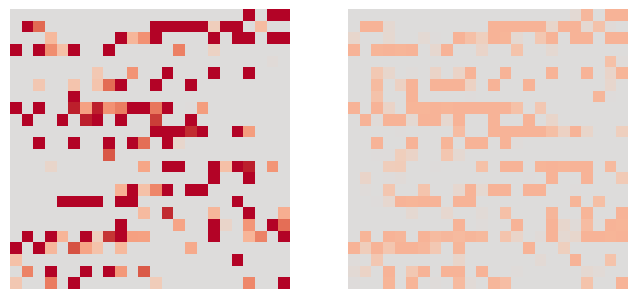

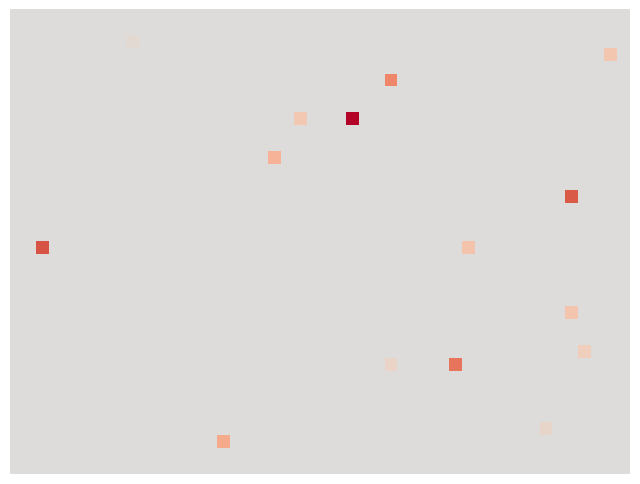


  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae


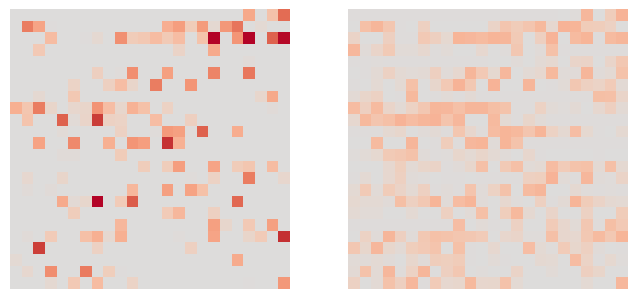

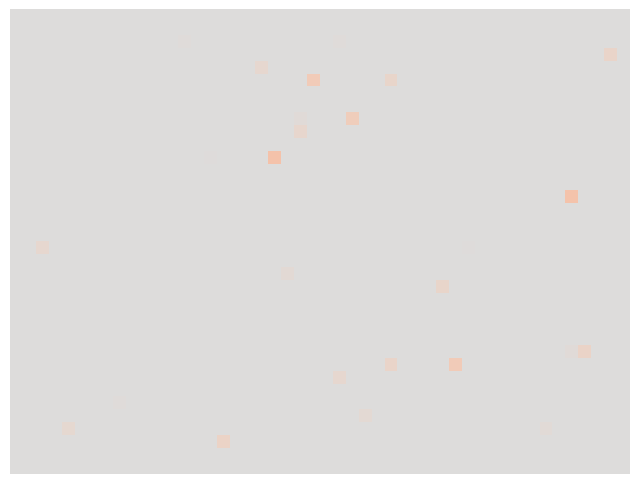

sae_encoding_adv - sae_encoding_init:


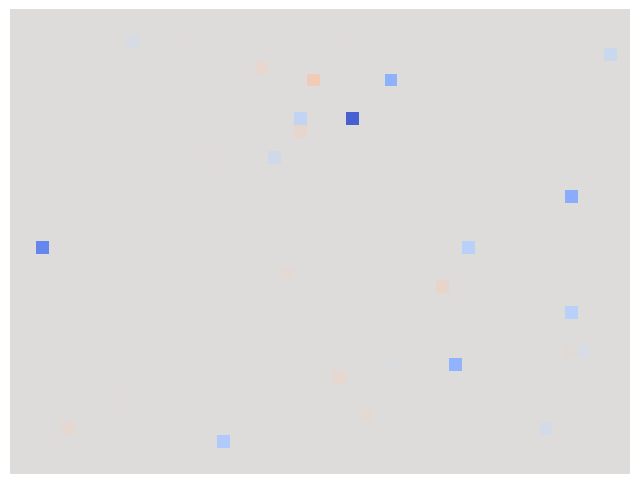

In [ ]:
epsilon_index = 7
ex_num = np.random.randint(3)

preds = (1, 4)
init_pred, final_pred = preds

init_image, adv_image = grouped[epsilon_index][preds][0]


for init_image, adv_image in grouped[epsilon_index][preds]:
  print(f"epsilon: {epsilons[epsilon_index]}")
  print(f"prediction changed from {init_pred} to {final_pred}.\ninitial image, adv_image:")
  temp = init_image.detach().cpu(), adv_image.detach().cpu()
  visualize_ims(temp, channel=0, cmap='gray')


  cmap='coolwarm'
  # feeding initial image
  cnn_model(init_image.unsqueeze(0).to(DEVICE))

  fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
  sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

  imgs = fc1_stored_inps.reshape(1, 1, 24, 24).cpu(), sae_rec.reshape(1, 1, 24, 24).detach().cpu()
  print("""
  INITIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae"""
  )
  visualize_ims(imgs, channel=0, cmap=cmap, norm=None)
  sae_encoding_init = sae_enc.reshape(1, 1, 36, 48).detach().cpu()
  visualize_ims(sae_encoding_init, channel=0, cmap=cmap)


  # feeding adversarial image
  cnn_model(adv_image.unsqueeze(0).to(DEVICE))

  fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
  sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

  imgs = fc1_stored_inps.reshape(1, 1, 24, 24).detach().cpu(), sae_rec.reshape(1, 1, 24, 24).detach().cpu()
  print("""
  ADVERSARIAL image
  left: Activations of the fc1 layer
  right: reconstructed activations of the fc1 layer
  bottom: encoding in the relevant sae"""
  )
  visualize_ims(imgs, channel=0, cmap=cmap, norm=None)
  sae_encoding_adv = sae_enc.reshape(1, 1, 36, 48).detach().cpu()
  visualize_ims(sae_encoding_adv, channel=0, cmap=cmap)


  encoding_dif = sae_encoding_adv - sae_encoding_init
  print('sae_encoding_adv - sae_encoding_init:')
  visualize_ims(encoding_dif, channel=0, cmap=cmap)
  stored_difs.append(encoding_dif)

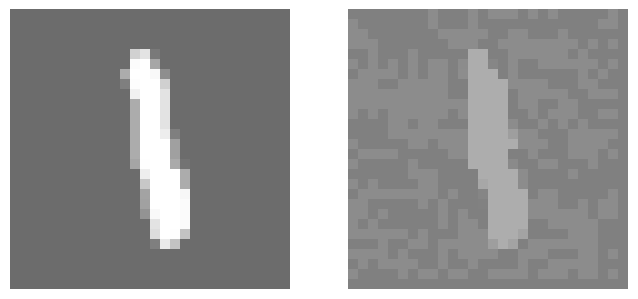

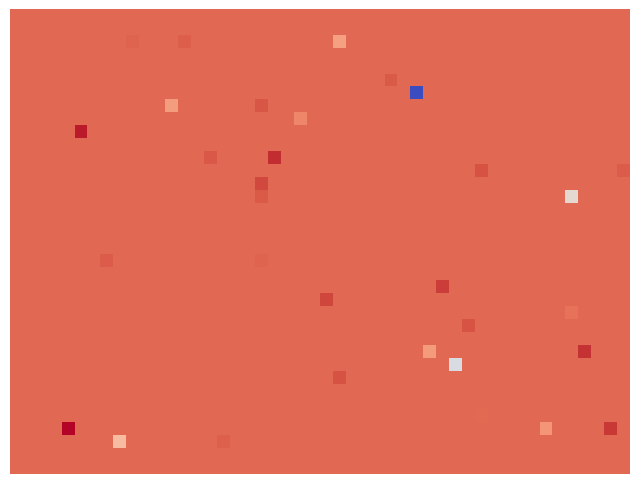

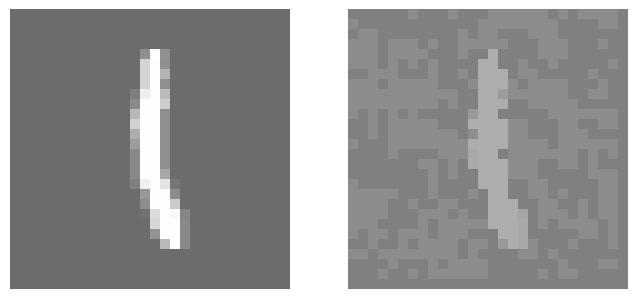

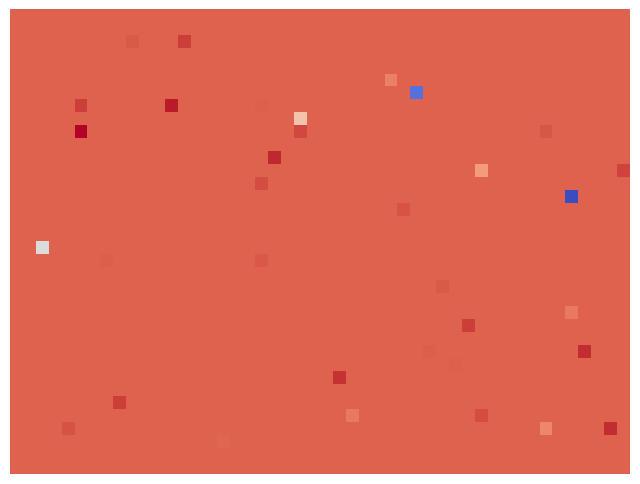

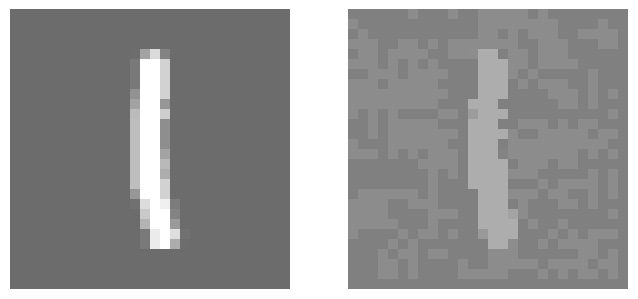

...

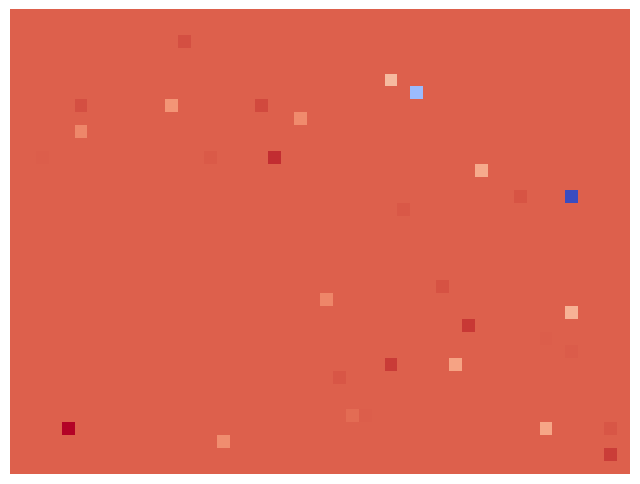

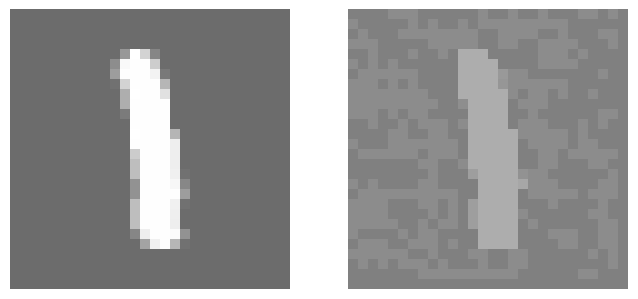

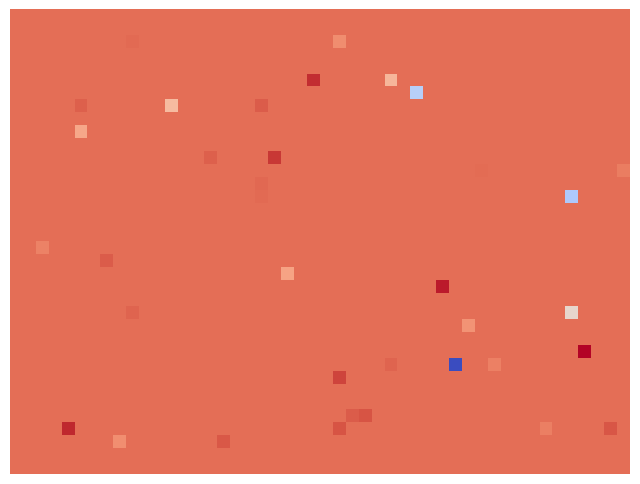

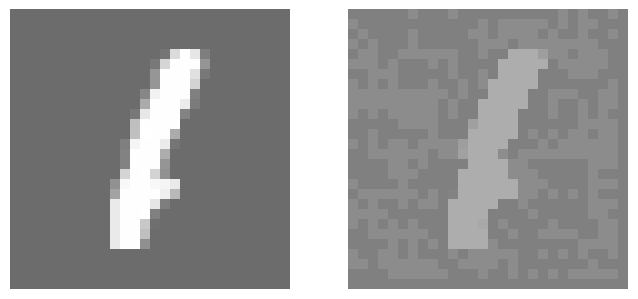

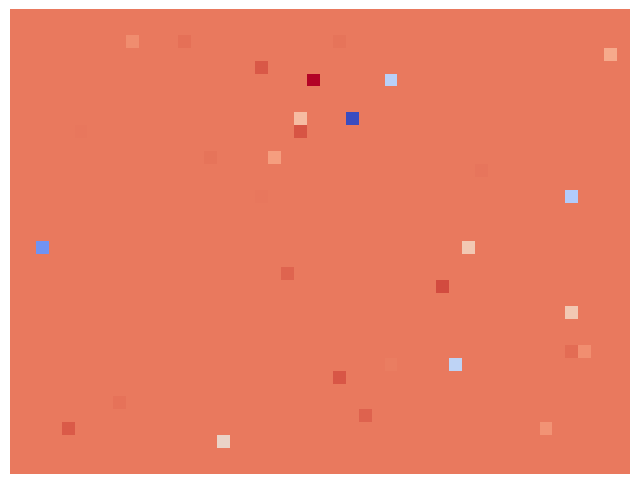

In [ ]:
i = 0
for init_image, adv_image in grouped[7][(1, 4)]:
  visualize_ims((init_image, adv_image), channel=0, cmap='gray')
  visualize_ims([stored_difs[i]], channel=0, cmap='coolwarm', norm=None)
  i+=1

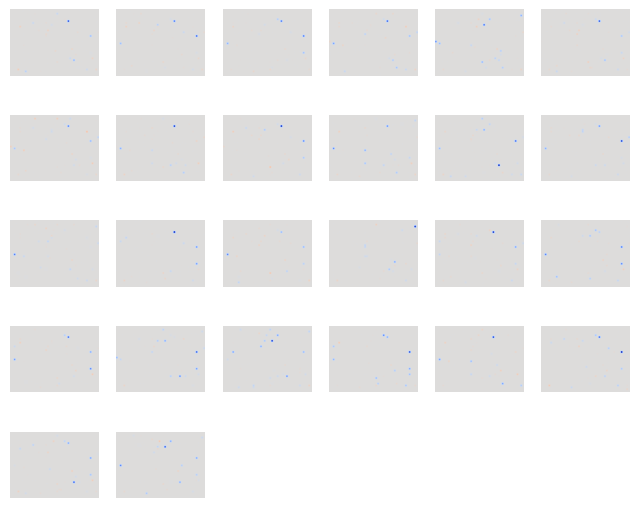

In [ ]:
visualize_ims(stored_difs, channel=0, cmap='coolwarm')

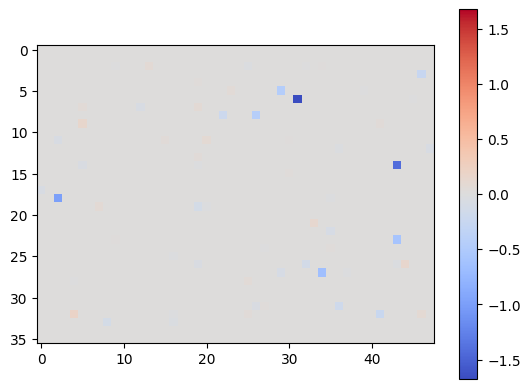

In [ ]:
from matplotlib.colors import CenteredNorm
# Calculate the average image
average_image = torch.sum(torch.stack(stored_difs), dim=0) / len(stored_difs)

# norm = TwoSlopeNorm(vmin=average_image.min(), vcenter=0, vmax=average_image.max())

plt.imshow(average_image.squeeze(), cmap='coolwarm', norm=CenteredNorm())
plt.colorbar()  # Add a color bar to interpret the colors
plt.show()

In [ ]:
class combo_model(nn.Module):
  def __init__(self, model, sae, layer):
    super().__init__()
    self.sae = sae
    self.model = model
    self.module_to_test = layer
    self.input_shape = model.input_shape

  def forward(self, x):
    self.model(x)
    return self.sae(self.module_to_test.stored_inputs.flatten(1))

In [ ]:
combo_model(cnn_model, saes_dict['fc1'], cnn_model.conv2)

combo_model(
  (sae): SparseAutoencoder(
    (encoder): Linear(in_features=576, out_features=1728, bias=True)
    (decoder): Linear(in_features=1728, out_features=576, bias=True)
  )
  (model): CNNModel(
    (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (conv3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (fc1): Linear(in_features=576, out_features=64, bias=True)
    (fc2): Linear(in_features=64, out_features=10, bias=True)
  )
  (module_to_test): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
)

In [ ]:
save_layer_shapes(saes_dict['fc1'])

{'encoder': (torch.Size([1, 576]), torch.Size([1, 1728])),
 'decoder': (torch.Size([1, 1728]), torch.Size([1, 576]))}

In [ ]:
store_activations(saes_dict['fc1'].decoder, hook_name='inputs', mode='inputs')

In [ ]:
tecombo_model_fc1 = combo_model(cnn_model, saes_dict['fc1'], layer=cnn_model.fc1)

In [ ]:
store_activations(cnn_model.fc1, 'inputs', mode='inputs')

Input activations are already being stored.
New hook will not be created.


In [ ]:
# ims = oifnil( model=cnn_model,
# layer=cnn_model.fc2,
# mode='activations',
# neuron_indices=torch.arange(10),
# device=DEVICE,
# init_inputs='zeros',
# num_steps=1000,
# to_penalize_other_activations = True,
# image_sparsity=1)

In [ ]:
imgs.shape

AttributeError: 'tuple' object has no attribute 'shape'

In [ ]:
# imgs = oifnil(model=combo_model_fc1,
#               layer=saes_dict['fc1'].decoder,
#               mode='inputs',
#               neuron_indices=torch.arange(576),
#               device=DEVICE,
#               init_inputs='random',
#               num_steps=20000,
#               to_penalize_other_activations=True,
#               rotation_angles=[-5, 5, 10],
#               alpha=200.0,
#               image_sparsity=1e-1)


# for i in range(len(imgs) // 100 + 1):
#   visualize_ims(imgs[100*i:100*(i+1)], channel=0)

In [ ]:
from collections import namedtuple

Pred = namedtuple('Pred', ['cnn_pred', 'sae_pred'])
AllPreds = namedtuple('AllPreds', ['initial', 'adv', 'random'])

prediction_data: list[AllPreds] = []

epsilon_index = 7
ex_num = np.random.randint(3)

preds = (1, 4)
init_pred, final_pred = preds

init_image, adv_image = grouped[epsilon_index][preds][0]

for init_image, adv_image in grouped[epsilon_index][preds]:
    # Junk image:
    junk_img = torch.zeros_like(init_image.unsqueeze(0))
    # Original image:
    # run CNN on init_img, store prediction, grab fc1 activations, and use SAE to reconstruct
    # use prehook to forward the reconstruction through the CNN and get the prediction

    cnn_model(init_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img).to(DEVICE)
    sae_pred = torch.argmax(logits).item()

    initial_prediction = Pred(preds[0], sae_pred)

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    # Adversarial image:
    # run CNN on adv_image, store prediction, grab fc1 activations, and use SAE to reconstruct
    #  use prehook to forward the reconstruction through the CNN and get the prediction

    cnn_model(adv_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img.to(DEVICE)).detach().cpu()
    sae_pred = torch.argmax(logits).item()

    adv_prediction = Pred(preds[1], sae_pred)

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    # Random image:
    # create a random pertubation mask by getting a bunch of 1s and -1s in the same shape as init_image and multiply by eps
    # add it to init_image, put it through CNN, store prediction and grab fc1 actvations
    # use sae to get reconstruction from fc1 activations, use prehook to forward the reconstruction through the CNN and get the prediction

    pertubation = (torch.rand_like(init_image) > 0.5).float() * 2 - 1
    pertubation *= epsilons[epsilon_index]
    rand_image = init_image + pertubation

    rand_cnn_pred_logits = cnn_model(rand_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img.to(DEVICE)).detach().cpu()
    sae_pred = torch.argmax(logits).item()
    rand_cnn_pred = torch.argmax(rand_cnn_pred_logits).item()

    rand_prediction = Pred(rand_cnn_pred, sae_pred)

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    prediction_data.append(AllPreds(initial_prediction, adv_prediction, rand_prediction))


print(prediction_data)

    # Tablulate: CNN prediction original, SAE prediction original, CNN prediction Adv, SAE prediction Adv, CNN prediction random, SAE prediction random

original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully re

In [ ]:
pred_data = np.array(prediction_data)

all_initials = pred_data[:,0,:]
all_adv = pred_data[:,1,:]
all_rand = pred_data[:,2,:]

# initial
both_right = (all_initials[:,0] == preds[0]) & (all_initials[:,1] == preds[0])
cnn_only = (all_initials[:,0] == preds[0]) & (all_initials[:,1] != preds[0])
sae_only = (all_initials[:,1] == preds[0]) & (all_initials[:,0] != preds[0])
neither = (all_initials[:,0] != preds[0]) & (all_initials[:,1] != preds[0])

initial_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])

# adv
both_right = (all_adv[:,0] == preds[0]) & (all_adv[:,1] == preds[0])
cnn_only = (all_adv[:,0] == preds[0]) & (all_adv[:,1] != preds[0])
sae_only = (all_adv[:,1] == preds[0]) & (all_adv[:,0] != preds[0])
neither = (all_adv[:,0] != preds[0]) & (all_adv[:,1] != preds[0])

adv_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])

# random
both_right = (all_rand[:,0] == preds[0]) & (all_rand[:,1] == preds[0])
cnn_only = (all_rand[:,0] == preds[0]) & (all_rand[:,1] != preds[0])
sae_only = (all_rand[:,1] == preds[0]) & (all_rand[:,0] != preds[0])
neither = (all_rand[:,0] != preds[0]) & (all_rand[:,1] != preds[0])

rand_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])


print(initial_correctness)
print(adv_correctness)
print(rand_correctness)


[26  0  0  0]
[ 0  0  8 18]
[19  2  1  4]


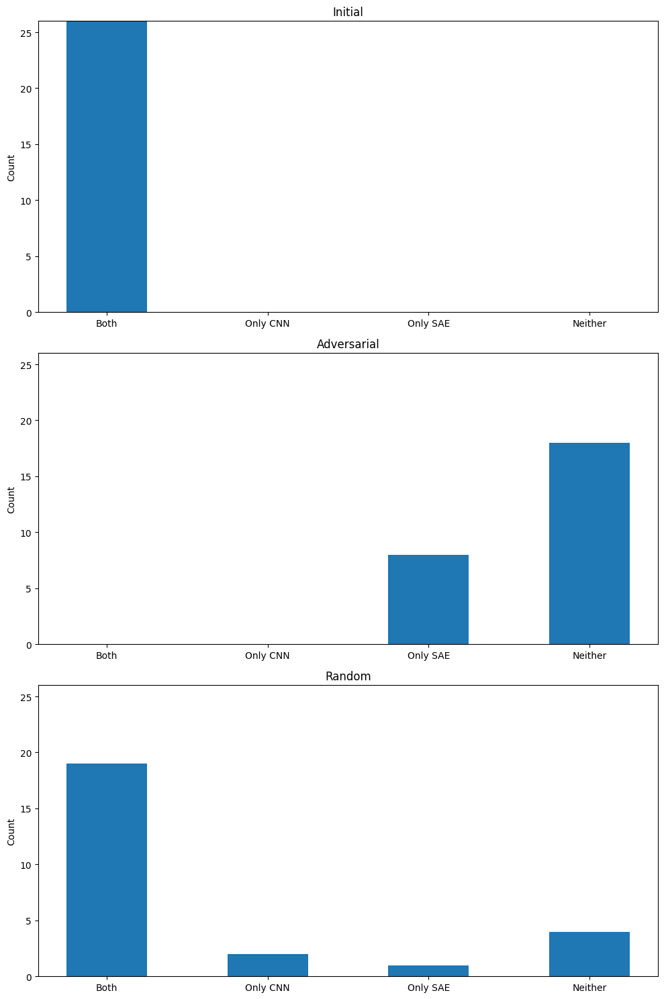

In [ ]:
# Labels
categories = ['Both', 'Only CNN', 'Only SAE', 'Neither']
conditions = ['Initial', 'Adversarial', 'Random']

# Set up the plot
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15))
x = np.arange(len(categories))
width = 0.5

# Find the maximum value in the entire dataset for y-axis limit
y_max = np.max([initial_correctness, adv_correctness, rand_correctness])

# Plot for Initial
ax1.bar(x, initial_correctness, width)
ax1.set_ylabel('Count')
ax1.set_title('Initial')
ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, y_max)

# Plot for Adversarial
ax2.bar(x, adv_correctness, width)
ax2.set_ylabel('Count')
ax2.set_title('Adversarial')
ax2.set_xticks(x)
ax2.set_xticklabels(categories)
ax2.set_ylim(0, y_max)

# Plot for Random
ax3.bar(x, rand_correctness, width)
ax3.set_ylabel('Count')
ax3.set_title('Random')
ax3.set_xticks(x)
ax3.set_xticklabels(categories)
ax3.set_ylim(0, y_max)

# Adjust layout and show plot
plt.tight_layout()
plt.show()

In [ ]:
from collections import namedtuple

Pred = namedtuple('Pred', ['cnn_pred', 'sae_pred', 'correct'])
AllPreds = namedtuple('AllPreds', ['initial', 'adv', 'random'])

prediction_data: list[AllPreds] = []

epsilon_index = 7

# preds = (1, 4)
# init_pred, final_pred = preds

# init_image, adv_image = grouped[epsilon_index][preds][0]

for initial_pred, final_pred, adv_image, init_image in examples[epsilon_index]:
    # Junk image:
    junk_img = torch.zeros_like(init_image.unsqueeze(0))
    # Original image:
    # run CNN on init_img, store prediction, grab fc1 activations, and use SAE to reconstruct
    # use prehook to forward the reconstruction through the CNN and get the prediction

    cnn_model(init_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img).to(DEVICE)
    sae_pred = torch.argmax(logits).item()

    initial_prediction = Pred(initial_pred.item(), sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    # Adversarial image:
    # run CNN on adv_image, store prediction, grab fc1 activations, and use SAE to reconstruct
    #  use prehook to forward the reconstruction through the CNN and get the prediction

    cnn_model(adv_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img.to(DEVICE)).detach().cpu()
    sae_pred = torch.argmax(logits).item()

    adv_prediction = Pred(final_pred.item(), sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    # Random image:
    # create a random pertubation mask by getting a bunch of 1s and -1s in the same shape as init_image and multiply by eps
    # add it to init_image, put it through CNN, store prediction and grab fc1 actvations
    # use sae to get reconstruction from fc1 activations, use prehook to forward the reconstruction through the CNN and get the prediction

    pertubation = (torch.rand_like(init_image) > 0.5).float() * 2 - 1
    pertubation *= epsilons[epsilon_index]
    rand_image = init_image + pertubation

    rand_cnn_pred_logits = cnn_model(rand_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img.to(DEVICE)).detach().cpu()
    sae_pred = torch.argmax(logits).item()
    rand_cnn_pred = torch.argmax(rand_cnn_pred_logits).item()

    rand_prediction = Pred(rand_cnn_pred, sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    prediction_data.append(AllPreds(initial_prediction, adv_prediction, rand_prediction))


print(prediction_data)

    # Tablulate: CNN prediction original, SAE prediction original, CNN prediction Adv, SAE prediction Adv, CNN prediction random, SAE prediction random

original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully re

In [ ]:
pred_data = np.array(prediction_data)

all_initials = pred_data[:,0,:]
all_adv = pred_data[:,1,:]
all_rand = pred_data[:,2,:]

# print(all_initials)


# initial
both_right = (all_initials[:,0] == all_initials[:,2]) & (all_initials[:,1] == all_initials[:,2])
cnn_only = (all_initials[:,0] == all_initials[:,2]) & (all_initials[:,1] != all_initials[:,2])
sae_only = (all_initials[:,1] == all_initials[:,2]) & (all_initials[:,0] != all_initials[:,2])
neither = (all_initials[:,0] != all_initials[:,2]) & (all_initials[:,1] != all_initials[:,2])

initial_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])

# adv
both_right = (all_adv[:,0] == all_adv[:,2]) & (all_adv[:,1] == all_adv[:,2])
cnn_only = (all_adv[:,0] == all_adv[:,2]) & (all_adv[:,1] != all_adv[:,2])
sae_only = (all_adv[:,1] == all_adv[:,2]) & (all_adv[:,0] != all_adv[:,2])
neither = (all_adv[:,0] != all_adv[:,2]) & (all_adv[:,1] != all_adv[:,2])

adv_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])

# random
both_right = (all_rand[:,0] == all_rand[:,2]) & (all_rand[:,1] == all_rand[:,2])
cnn_only = (all_rand[:,0] == all_rand[:,2]) & (all_rand[:,1] != all_rand[:,2])
sae_only = (all_rand[:,1] == all_rand[:,2]) & (all_rand[:,0] != all_rand[:,2])
neither = (all_rand[:,0] != all_rand[:,2]) & (all_rand[:,1] != all_rand[:,2])

rand_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])


print(initial_correctness)
print(adv_correctness)
print(rand_correctness)


[113  24   0   0]
[ 0  0 41 96]
[82 18 17 20]


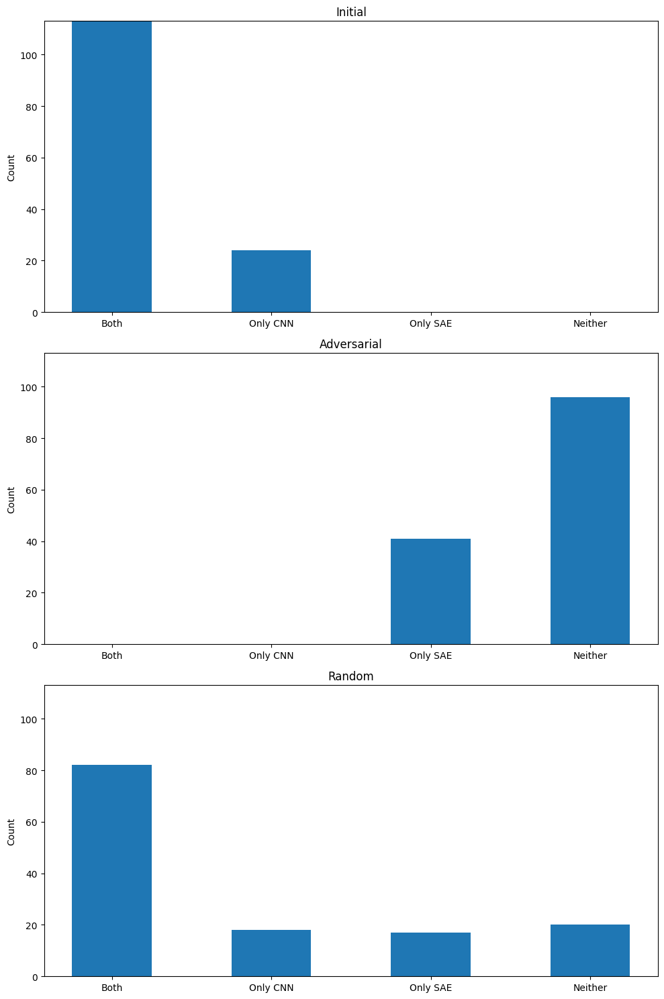

In [ ]:
# Labels
categories = ['Both', 'Only CNN', 'Only SAE', 'Neither']
conditions = ['Initial', 'Adversarial', 'Random']

# Set up the plot
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15))
x = np.arange(len(categories))
width = 0.5

# Find the maximum value in the entire dataset for y-axis limit
y_max = np.max([initial_correctness, adv_correctness, rand_correctness])

# Plot for Initial
ax1.bar(x, initial_correctness, width)
ax1.set_ylabel('Count')
ax1.set_title('Initial')
ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, y_max)

# Plot for Adversarial
ax2.bar(x, adv_correctness, width)
ax2.set_ylabel('Count')
ax2.set_title('Adversarial')
ax2.set_xticks(x)
ax2.set_xticklabels(categories)
ax2.set_ylim(0, y_max)

# Plot for Random
ax3.bar(x, rand_correctness, width)
ax3.set_ylabel('Count')
ax3.set_title('Random')
ax3.set_xticks(x)
ax3.set_xticklabels(categories)
ax3.set_ylim(0, y_max)

# Adjust layout and show plot
plt.tight_layout()
plt.show()

In [ ]:
from collections import namedtuple

Pred = namedtuple('Pred', ['cnn_pred', 'sae_pred', 'correct'])
AllPreds = namedtuple('AllPreds', ['initial', 'adv', 'random'])

prediction_data: list[AllPreds] = []

epsilon_index = 7

# preds = (1, 4)
# init_pred, final_pred = preds

# init_image, adv_image = grouped[epsilon_index][preds][0]

_, test_data = test(cnn_model, epsilons[epsilon_index], reference_test_loader, to_store_init_data=True, include_unsuccessful_adversarial=True)

for initial_pred, final_pred, adv_image, init_image in test_data:
    # Junk image:
    junk_img = torch.zeros_like(init_image.unsqueeze(0))
    # Original image:
    # run CNN on init_img, store prediction, grab fc1 activations, and use SAE to reconstruct
    # use prehook to forward the reconstruction through the CNN and get the prediction

    cnn_model(init_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img).to(DEVICE)
    sae_pred = torch.argmax(logits).item()

    initial_prediction = Pred(initial_pred.item(), sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    # Adversarial image:
    # run CNN on adv_image, store prediction, grab fc1 activations, and use SAE to reconstruct
    #  use prehook to forward the reconstruction through the CNN and get the prediction

    cnn_model(adv_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img.to(DEVICE)).detach().cpu()
    sae_pred = torch.argmax(logits).item()

    adv_prediction = Pred(final_pred.item(), sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    # Random image:
    # create a random pertubation mask by getting a bunch of 1s and -1s in the same shape as init_image and multiply by eps
    # add it to init_image, put it through CNN, store prediction and grab fc1 actvations
    # use sae to get reconstruction from fc1 activations, use prehook to forward the reconstruction through the CNN and get the prediction

    pertubation = (torch.rand_like(init_image) > 0.5).float() * 2 - 1
    pertubation *= epsilons[epsilon_index]
    rand_image = init_image + pertubation

    rand_cnn_pred_logits = cnn_model(rand_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img.to(DEVICE)).detach().cpu()
    sae_pred = torch.argmax(logits).item()
    rand_cnn_pred = torch.argmax(rand_cnn_pred_logits).item()

    rand_prediction = Pred(rand_cnn_pred, sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    prediction_data.append(AllPreds(initial_prediction, adv_prediction, rand_prediction))


print(prediction_data)

    # Tablulate: CNN prediction original, SAE prediction original, CNN prediction Adv, SAE prediction Adv, CNN prediction random, SAE prediction random

Streaming output truncated to the last 5000 lines.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully remo

In [ ]:
pred_data = np.array(prediction_data)

all_initials = pred_data[:,0,:]
all_adv = pred_data[:,1,:]
all_rand = pred_data[:,2,:]

# print(all_initials)


# initial
both_right = (all_initials[:,0] == all_initials[:,2]) & (all_initials[:,1] == all_initials[:,2])
cnn_only = (all_initials[:,0] == all_initials[:,2]) & (all_initials[:,1] != all_initials[:,2])
sae_only = (all_initials[:,1] == all_initials[:,2]) & (all_initials[:,0] != all_initials[:,2])
neither = (all_initials[:,0] != all_initials[:,2]) & (all_initials[:,1] != all_initials[:,2])

initial_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])

# adv
both_right = (all_adv[:,0] == all_adv[:,2]) & (all_adv[:,1] == all_adv[:,2])
cnn_only = (all_adv[:,0] == all_adv[:,2]) & (all_adv[:,1] != all_adv[:,2])
sae_only = (all_adv[:,1] == all_adv[:,2]) & (all_adv[:,0] != all_adv[:,2])
neither = (all_adv[:,0] != all_adv[:,2]) & (all_adv[:,1] != all_adv[:,2])

adv_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])

# random
both_right = (all_rand[:,0] == all_rand[:,2]) & (all_rand[:,1] == all_rand[:,2])
cnn_only = (all_rand[:,0] == all_rand[:,2]) & (all_rand[:,1] != all_rand[:,2])
sae_only = (all_rand[:,1] == all_rand[:,2]) & (all_rand[:,0] != all_rand[:,2])
neither = (all_rand[:,0] != all_rand[:,2]) & (all_rand[:,1] != all_rand[:,2])

rand_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])


print(initial_correctness)
print(adv_correctness)
print(rand_correctness)


[9767  146    0    0]
[9235  541   41   96]
[9439  329   53   92]


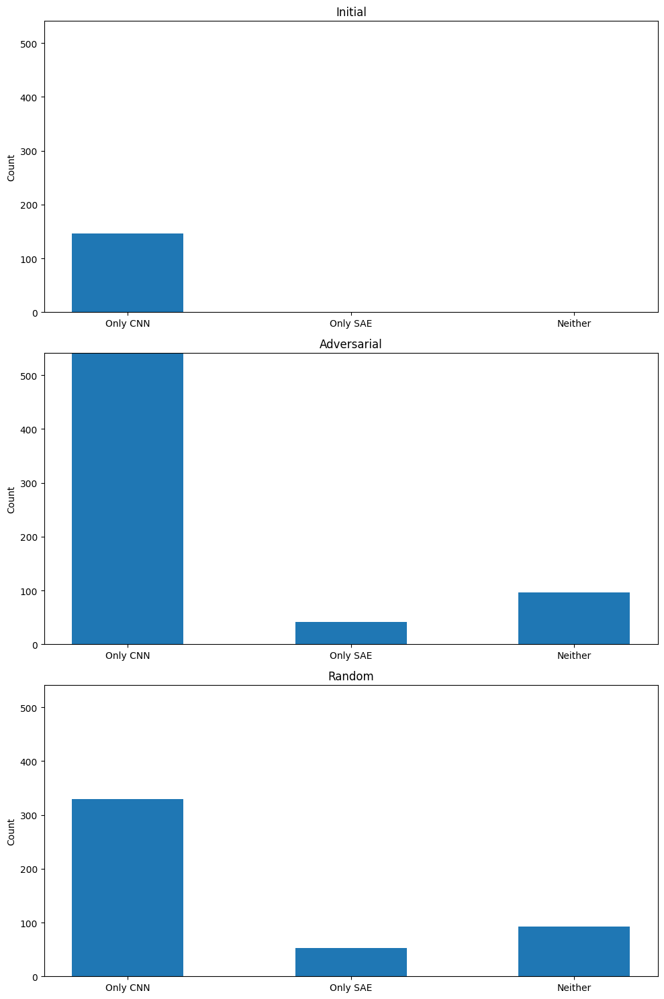

In [ ]:
# Labels
categories = ['Both', 'Only CNN', 'Only SAE', 'Neither'][1:]
conditions = ['Initial', 'Adversarial', 'Random']

initial_correctness = initial_correctness[1:]
adv_correctness = adv_correctness[1:]
rand_correctness = rand_correctness[1:]

# Set up the plot
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15))
x = np.arange(len(categories))
width = 0.5

# Find the maximum value in the entire dataset for y-axis limit
y_max = np.max([initial_correctness, adv_correctness, rand_correctness])

# Plot for Initial
ax1.bar(x, initial_correctness, width)
ax1.set_ylabel('Count')
ax1.set_title('Initial')
ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, y_max)

# Plot for Adversarial
ax2.bar(x, adv_correctness, width)
ax2.set_ylabel('Count')
ax2.set_title('Adversarial')
ax2.set_xticks(x)
ax2.set_xticklabels(categories)
ax2.set_ylim(0, y_max)

# Plot for Random
ax3.bar(x, rand_correctness, width)
ax3.set_ylabel('Count')
ax3.set_title('Random')
ax3.set_xticks(x)
ax3.set_xticklabels(categories)
ax3.set_ylim(0, y_max)

# Adjust layout and show plot
plt.tight_layout()
plt.show()

In [ ]:
from collections import namedtuple

Pred = namedtuple('Pred', ['cnn_pred', 'sae_pred', 'correct'])
AllPreds = namedtuple('AllPreds', ['initial', 'adv', 'random'])

prediction_data: list[AllPreds] = []

epsilon_index = 4

# preds = (1, 4)
# init_pred, final_pred = preds

# init_image, adv_image = grouped[epsilon_index][preds][0]

_, test_data = test(cnn_model, epsilons[epsilon_index], reference_train_loader, to_store_init_data=True, include_unsuccessful_adversarial=True)

for initial_pred, final_pred, adv_image, init_image in test_data:
    # Junk image:
    junk_img = torch.zeros_like(init_image.unsqueeze(0))
    # Original image:
    # run CNN on init_img, store prediction, grab fc1 activations, and use SAE to reconstruct
    # use prehook to forward the reconstruction through the CNN and get the prediction

    cnn_model(init_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img).to(DEVICE)
    sae_pred = torch.argmax(logits).item()

    initial_prediction = Pred(initial_pred.item(), sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    # Adversarial image:
    # run CNN on adv_image, store prediction, grab fc1 activations, and use SAE to reconstruct
    #  use prehook to forward the reconstruction through the CNN and get the prediction

    cnn_model(adv_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img.to(DEVICE)).detach().cpu()
    sae_pred = torch.argmax(logits).item()

    adv_prediction = Pred(final_pred.item(), sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    # Random image:
    # create a random pertubation mask by getting a bunch of 1s and -1s in the same shape as init_image and multiply by eps
    # add it to init_image, put it through CNN, store prediction and grab fc1 actvations
    # use sae to get reconstruction from fc1 activations, use prehook to forward the reconstruction through the CNN and get the prediction

    pertubation = (torch.rand_like(init_image) > 0.5).float() * 2 - 1
    pertubation *= epsilons[epsilon_index]
    rand_image = init_image + pertubation

    rand_cnn_pred_logits = cnn_model(rand_image.unsqueeze(0).to(DEVICE))

    fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
    sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

    custom_input_pre_hook(cnn_model.fc1, sae_rec, 'original_image_prehook')

    logits = cnn_model(junk_img.to(DEVICE)).detach().cpu()
    sae_pred = torch.argmax(logits).item()
    rand_cnn_pred = torch.argmax(rand_cnn_pred_logits).item()

    rand_prediction = Pred(rand_cnn_pred, sae_pred, initial_pred.item())

    cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()

    prediction_data.append(AllPreds(initial_prediction, adv_prediction, rand_prediction))


print(prediction_data)

    # Tablulate: CNN prediction original, SAE prediction original, CNN prediction Adv, SAE prediction Adv, CNN prediction random, SAE prediction random

Streaming output truncated to the last 5000 lines.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully remo

In [ ]:
pred_data = np.array(prediction_data)

all_initials = pred_data[:,0,:]
all_adv = pred_data[:,1,:]
all_rand = pred_data[:,2,:]

# print(all_initials)


# initial
both_right = (all_initials[:,0] == all_initials[:,2]) & (all_initials[:,1] == all_initials[:,2])
cnn_only = (all_initials[:,0] == all_initials[:,2]) & (all_initials[:,1] != all_initials[:,2])
sae_only = (all_initials[:,1] == all_initials[:,2]) & (all_initials[:,0] != all_initials[:,2])
neither = (all_initials[:,0] != all_initials[:,2]) & (all_initials[:,1] != all_initials[:,2])

initial_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])
initial_correctness_2 = np.count_nonzero([both_right.flatten(), cnn_only.flatten(), sae_only.flatten(), neither.flatten()], axis=1)
# adv
both_right = (all_adv[:,0] == all_adv[:,2]) & (all_adv[:,1] == all_adv[:,2])
cnn_only = (all_adv[:,0] == all_adv[:,2]) & (all_adv[:,1] != all_adv[:,2])
sae_only = (all_adv[:,1] == all_adv[:,2]) & (all_adv[:,0] != all_adv[:,2])
neither = (all_adv[:,0] != all_adv[:,2]) & (all_adv[:,1] != all_adv[:,2])

adv_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])

# random
both_right = (all_rand[:,0] == all_rand[:,2]) & (all_rand[:,1] == all_rand[:,2])
cnn_only = (all_rand[:,0] == all_rand[:,2]) & (all_rand[:,1] != all_rand[:,2])
sae_only = (all_rand[:,1] == all_rand[:,2]) & (all_rand[:,0] != all_rand[:,2])
neither = (all_rand[:,0] != all_rand[:,2]) & (all_rand[:,1] != all_rand[:,2])

rand_correctness = np.array([np.count_nonzero(both_right), np.count_nonzero(cnn_only), np.count_nonzero(sae_only), np.count_nonzero(neither)])


print(initial_correctness, initial_correctness_2)
print(adv_correctness)
print(rand_correctness)


[58833  1088     0     0] [58833  1088     0     0]
[58069  1577    95   180]
[58360  1399    79    83]


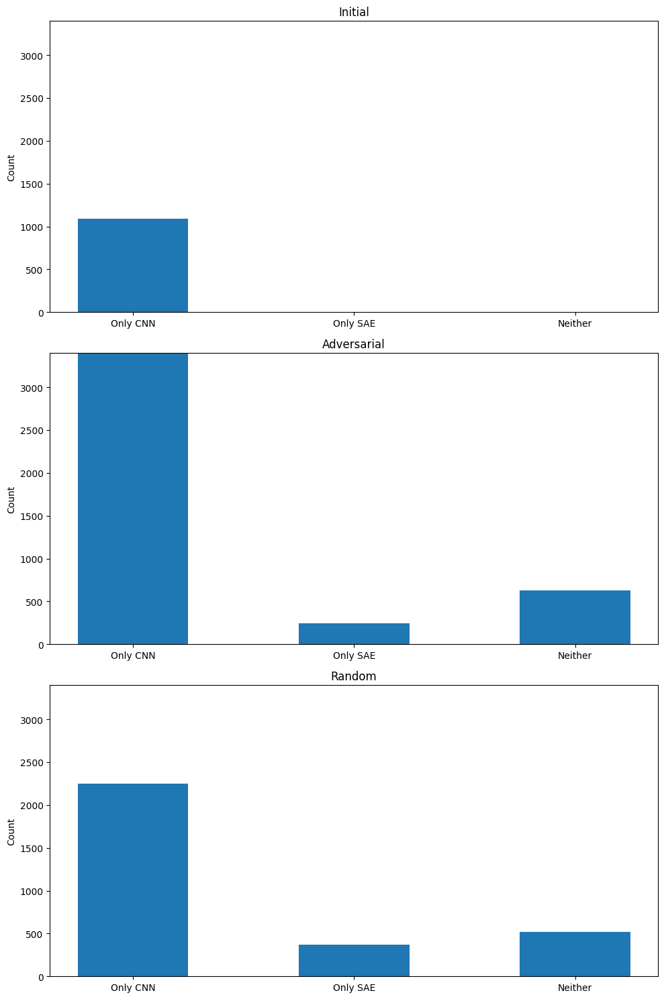

In [ ]:
initial_correctness = np.array([58833  1088     0     0])
# Labels
categories = ['Both', 'Only CNN', 'Only SAE', 'Neither'][1:]
conditions = ['Initial', 'Adversarial', 'Random']

initial_correctness = initial_correctness[1:]
adv_correctness = adv_correctness[1:]
rand_correctness = rand_correctness[1:]

# Set up the plot
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15))
x = np.arange(len(categories))
width = 0.5

# Find the maximum value in the entire dataset for y-axis limit
y_max = np.max([initial_correctness, adv_correctness, rand_correctness])

# Plot for Initial
ax1.bar(x, initial_correctness, width)
ax1.set_ylabel('Count')
ax1.set_title('Initial')
ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, y_max)

# Plot for Adversarial
ax2.bar(x, adv_correctness, width)
ax2.set_ylabel('Count')
ax2.set_title('Adversarial')
ax2.set_xticks(x)
ax2.set_xticklabels(categories)
ax2.set_ylim(0, y_max)

# Plot for Random
ax3.bar(x, rand_correctness, width)
ax3.set_ylabel('Count')
ax3.set_title('Random')
ax3.set_xticks(x)
ax3.set_xticklabels(categories)
ax3.set_ylim(0, y_max)

# Adjust layout and show plot
plt.tight_layout()
plt.show()

In [ ]:
import torch.nn.functional as F

def test_random(model, epsilon, loader, device=DEVICE, *, to_store_init_data=False, include_unsuccessful_adversarial=False):

    # Accuracy counter

    correct = 0
    sae_correct = 0
    adv_examples = []

    # Loop over all examples in test set
    for data, targets in loader:

        # Set requires_grad attribute of tensor. Important for Attack
        data = data.to(device)

        targets = targets.to(device)
        data.requires_grad = True
        # junk_img = torch.zeros_like(data.unsqueeze(0))
        # Forward pass the data through the model
        output = model(data)

        init_preds = output.max(1)[1] # get the index of the max

        if epsilon != 0:
        # Calculate the loss
          vectorized_targets = torch.eye(10).to(device)[targets]
          loss = F.mse_loss(output, vectorized_targets)

          # Zero all existing gradients
          model.zero_grad()

          # Calculate gradients of model in backward pass
          loss.backward()

          # Collect ``datagrad``
          data_grad = data.grad.data

          # Add random pertubation
          pertubation = (torch.rand_like(data) > 0.5).float() * 2 - 1
          pertubation *= epsilon
          perturbed_data = (data + pertubation).to(device)

          # Re-classify the perturbed image
          output = model(perturbed_data)

        # fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
        # sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

        # custom_input_pre_hook(model.fc1, sae_rec, 'original_image_prehook')

        # logits = model(junk_img).to(DEVICE)
        # # sae_pred = torch.argmax(logits).item()
        # sae_pred = logits.max(1)[1]

        # model.fc1.pre_hooks['original_image_prehook'].custom_remove()

        # Check for success
          final_preds = output.max(1)[1] # get the index of the max log-probability
          # shape: (B,)

          with torch.no_grad():
              correct += torch.sum(final_preds == targets)
              # sae_correct += torch.sum(sae_pred == targets)



        # else: # epsilon == 0
        #     with torch.no_grad():
        #         mask = (init_preds == targets).cpu()
        #         correct += torch.sum(mask)
        #         sae_correct += torch.sum(sae_pred == targets)



    # Calculate final accuracy for this epsilon
    final_acc = correct/float(len(loader) * loader.batch_size)
    # final_acc_sae = sae_correct/float(len(loader)*loader.batch_size)
    # print(f"Epsilon: {epsilon}\tTest Accuracy = {correct} / {len(loader) * loader.batch_size} = {final_acc}\t SAE Test Accuracy = {sae_correct} / {len(loader)*loader.batch_size} = {final_acc_sae}")

    # Return the accuracy and an adversarial example
    return final_acc.item(), 0, adv_examples

In [ ]:
accuracies = []
sae_accuracies = []
# examples = []
epsilons = np.arange(1,10) / 10.0

torch.manual_seed(42)
# Run test for each epsilon
for eps in epsilons:
    acc, sae_acc, ex = test_random(cnn_model, epsilon=eps, loader=reference_test_loader, device=DEVICE, to_store_init_data=True)
    accuracies.append(acc)
    sae_accuracies.append(sae_acc)
    # examples.append(ex)

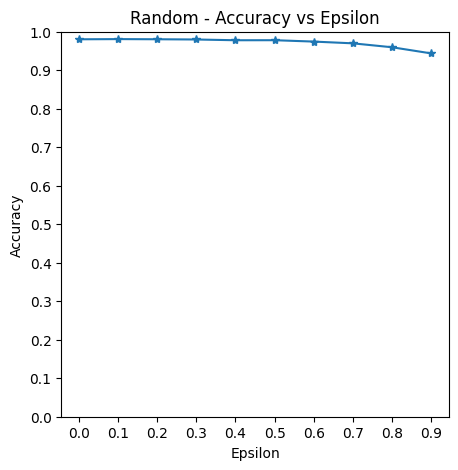

In [ ]:
plt.figure(figsize=(5,5))
plt.plot(epsilons, accuracies, "*-")
plt.yticks(np.arange(0, 1.1, step=0.1))
plt.xticks(epsilons)
plt.title("Random - Accuracy vs Epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Accuracy")
plt.show()

In [ ]:
import torch.nn.functional as F

def test_v2(model, epsilon, loader, device=DEVICE, *, to_store_init_data=False, include_unsuccessful_adversarial=False):

    # Accuracy counter

    random_cnn_correct = 0
    random_sae_correct = 0

    initial_cnn_correct = 0
    initial_sae_correct = 0

    adversarial_cnn_correct = 0
    adversarial_sae_correct = 0

    # Loop over all examples in test set
    for data, targets in loader:

        # Set requires_grad attribute of tensor. Important for Attack
        data = data.to(device)
        targets = targets.to(device)
        data.requires_grad = True
        junk_img = torch.zeros_like(data)
        # Forward pass the data through the model
        output = model(data.detach())

        # init_preds = output.max(1)[1] # get the index of the max

        num_to_store = 60_000

        if epsilon != 0:
        # Calculate the loss
            vectorized_targets = torch.eye(10).to(device)[targets]
            loss = F.mse_loss(output, vectorized_targets)

            # Zero all existing gradients
            model.zero_grad()

            # Calculate gradients of model in backward pass
            loss.backward()

            # Collect ``datagrad``
            data_grad = data.grad.data

            ######## Random ################
            # Add random pertubation
            pertubation = (torch.rand_like(data.detach()) > 0.5).float() * 2 - 1
            pertubation *= epsilon
            perturbed_data = (data.detach() + pertubation).to(device)

            # Re-classify the perturbed image
            output = model(perturbed_data)

            # Check for success
            random_final_preds = output.max(1)[1] # get the index of the max log-probability
            # shape: (B,)

            fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
            sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

            custom_input_pre_hook_old(model.fc1, sae_rec, 'original_image_prehook')

            logits = model(junk_img).to(DEVICE)
            # # sae_pred = torch.argmax(logits).item()
            random_sae_pred = logits.detach().cpu().max(1)[1]

            model.fc1.pre_hooks['original_image_prehook'].custom_remove()

            ######### Initial #################
            output = model(data)

            initial_final_preds = output.max(1)[1]

            fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
            sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

            custom_input_pre_hook(model.fc1, sae_rec, 'original_image_prehook')

            logits = model(junk_img).to(DEVICE)
            # # sae_pred = torch.argmax(logits).item()
            initial_sae_pred = logits.detach().cpu().max(1)[1]

            model.fc1.pre_hooks['original_image_prehook'].custom_remove()

            ############# Adversarial ###########
             # Call FGSM Attack
            perturbed_data = fgsm_attack(data, epsilon, data_grad).to(device)

            # Re-classify the perturbed image
            output = model(perturbed_data)

            # Check for success
            adv_final_preds = output.max(1)[1] # get the index of the max log-probability
            # shape: (B,)

            fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
            sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

            custom_input_pre_hook_old(model.fc1, sae_rec, 'original_image_prehook')

            logits = model(junk_img).to(DEVICE)
            # # sae_pred = torch.argmax(logits).item()
            adv_sae_pred = logits.detach().cpu().max(1)[1]

            model.fc1.pre_hooks['original_image_prehook'].custom_remove()


            with torch.no_grad():
                random_cnn_correct += torch.sum(random_final_preds == targets)
                random_sae_correct += torch.sum(random_sae_pred.to(device) == targets)

                initial_cnn_correct += torch.sum(initial_final_preds == targets)
                initial_sae_correct += torch.sum(initial_sae_pred.to(device) == targets)

                adversarial_cnn_correct += torch.sum(adv_final_preds == targets)
                adversarial_sae_correct += torch.sum(adv_sae_pred.to(device) == targets)



        else: # epsilon == 0
          # Re-classify the perturbed image
            # data = data.detach()
            # data.requires_grad = True
            output = model(data)

            # Check for success
            final_preds = output.max(1)[1] # get the index of the max log-probability
            # shape: (B,)

            fc1_stored_inps = cnn_model.fc1.stored_inputs.detach()
            sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

            custom_input_pre_hook_old(model.fc1, sae_rec, 'original_image_prehook')

            logits = model(junk_img).to(DEVICE)
            # # sae_pred = torch.argmax(logits).item()
            sae_pred = logits.detach().cpu().max(1)[1]

            model.fc1.pre_hooks['original_image_prehook'].custom_remove()

            with torch.no_grad():
                mask = (final_preds == targets).cpu()
                correct = torch.sum(mask)
                random_cnn_correct += correct
                initial_cnn_correct += correct
                adversarial_cnn_correct += correct

                sae_correct = torch.sum(sae_pred.to(device) == targets)

                random_sae_correct += sae_correct
                initial_sae_correct += sae_correct
                adversarial_sae_correct += sae_correct


    # Calculate final accuracy for this epsilon
    denom = float(len(loader) * loader.batch_size)

    initial_final_acc = initial_cnn_correct / denom
    initial_final_acc_sae = initial_sae_correct / denom

    random_final_acc = random_cnn_correct / denom
    random_final_acc_sae = random_sae_correct / denom

    adv_final_acc = adversarial_cnn_correct / denom
    adv_final_acc_sae = adversarial_sae_correct / denom

    # print(f"Epsilon: {epsilon}\tTest Accuracy = {correct} / {len(loader) * loader.batch_size} = {final_acc}\t SAE Test Accuracy = {sae_correct} / {len(loader)*loader.batch_size} = {final_acc_sae}")

    # Return the accuracy and an adversarial example
    return initial_final_acc.item(), initial_final_acc_sae.item(), random_final_acc.item(), random_final_acc_sae.item(), adv_final_acc.item(), adv_final_acc_sae.item()

In [ ]:
cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()


original_image_prehook hook was succesfully removed.


In [ ]:
def fgsm_attack_2(data, epsilon, data_grad):
    # Collect the element-wise sign of the data gradient
    sign_data_grad = data_grad.sign()
    # print(f"data_grad = {data_grad}")
    # print(f"sign_data_grad = {sign_data_grad}")
    # Create the perturbed image by adjusting each pixel of the input image
    delta = epsilon * sign_data_grad
    perturbed_data = data + delta
    # Adding clipping to maintain [0,1] range
    perturbed_data = torch.clamp(perturbed_data, 0, 1)
    # Return the perturbed image
    return perturbed_data

In [ ]:
def test_v3(model, epsilon, loader, device=DEVICE, *, to_store_init_data=False, include_unsuccessful_adversarial=False):
    # Accuracy counters
    random_cnn_correct = 0
    random_sae_correct = 0
    initial_cnn_correct = 0
    initial_sae_correct = 0
    adversarial_cnn_correct = 0
    adversarial_sae_correct = 0

    # Loop over all examples in test set
    for data, targets in loader:
        # Move data and targets to the specified device
        data = data.to(device)
        targets = targets.to(device)

        # Create a copy of data that requires gradients
        data_grad_enabled = data.clone().detach().requires_grad_(True)

        junk_img = torch.zeros_like(data)

        if epsilon != 0:
            # Forward pass the data through the model
            output = model(data_grad_enabled)

            # Calculate the loss
            vectorized_targets = torch.eye(10).to(device)[targets]
            loss = F.mse_loss(output, vectorized_targets)

            # Zero all existing gradients
            model.zero_grad()

            # Calculate gradients of model in backward pass
            loss.backward()

            # Collect datagrad
            data_grad = data_grad_enabled.grad.data

            ############# Adversarial ###########
            # Call FGSM Attack
            perturbed_data = fgsm_attack(data_grad_enabled, epsilon, data_grad).to(device)

            # Re-classify the perturbed image
            output = model(perturbed_data)
            adv_final_preds = output.max(1)[1]

            fc1_stored_inps = model.fc1.stored_inputs.detach()
            sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

            custom_input_pre_hook_old(model.fc1, sae_rec, 'original_image_prehook')
            logits = model(junk_img).to(device)
            adv_sae_pred = logits.detach().cpu().max(1)[1]
            model.fc1.pre_hooks['original_image_prehook'].custom_remove()


            ######## Random ################
            # Add random perturbation
            perturbation = (torch.rand_like(data) > 0.5).float() * 2 - 1
            perturbation = torch.sign(perturbation) * epsilon
            perturbed_data = torch.clamp(data_grad_enabled.clone().detach() + perturbation, 0, 1)

            # perturbation *= epsilon
            perturbed_data = perturbed_data.to(device)

            # Re-classify the perturbed image
            output = model(perturbed_data)
            random_final_preds = output.max(1)[1]

            fc1_stored_inps = model.fc1.stored_inputs.detach()
            sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

            custom_input_pre_hook_old(model.fc1, sae_rec, 'original_image_prehook')
            logits = model(junk_img).to(device)
            random_sae_pred = logits.detach().cpu().max(1)[1]
            model.fc1.pre_hooks['original_image_prehook'].custom_remove()

            ######### Initial #################
            output = model(data)
            initial_final_preds = output.max(1)[1]

            fc1_stored_inps = model.fc1.stored_inputs.detach()
            sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

            custom_input_pre_hook_old(model.fc1, sae_rec, 'original_image_prehook')
            logits = model(junk_img).to(device)
            initial_sae_pred = logits.detach().cpu().max(1)[1]
            model.fc1.pre_hooks['original_image_prehook'].custom_remove()


            with torch.no_grad():
                random_cnn_correct += torch.sum(random_final_preds == targets)
                random_sae_correct += torch.sum(random_sae_pred.to(device) == targets)
                initial_cnn_correct += torch.sum(initial_final_preds == targets)
                initial_sae_correct += torch.sum(initial_sae_pred.to(device) == targets)
                adversarial_cnn_correct += torch.sum(adv_final_preds == targets)
                adversarial_sae_correct += torch.sum(adv_sae_pred.to(device) == targets)

        else:  # epsilon == 0
            output = model(data)
            final_preds = output.max(1)[1]

            fc1_stored_inps = model.fc1.stored_inputs.detach()
            sae_enc, sae_rec = saes_dict['fc1'](fc1_stored_inps)

            custom_input_pre_hook_old(model.fc1, sae_rec, 'original_image_prehook')
            logits = model(junk_img).to(device)
            sae_pred = logits.detach().cpu().max(1)[1]
            model.fc1.pre_hooks['original_image_prehook'].custom_remove()

            with torch.no_grad():
                mask = (final_preds == targets).cpu()
                correct = torch.sum(mask)
                random_cnn_correct += correct
                initial_cnn_correct += correct
                adversarial_cnn_correct += correct

                sae_correct = torch.sum(sae_pred.to(device) == targets)
                random_sae_correct += sae_correct
                initial_sae_correct += sae_correct
                adversarial_sae_correct += sae_correct

    # Calculate final accuracy for this epsilon
    denom = float(len(loader) * loader.batch_size)

    initial_final_acc = initial_cnn_correct / denom
    initial_final_acc_sae = initial_sae_correct / denom
    random_final_acc = random_cnn_correct / denom
    random_final_acc_sae = random_sae_correct / denom
    adv_final_acc = adversarial_cnn_correct / denom
    adv_final_acc_sae = adversarial_sae_correct / denom

    return (
        initial_final_acc.item(),
        initial_final_acc_sae.item(),
        random_final_acc.item(),
        random_final_acc_sae.item(),
        adv_final_acc.item(),
        adv_final_acc_sae.item()
    )

In [ ]:
accuracies = []
sae_accuracies = []

initial_acc_cnns = []
initial_acc_saes = []
random_acc_cnns = []
random_acc_saes = []
adv_acc_cnns = []
adv_acc_saes = []
# examples = []
epsilons = np.arange(10) / 10.0

torch.manual_seed(42)
# Run test for each epsilon
for eps in epsilons:
    initial_acc_cnn, initial_acc_sae, random_acc_cnn, random_acc_sae, adv_acc_cnn, adv_acc_sae = test_v3(cnn_model, epsilon=eps, loader=reference_test_loader, device=DEVICE, to_store_init_data=True)
    initial_acc_cnns.append(initial_acc_cnn)
    initial_acc_saes.append(initial_acc_sae)
    random_acc_cnns.append(random_acc_cnn)
    random_acc_saes.append(random_acc_sae)
    adv_acc_cnns.append(adv_acc_cnn)
    adv_acc_saes.append(adv_acc_sae)

original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully removed.
original_image_prehook hook was succesfully re

In [ ]:
cnn_model.fc1.pre_hooks['original_image_prehook'].custom_remove()


KeyError: 'original_image_prehook'

In [ ]:
cnn_model(examples[0][0][2].unsqueeze(0).to(DEVICE))

tensor([[-13.4189,  -9.0330,   1.3158,   2.2188,   7.5274,  -7.2893, -10.2486,
          24.0846,  -1.7214,  -4.3961]], device='cuda:0',
       grad_fn=<AddmmBackward0>)

ValueError: x and y must have same first dimension, but have shapes (10,) and (0,)

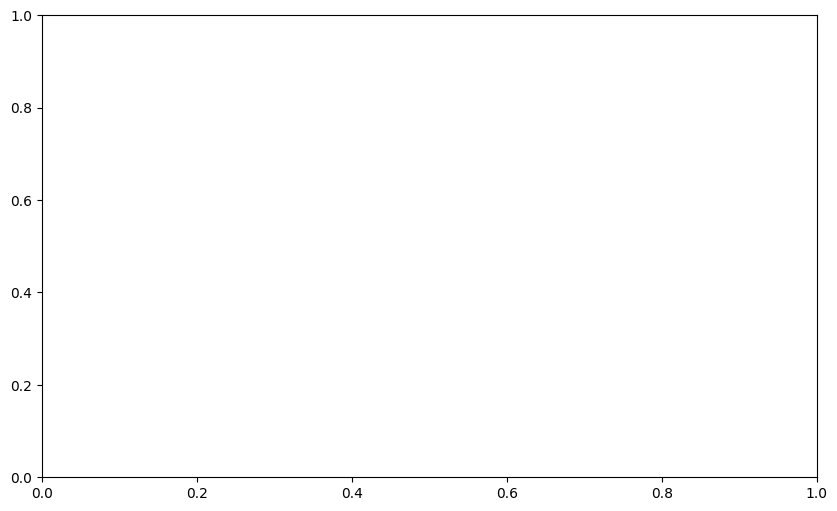

In [ ]:
plt.figure(figsize=(10,6))  # Increased figure size for better visibility

# Plot the original (Random) data in blue
plt.plot(epsilons, accuracies, "o-", color='blue', label="Only CNN")

# Add the SAE data in red
plt.plot(epsilons, sae_accuracies, "*-", color='red', label="CNN with SAE reconstruction")

plt.yticks(np.arange(0, 1.1, step=0.1))
plt.xticks(epsilons)
plt.title("Random - Accuracy vs Epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Accuracy")

# Set y-axis limit from 0 to 1
plt.ylim(0, 1)

# Add the legend
plt.legend()

plt.grid(True, linestyle='--', alpha=0.7)  # Add a grid for better readability

plt.tight_layout()  # Adjust the layout
plt.show()

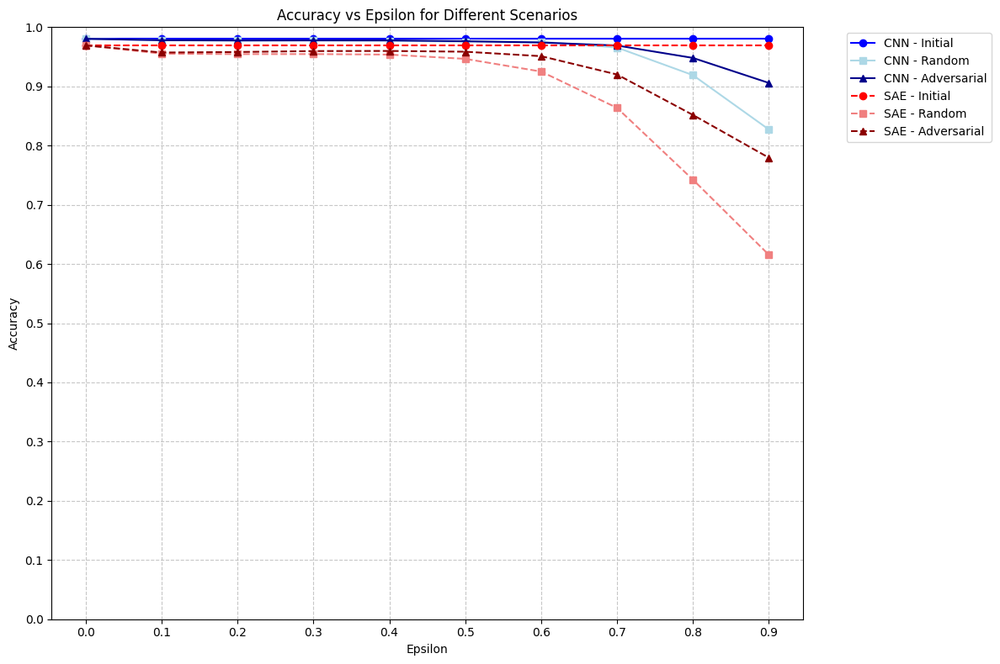

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming epsilons, initial_acc_cnns, initial_acc_saes, random_acc_cnns, random_acc_saes, adv_acc_cnns, adv_acc_saes are defined

plt.figure(figsize=(12, 8))  # Increased figure size for better visibility

# Plot CNN data
plt.plot(epsilons, initial_acc_cnns, "o-", color='blue', label="CNN - Initial")
plt.plot(epsilons, random_acc_cnns, "s-", color='lightblue', label="CNN - Random")
plt.plot(epsilons, adv_acc_cnns, "^-", color='darkblue', label="CNN - Adversarial")

# Plot SAE data
plt.plot(epsilons, initial_acc_saes, "o--", color='red', label="SAE - Initial")
plt.plot(epsilons, random_acc_saes, "s--", color='lightcoral', label="SAE - Random")
plt.plot(epsilons, adv_acc_saes, "^--", color='darkred', label="SAE - Adversarial")

plt.yticks(np.arange(0, 1.1, step=0.1))
plt.xticks(epsilons)
plt.title("Accuracy vs Epsilon for Different Scenarios")
plt.xlabel("Epsilon")
plt.ylabel("Accuracy")

# Set y-axis limit from 0 to 1
plt.ylim(0, 1)

# Add the legend
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.grid(True, linestyle='--', alpha=0.7)  # Add a grid for better readability

plt.tight_layout()  # Adjust the layout
plt.show()

##The plan##
```
1. Create many adversarial images.
2. Feed them to the model and see how activations of the saes change.
3. Quantify this. Try adding random noise to existing images and see what happens to sae activations.
4. Try to see whether there are typical activation landscapes.
5. Document findings.
```



## Available Variables in the Notebook

> ***Note:*** Not up-to-date

> ***Note:*** some of the variables may be commented out

### Key Variables and Their Descriptions:

1. **`reference_test_loader`**
   - **Description**: DataLoader for the MNIST test set, which provides mini-batches of test data. It has `shuffle=False` for reproducibility.
   - **Type**: `DataLoader`
   - **Batch Size**: `128`

2. **`reference_train_loader`**
   - **Description**: DataLoader for the MNIST train set, which provides mini-batches of train data. It has `shuffle=False` for reproducibility.
   - **Type**: `DataLoader`
   - **Batch Size**: `128`

3. **`reference_train_activations`**
   - **Description**: A tensor of activations of the **`cnn_model`** on **`mnist_train`**. Each activation is a one-dimensional tensor with 10 values.
   - **Shape**: `(60000, 10)`

4. **`reference_train_labels`**
   - **Description**: A tensor of labels corresponding to the **`reference_train_activations`**.
   - **Shape**: `(60000,)`

5. **`cnn_model`**
   - **Description**: The Convolutional Neural Network (CNN) model used to generate activations and classify MNIST digits.
   - **Type**: `CNNModel`

6. **`sae`**
   - **Description**: The Sparse Autoencoder model used to reconstruct the activations from the CNN model.
   - **Type**: `SparseAutoencoder`

7. **`combo_model`**
   - **Description**: A model that feeds an image to the **`cnn_model`** and then its activations to the **`sae`**.
   - **Type**: `torch.nn.Sequential`

8. **`train_loader`**
   - **Description**: DataLoader for the MNIST training set, which provides mini-batches of training data.
   - **Type**: `DataLoader`
   - **Batch Size**: `128`

9. **`test_loader`**
   - **Description**: DataLoader for the MNIST test set, which provides mini-batches of test data.
   - **Type**: `DataLoader`
   - **Batch Size**: `128`

10. **`train_loader_SAE`**
   - **Description**: DataLoader containing activations from the CNN model used as inputs for training the Sparse Autoencoder (SAE).
   - **Type**: `DataLoader`
   - **Batch Size**: `128`

11. **`test_loader_SAE`**
   - **Description**: DataLoader containing activations from the CNN model used as inputs for testing the Sparse Autoencoder (SAE).
   - **Type**: `DataLoader`
   - **Batch Size**: `128`

12. **`mnist_train`**
   - **Description**: The MNIST training dataset.
   - **Type**: `datasets.MNIST`
   - **Number of Samples**: `60000`

13. **`mnist_test`**
    - **Description**: The MNIST test dataset.
    - **Type**: `datasets.MNIST`
    - **Number of Samples**: `10000`

14. **`mnist_by_digit_lists`**
    - **Description**: A list of lists where each sublist contains images of a specific digit (0-9) from the MNIST training set.
    - **Type**: `list` of `list` of `torch.Tensor`
    - **Length**: `10` (one sublist for each digit)

15. **`hidden_size`**
    - **Description**: The size of the hidden layer in the Sparse Autoencoder.
    - **Type**: `int`
    - **Value**: `20`

16. **`max_activations_list`**
    - **Description**: A list of lists where each sublist contains indices of images that caused the maximum activation in a specific neuron in the SAE hidden layer.
    - **Type**: `list` of `list`
    - **Length**: `20` (one sublist for each hidden neuron)

17. **`DEVICE`**
    - **Description**: The device (CPU or GPU) used for running the computations.
    - **Type**: `torch.device`

18. **`examples`**
    - **Description**: A list of adversarial examples generated during testing with different epsilon values. Each entry contains tuples.
    - **Type**: `list` of `list` of `tuple`
    - **Structure of a tuple**: <br>`(initial_pred, final_pred, adversarial_image)` or <br>`(initial_pred, final_pred, adversarial_image, initial_image)` if `to_store_init_data=True`.

19. **`epsilons`**
    - **Description**: An array (or any other iterable) of epsilon values used for generating adversarial examples.

20. **`accuracies`**
    - **Description**: A list of accuracy values corresponding to each epsilon during adversarial testing.
    - **Type**: `list` of `float`

21. **`sample`**
    - **Description**: A sample of 10 images of digits from 0 to 9.
    - **Shape**: `(10, 1, 28, 28)` (one image of each digit)

---
